# Проект: отток клиентов банка

**Описание проблемы**:

В условиях конкуренции на финансовом рынке удержание клиентов становится одной из ключевых задач для банков. 

Отток клиентов не только снижает доходы, но и увеличивает затраты на привлечение новых пользователей, поскольку стоимость удержания клиента значительно ниже, чем стоимость привлечения нового.

К тому же важно понимать причины, по которым клиенты уходят из банка для грамотного построения стратегии по их удержанию.

Решение этой задачи позволит банку работать с клиентами, минимизируя потери и повышая общую устойчивость бизнеса.

**Задача**:

В данном проекте решается задача прогнозирования вероятности ухода клиента из банка в ближайшем будущем на основе его демографических характеристик, поведенческих данных и истории взаимодействия с банком.

**Цель** - выявить наиболее уязвимые сегменты клиентской базы, понять факторы, влияющие на отток и предоставить отделу маркетинга обоснованные рекомендации для своевременного вмешательства и повышения лояльности.

**Порядок выполенения работы**:
- Загрузка данных и импорт необходимых библиотек
- Очистка и предобработка датасета оттока клиентов из банка
- Проведение разведочного анализа с целью выявления главных драйверов оттока и составления портретов клиентов (наиболее лояльных и наиболее склонных к оттоку)
- Построение моделей прогнозирования оттока (логистическая регрессия и случайный лес)

**Импорт необходимых библиотек**

In [1]:
from scipy.stats import randint, uniform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as scp
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_validate, RandomizedSearchCV, cross_val_score,
    learning_curve
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import (
    SelectKBest, f_classif, SequentialFeatureSelector
)
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, FunctionTransformer, OrdinalEncoder,
    KBinsDiscretizer
)
from sklearn.metrics import (
    average_precision_score, f1_score, recall_score, brier_score_loss,
    roc_auc_score, classification_report, confusion_matrix, make_scorer,
    precision_score, precision_recall_curve
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import clone

**Процедуры для часто используемого кода**

In [2]:
def distribution(df, name='', bins=15):
    """Выводит распределние признака"""
    plt.figure(figsize=(10,6))
    sns.histplot(df[name], bins=bins, kde=True, color='skyblue')
    plt.title(f'Распределение {name}')
    plt.xlabel(name)
    plt.ylabel('Частота');

In [3]:
def print_boxplot(df, name=''):
    """Строит boxplot для признака"""
    plt.figure(figsize=(6,8))
    sns.boxplot(y=df[name])
    plt.title(f'Boxplot: {name}');

In [4]:
def overlay_hists(df, name=''):
    """
    Строит гистограммы с наложением для признака,
    гистограммы строятся для ушедших и оставшихся
    """
    plt.figure()
    sns.histplot(
        data = df, x=name, hue='Exited', kde=True, 
        bins=30, alpha=0.6,  stat='density'
    )
    plt.title(f"Распределение {name} по группам оттока")
    plt.xlabel(name)
    plt.ylabel("Частота")
    plt.legend(title='отток', labels=['Ушедшие', 'Лояльные'])
    plt.grid(True, linestyle='--', alpha=0.7);

In [5]:
def boxplot_comparison(df, name=''):
    """
    Строит boxplot для ушедших и лояльных по одному признаку для сравнения
    """
    plt.figure()
    sns.boxplot(data=df, x='Exited', y=name)
    plt.title(f"Сравнение {name} между лояльными и ушедшими")
    plt.xlabel("Отток")
    plt.ylabel(name)
    plt.grid(True, linestyle='--', alpha=0.7);

In [6]:
def churn_bars(churn_by_feature, labels, name=''):
    """Строит barplot с указанием процента оттока для каждого бина"""
    plt.figure(figsize=(8,6))
    bars = plt.bar(labels, churn_by_feature['Доля оттока'].values)

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2., height + 0.01, f'{height:.1%}',
            ha='center', va='bottom'
        )

    plt.title(f"Доля оттока по группам {name}")
    plt.xlabel(f'Группа {name}')
    plt.ylabel("Доля оттока")
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.ylim(0, 1)
    plt.show()

In [7]:
def impact(df, fe_1, fe_2):
    """
    Строит таблицу, которая отражает вклад той или иной группы в отток,
    просто считает, сколько человек из группы покинули банк
    """
    pt = df.pivot_table(
    index=[fe_1, fe_2],
    values='Exited', aggfunc=['count','mean'], observed=False
    )
    pt['Вклад'] = pt[('count','Exited')] * pt[('mean','Exited')]
    print(pt.sort_values([('Вклад')], ascending=False).reset_index())

In [8]:
def pivot_and_heatmap(df, fe_1, fe_2):
    """
    Строит сводную таблицу для долей оттока по группам и визуализирует ее с
    помощью heatmap
    """
    #Сводная таблица
    pivot = df.pivot_table(
    index=fe_1, columns=fe_2, 
    values='Exited', aggfunc='mean', observed=False
    ).round(2)
    print('Сводная таблица:')
    print(pivot)

    #Визуализация
    plt.figure()
    sns.heatmap(pivot, annot=True, cmap='coolwarm', center=0.2, fmt='.1%',
               cbar_kws={'label': 'Доля оттока'})
    plt.title(f'Доля оттока: {fe_1} x {fe_2}')
    plt.xlabel(fe_2)
    plt.ylabel(fe_1);

In [9]:
def get_model_metrics(model, X_test, y_test):
    """Производит расчет метрик для модели"""
    y_proba = model.predict_proba(X_test)[:, 1]

    #PR-AUC
    pr_auc = average_precision_score(y_test, y_proba)

    #ROC AUC
    roc_auc = roc_auc_score(y_test, y_proba)

    #Precision и Recall
    y_pred = (y_proba >= 0.5).astype(int)
    precision_val = precision_score(y_test, y_pred)
    recall_val = recall_score(y_test, y_pred)

    return{
        'Test PR AUC': pr_auc,
        'Test ROC AUC': roc_auc,
        'Precision': precision_val,
        'Recall': recall_val
    }

In [10]:
def print_scores(name, y_true, y_pred, y_proba):
    """Выводит основные метрики для модели"""
    
    pr_auc = average_precision_score(y_true, y_proba)
    roc_auc = roc_auc_score(y_true, y_proba)
    f1 = f1_score(y_true, y_pred)
    print(f"""
    {name} -> PR AUC: {pr_auc:.4f}, ROC AUC: {roc_auc:.4f}, F1: {f1:.4f}
    """)

Загрузка данных

In [11]:
data = pd.read_csv("Customer-Churn.csv")

In [12]:
df = pd.DataFrame(data)

Рассмотрим признаки, входящие в датасет

In [13]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain',
       'Satisfaction Score', 'Card Type', 'Point Earned'],
      dtype='object')

**Получили следующие признаки**:

`RowNumber` — соответствует номеру записи (строки).

`CustomerId` — содержит уникальные случайные значения, id клиента.

`Surname` — фамилия клиента.

`CreditScore` — кредитный рейтинг клиента.

`Geography` — местоположение клиента.

`Gender` — пол клиента.

`Age` — возраст.

`Tenure` — количество лет, в течение которых клиент является клиентом банка.

`Balance` — баланс на счетах клиента.

`NumOfProducts` — количество используемых клиентом продуктов банка.

`HasCrCard` — наличие у клиента кредитной карты.

`IsActiveMember` — признак активного клиента.

`EstimatedSalary` — прогнозируемый доход.

`Exited` — покинул ли клиент банк.

`Complain` — наличие у клиента жалобы.

`Satisfaction Score` — оценка, предоставляемая клиентом за качество услуг.

`Card Type` — тип карты, которой владеет клиент.

`Point Earned` — баллы, начисленные клиенту за использование кредитной карты.

Очевидно, что признаки, которые отвечают за номер записи в датасете и фамилию клиента, на отток влиять не будут, поэтому можно их убрать

In [14]:
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace=True)

# Предобработка

Выведем первые 5 строк датасета

In [15]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,709.0,France,Female,36,4,174056.41,1,1,1.0,40449.79,0,0.0,2.0,SILVER,752
1,534.0,France,Male,27,9,0.00,2,1,0.0,161344.13,0,0.0,2.0,PLATINUM,925
2,597.0,Spain,Male,24,0,108058.07,2,1,1.0,187826.11,0,0.0,3.0,PLATINUM,676
3,659.0,Germany,Female,26,9,84870.44,1,1,1.0,NaN,0,0.0,4.0,DIAMOND,727
4,794.0,Spain,Female,28,5,0.00,2,0,1.0,86699.98,0,0.0,3.0,DIAMOND,734


Рассмотрим последние 5 строк датасета

In [16]:
df.tail()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
19995,788.0,France,Male,34,1,64191.06,2,1,0.0,37217.73,1,0.0,3.0,DIAMOND,222
19996,576.0,France,Male,42,4,137429.76,2,0,0.0,137330.80,0,0.0,2.0,GOLD,740
19997,711.0,France,Female,29,3,130181.47,2,1,0.0,31811.44,0,0.0,5.0,SILVER,719
19998,647.0,Spain,Male,32,9,80958.36,1,1,1.0,128590.73,0,0.0,4.0,GOLD,540
19999,745.0,Germany,Male,29,10,0.00,1,1,0.0,124895.79,0,0.0,2.0,GOLD,207


Также рассмотрим общую информацию о датасете

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         16874 non-null  float64
 1   Geography           20000 non-null  object 
 2   Gender              20000 non-null  object 
 3   Age                 20000 non-null  int64  
 4   Tenure              20000 non-null  int64  
 5   Balance             20000 non-null  float64
 6   NumOfProducts       20000 non-null  int64  
 7   HasCrCard           20000 non-null  int64  
 8   IsActiveMember      19230 non-null  float64
 9   EstimatedSalary     17541 non-null  float64
 10  Exited              20000 non-null  int64  
 11  Complain            19230 non-null  float64
 12  Satisfaction Score  19230 non-null  float64
 13  Card Type           20000 non-null  object 
 14  Point Earned        20000 non-null  int64  
dtypes: float64(6), int64(6), object(3)
memory usage: 2.3+

Сразу видно, что в датасете присутствуют пропуски

Проверим имена признаков и типы данных

In [18]:
df.dtypes

CreditScore           float64
Geography              object
Gender                 object
Age                     int64
Tenure                  int64
Balance               float64
NumOfProducts           int64
HasCrCard               int64
IsActiveMember        float64
EstimatedSalary       float64
Exited                  int64
Complain              float64
Satisfaction Score    float64
Card Type              object
Point Earned            int64
dtype: object

Есть данные, которые по предположению должны иметь целочисленный тип, но имеют тип float, что может быть связано с наличием пропусков

Проверим баланс классов

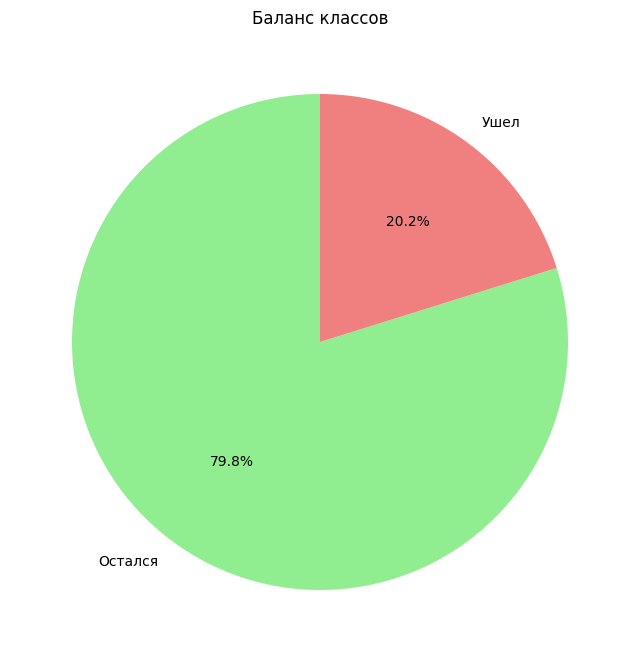

In [19]:
counts = df['Exited'].value_counts()
labels = ['Остался', 'Ушел']
colors = ['lightgreen', 'lightcoral']

plt.figure(figsize=(8, 10))
plt.pie(counts, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title("Баланс классов");

Имеет место дисбаланс, что нужно будет учитывать при дальнейшем обучении моделей

Проверим наличие дубликатов

In [20]:
num_of_duplicates = df.duplicated().sum()
print(num_of_duplicates) #Число дубликатов. Удалять нечего

0


Явных дубликатов нет, удалять нечего

## Пропуски

Посмотрим на число пропусков по каждому признаку

In [21]:
df.isnull().sum()

CreditScore           3126
Geography                0
Gender                   0
Age                      0
Tenure                   0
Balance                  0
NumOfProducts            0
HasCrCard                0
IsActiveMember         770
EstimatedSalary       2459
Exited                   0
Complain               770
Satisfaction Score     770
Card Type                0
Point Earned             0
dtype: int64

Рассмотрим также процентное соотношение

In [22]:
df.isnull().sum() / len(df) * 100

CreditScore           15.630
Geography              0.000
Gender                 0.000
Age                    0.000
Tenure                 0.000
Balance                0.000
NumOfProducts          0.000
HasCrCard              0.000
IsActiveMember         3.850
EstimatedSalary       12.295
Exited                 0.000
Complain               3.850
Satisfaction Score     3.850
Card Type              0.000
Point Earned           0.000
dtype: float64

Рассмотрим карту пропусков, чтобы отследить, по каким признакам пропуски совпадают

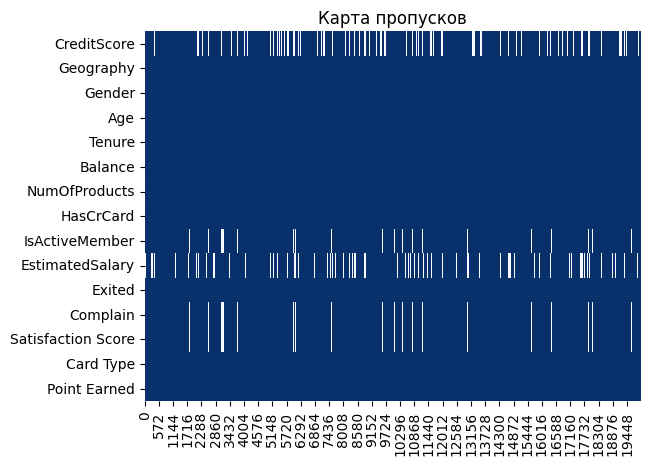

In [23]:
sns.heatmap(df.isna().T, cmap='Blues_r', annot=False, cbar=False)
plt.title('Карта пропусков');

Видно, что в некоторых прзнаках есть совпадения (именно - Complain и Satisfaction score)

### CreditScore

Поскольку нет возможности как-либо восстановить значения кредитного рейтинга, то заменим пропуски медианой и введем флаг пропуска данных, чтобы знать, что у конкретного клиента был пропуск (возможно, что он новичок)

In [24]:
df['Missed_CreditScore'] = df['CreditScore'].isnull().astype(np.int64)
df['CreditScore'] = df['CreditScore'].fillna(df['CreditScore'].median())

### IsActiveMember

Для данного столбца нет каких-либо других признаков, по которым можно было бы восстановить активность клиента. Поэтому можно попробовать заменить модой и ввести флаг, отвечающий за пропуск

In [25]:
df['Missed_IsActiveMember'] = df['IsActiveMember'].isnull().astype(np.int64)
df['IsActiveMember'] = df['IsActiveMember'].fillna(df['IsActiveMember'].mode()[0])

### Estimated Salary

In [26]:
df['EstimatedSalary'].describe()

count    1.754100e+04
mean     1.412469e+05
std      3.779394e+05
min     -1.993075e+05
25%      4.955338e+04
50%      1.013711e+05
75%      1.520528e+05
max      5.123361e+06
Name: EstimatedSalary, dtype: float64

Рассмотрим распределение

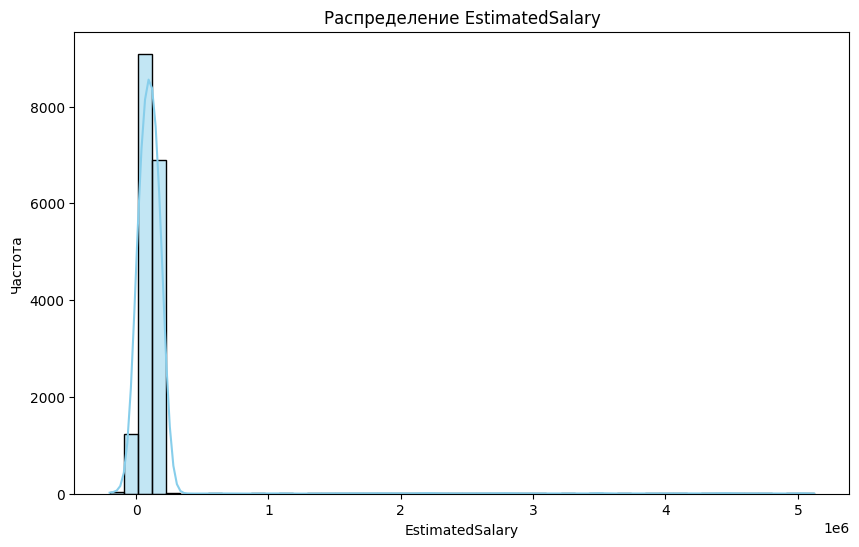

In [27]:
distribution(df, name='EstimatedSalary', bins=50)

В действительности могут быть клиенты с очень высоким доходом, поэтому распределение имеет длинный хвост справа, что выглядит реалистично

Теперь рассмотрим выбросы

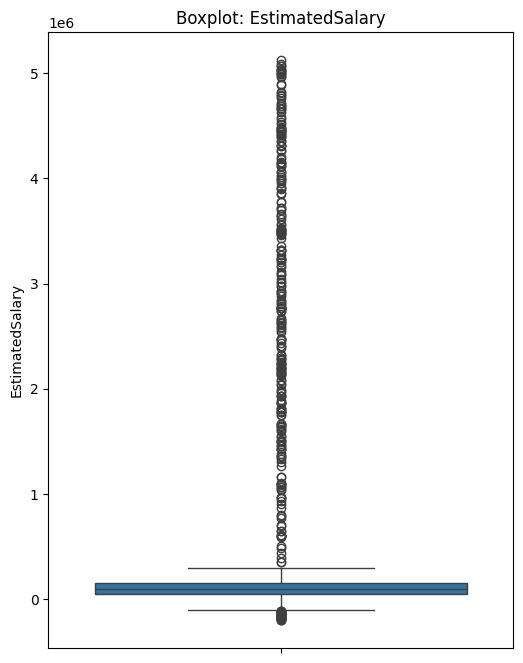

In [28]:
print_boxplot(df, name='EstimatedSalary')

Распределение признака выглядит правдоподобно. Выбросы вполне могут отражать реальную картину (людей с прогнозируемым доходом больше 200 тысяч около 1,4%). Пропуски будут заполнены медианой, потому что она довольно устойчива по отношению к выбросам и отражает "типичного" клиента, но лучше добавить флаг пропуска, чтобы модель знала о том, что у клиента пропущен доход (возможно клиент новый или неактивный).

In [29]:
df['Missed_EstimatedSalary'] = df['EstimatedSalary'].isnull().astype(np.int64)
df['EstimatedSalary'] = df['EstimatedSalary'].fillna(df['EstimatedSalary'].median())

### Complain и Satisfaction Score

In [30]:
df[['Complain', 'Satisfaction Score']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Complain            19230 non-null  float64
 1   Satisfaction Score  19230 non-null  float64
dtypes: float64(2)
memory usage: 312.6 KB


In [31]:
no_complain_scored = df[(df['Complain'] == 0) & 
    (df['Satisfaction Score'].notnull())]
print("Количество клиентов без жалобы, но с оценкой:", 
      len(no_complain_scored))

Количество клиентов без жалобы, но с оценкой: 15142


Есть случаи, в которых Complain = 0 (жалобы не было), но при этом в Satisfaction Score присутствует оценка. Это может указывать либо на ошибку при заполнении, либо на ошибочную интерпретацию признака. Поскольку таких данных много, то удалять их нет смысла. Данные признаки могут оказаться важны при построении модели и при анализе, поэтому убирать признаки тоже кажется неразумным. Можно выделить несколько групп клиентов:

- есть жалоба, есть оценка
- нет жалобы, есть оценка
- пропущенные значения

In [32]:
complain_scored = df[(df['Complain'] == 1) & 
                                        (df['Satisfaction Score'].notnull())]

complain_NaNs = df[df['Complain'].isnull()]#Клиенты с пропусками в Complain

satisfactionScore_NaNs = df[df['Satisfaction Score'].isnull()]#С пропусками 
                                                        #в Satisfaction Score

print(f"Совпадают ли клиенты с пропусками в Complain и пропусками в " 
        f"Satisfaction Score: {complain_NaNs.equals(satisfactionScore_NaNs)}")

print("\nЕсть ли пересечения у no_complain_scored и complain_scored: ",
    len(pd.merge(no_complain_scored, complain_scored, how='inner')) > 0)

print(print("\nЕсть ли пересечения у no_complain_scored и complain_NaNs: ",
    len(pd.merge(no_complain_scored, complain_NaNs, how='inner')) > 0))

print(print("\nЕсть ли пересечения у complain_scored и complain_NaNs: ",
    len(pd.merge(complain_scored, complain_NaNs, how='inner')) > 0))

print(f"\nСумма количества клиентов по трем группам: ", 
len(no_complain_scored) + len(complain_scored) + len(complain_NaNs))

Совпадают ли клиенты с пропусками в Complain и пропусками в Satisfaction Score: True

Есть ли пересечения у no_complain_scored и complain_scored:  False

Есть ли пересечения у no_complain_scored и complain_NaNs:  False
None

Есть ли пересечения у complain_scored и complain_NaNs:  False
None

Сумма количества клиентов по трем группам:  20000


Полученные группы попарно не пересекаются и количество клиентов в сумме равно исходному, то есть разделяют датасет. Теперь введем флаги:

- Для Complain: complain_1 (была ли жалоба) и missed_complain (был ли пропуск)
- Для Satisfaction Score: missed_SatisfactionScore (был ли пропуск)

Пропуски в Satisfaction Score попробуем заполнить медианой по самой большой группе (Complain = 0). Complain после этого можно будет удалить

In [33]:
df['Complain_1'] = (df['Complain'] == 1).astype(int)
df['missed_complain'] = df['Complain'].isnull().astype(int)

df['missed_SatisfactionSCore'] = df['Satisfaction Score'].isnull().astype(int)

median = df[df['Complain'] == 0]['Satisfaction Score'].median()
print(f"Медиана: {median}")

df['Satisfaction Score'] = df['Satisfaction Score'].fillna(median)

Медиана: 3.0


In [34]:
df.isnull().sum()

CreditScore                   0
Geography                     0
Gender                        0
Age                           0
Tenure                        0
Balance                       0
NumOfProducts                 0
HasCrCard                     0
IsActiveMember                0
EstimatedSalary               0
Exited                        0
Complain                    770
Satisfaction Score            0
Card Type                     0
Point Earned                  0
Missed_CreditScore            0
Missed_IsActiveMember         0
Missed_EstimatedSalary        0
Complain_1                    0
missed_complain               0
missed_SatisfactionSCore      0
dtype: int64

### Gender

Проверим уникальные значения данного признака

In [35]:
df['Gender'].unique()

array(['Female', 'Male', 'na'], dtype=object)

Видно, что здесь также присутствуют пропуски

In [36]:
df['Gender'].value_counts(dropna=False)

Gender
Male      10879
Female     9043
na           78
Name: count, dtype: int64

Всего 78 таких клиентов (или 0.39%), а значит можно их просто удалить

In [37]:
df = df.drop(index=df[df['Gender'] == 'na'].index)

## Выбросы

Теперь рассмотрим и обработаем выбросы в данных

In [38]:
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned',
       'Missed_CreditScore', 'Missed_IsActiveMember', 'Missed_EstimatedSalary',
       'Complain_1', 'missed_complain', 'missed_SatisfactionSCore'],
      dtype='object')

### Age

Boxplot

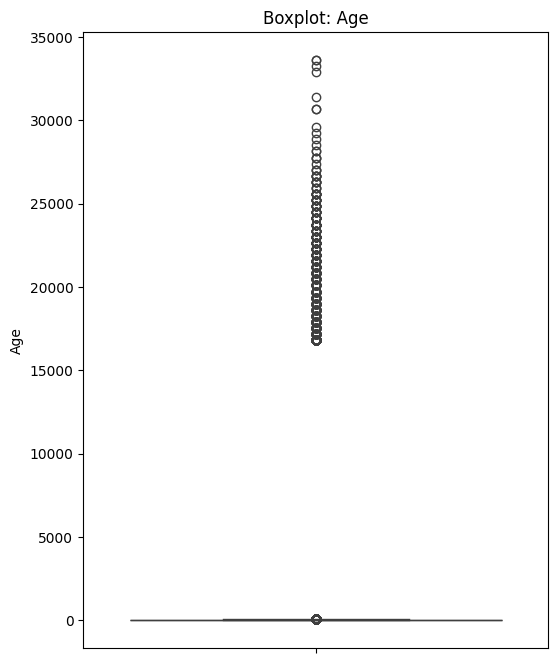

In [39]:
print_boxplot(df, name='Age')

Видно,что имеются огромные значения для возраста, это явно является ошибкой. Будем считать выбросом возраст больше 100 лет. Проверим, сколько всего таких клиентов.

In [40]:
over_100_years = len(df[df['Age'] > 100])
print(f"""
Число клиентов, которым больше ста лет: {over_100_years}
\nВ процентах: {over_100_years/len(df) * 100:.4f}
""")


Число клиентов, которым больше ста лет: 1091

В процентах: 5.4764



Всего получается 1091 клиент или 5.5%, что довольно много. 

Сравним долю оттока среди нормальных и среди аномальных данных.

In [41]:
df['AgeGroup'] = df['Age'].apply(lambda x: 'upper_100' if x > 100 
                                else 'lower_100')

churn_by_age = df.groupby('AgeGroup')['Exited'].agg(
    count='size',
    churn_sum = 'sum',
    churn_rate = 'mean'
).round(3)

print(churn_by_age)

churn_upper_100 = df[df['Age'] > 100]['Exited'].sum()
print(f"""
\nПроцент выбросов, среди всех ушедших: {churn_upper_100/df['Exited'].sum() 
                                                                    *100:.4f}
""")

           count  churn_sum  churn_rate
AgeGroup                               
lower_100  18831       3730       0.198
upper_100   1091        289       0.265


Процент выбросов, среди всех ушедших: 7.1908



Разница в оттоке составляет +6.6 п.п. (или примерно на 33% выше, чем у "нормальных" клиентов), то есть сам сигнал об "аномальном" возрасте может быть сигналом о риске оттока.

Хотя такие выбросы могут быть связаны ошибками (например, в датах). Поэтому при моделровании стоит аккуратно обращаться с данным признаком, либо же вообще удалить выбросы из данных, чтобы модель не обучалась под шум.

Пока что заменим аномальные значения на 100 (для того, чтобы распределение было более интерпертируемым и для уменьшения влияния выбросов) и добавим флаг аномального возраста, чтобы модель учитывала, что это ненастоящие столетние, но возможно важная группа.

In [42]:
df['AbnormalAge'] = (df['Age'] > 100).astype(np.int64)
df['Age'] = df['Age'].clip(upper=100)

Проверим выбросы и распределение

Распределение

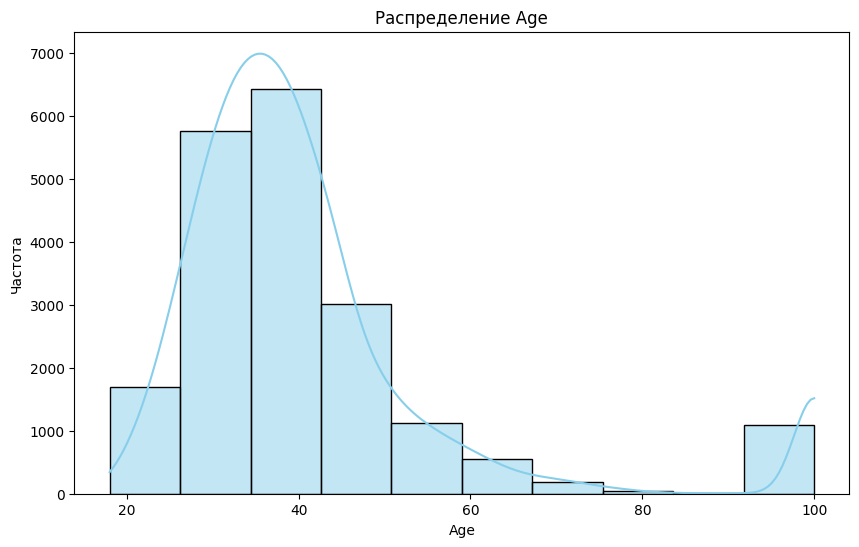

In [43]:
distribution(df, name='Age', bins=10)

Выбросы

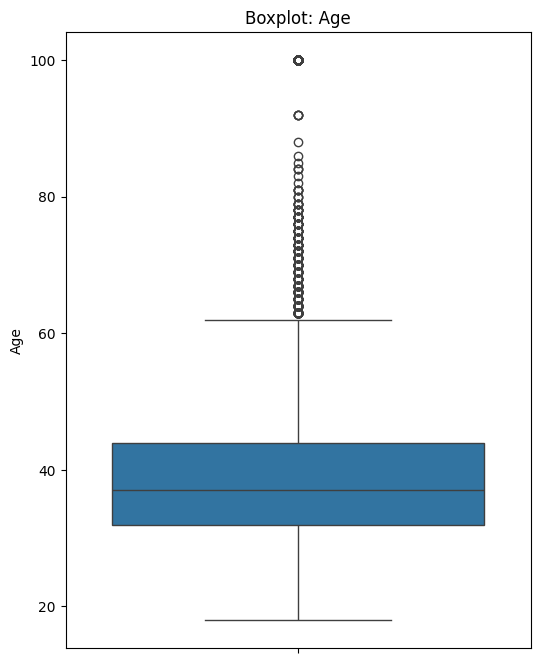

In [44]:
print_boxplot(df, name='Age')

Статистики

In [45]:
df['Age'].describe()

count    19922.000000
mean        41.418281
std         17.049121
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max        100.000000
Name: Age, dtype: float64

Видно, что ситуация значтельно улучшилась

Теперь очистим датасет от промежуточных признаков (AgeGroup)

In [46]:
df.drop('AgeGroup', axis=1, inplace=True)

### CreditScore

In [47]:
df['CreditScore'].describe()

count    19922.000000
mean       649.726533
std         88.852722
min        350.000000
25%        596.000000
50%        651.000000
75%        705.000000
max        850.000000
Name: CreditScore, dtype: float64

Статистики находятся в пределах нормы, аномальных значений быть не должно

Построим распредление и график для поиска выбросов

Распределение

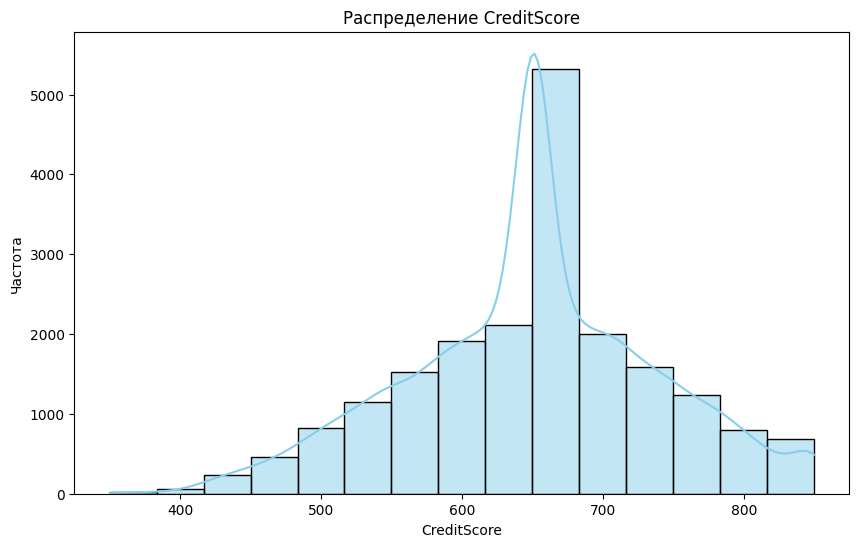

In [48]:
distribution(df, name='CreditScore')

Пик получился из-за замены пропусков на медиану. В целом распределение выглядит реалистично

График выбросов

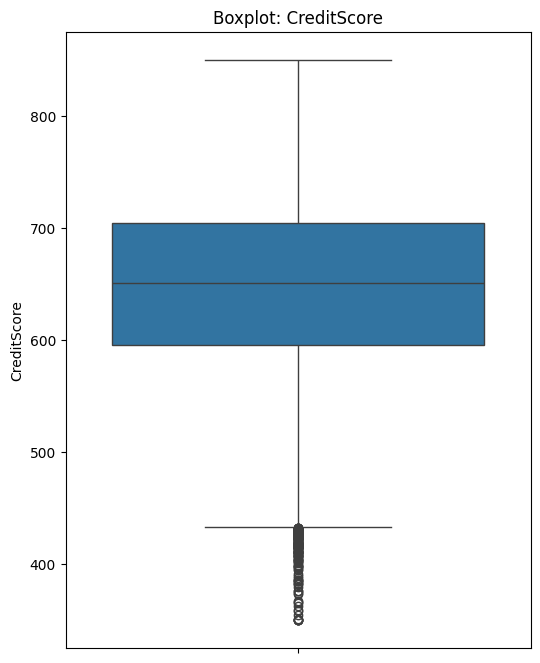

In [49]:
print_boxplot(df, name='CreditScore')

Видно, что есть клиенты с низким кредитным рейтингом (скопление точен снизу). В принципе такое может иметь место в реальности

Посмотрим, сколько вообще выбросов внизу.

In [50]:
Q1 = df['CreditScore'].quantile(0.25)
Q3 = df['CreditScore'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5*IQR
low_score = df[df['CreditScore'] < lower_limit]
print(f"Число клиентов с низким рейтингом: {len(low_score)}")
print(f"В процентах: {len(low_score) / len(df) * 100:.2f}")

Число клиентов с низким рейтингом: 175
В процентах: 0.88


Видно, что клиентов с низким кредитным рейтингом (который считается выбросом) достаточно мало. Вывод: все нормально.

Итак, для данного признака получили:

- Диапазон: 350-850 (в пределах нормы)

- Распределение имеет пик в медиане (651) из-за замены пропущенных значений на медиану (логистическая регрессия и случайный лес устойчивы к таким выбросам, особенно, если есть флаг пропуска)

- Выбросы внизу - реальные клиенты с плохой кредитной историей

- Дальнейшая обработка пока не требуется 

### Tenure

Статистики

In [51]:
df['Tenure'].describe()

count    19922.000000
mean         5.414918
std          2.964088
min          0.000000
25%          3.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: Tenure, dtype: float64

Распределение

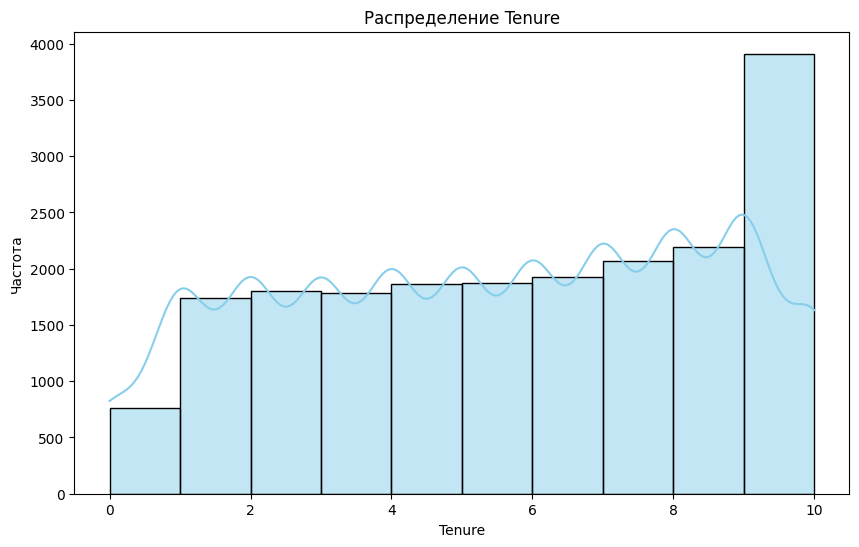

In [52]:
distribution(df, name='Tenure', bins=10)

Получили:

- мало клиентов с 0-1 год - новички

- равномерность с 1-9 лет - типично

- пик на 9-10 лет - возможно просто обрезка (всем клиентам с 10+ лет в банке присваивается значение Tenure = 10). Это не должно вызвать проблем у логистической регрессии или случайного леса

Выбросов, ошибок и пропусков данный признак не имеет. Вывод: оставить так, как есть

### Balance

Статистики

In [53]:
df['Balance'].describe()

count     19922.000000
mean      77556.806624
std       59315.869988
min           0.000000
25%        8185.225000
50%       85256.600000
75%      123752.400000
max      250898.090000
Name: Balance, dtype: float64

Распределение

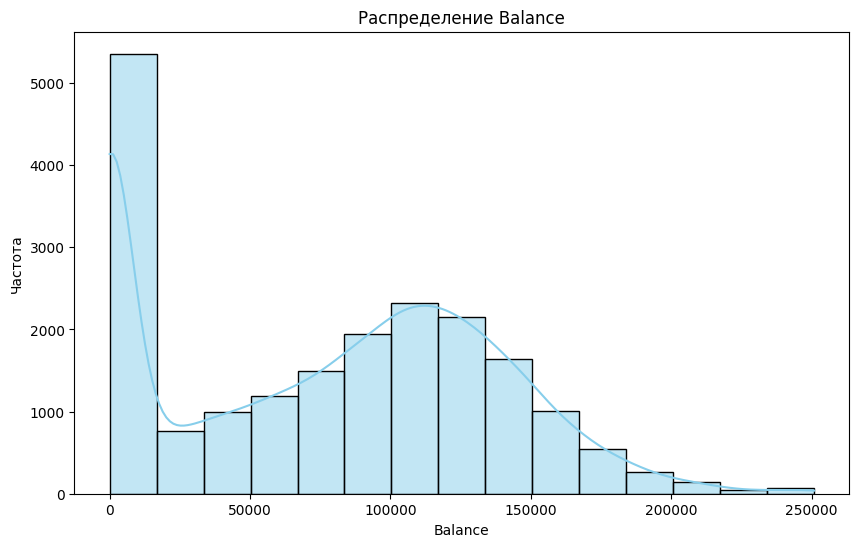

In [54]:
distribution(df, name='Balance')

График выбросов

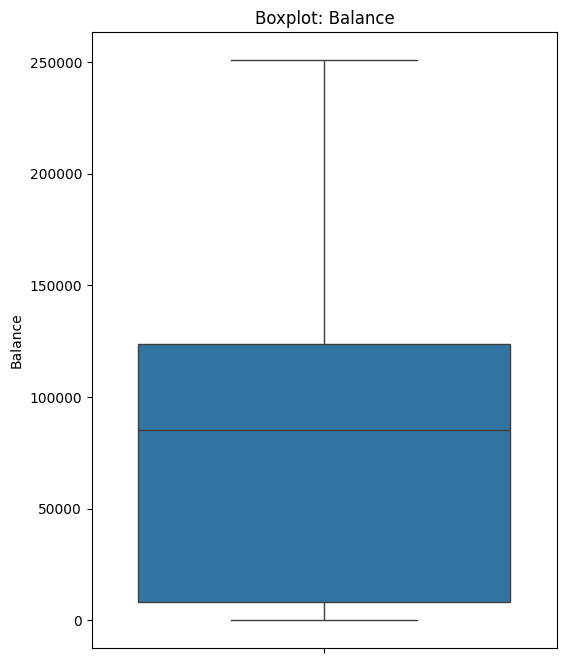

In [55]:
print_boxplot(df, name='Balance')

График не показыввает выбросов сверху, однако все равно стоит попробовать поискать из вручную

In [56]:
Q1 = df['Balance'].quantile(0.25)
Q3 = df['Balance'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5*IQR

print(f"Число выбросов сверху: {len(df[df['Balance'] > upper_limit])}")

Число выбросов сверху: 0


Убедились, что выбросов действительно нет

Получаем:

- диапазон от 0 до 250898 - реалистичен.

- пик в нуле на графике распределения означает, что около 25% клиентов имеют баланс от 0 до 10 тыс., что вполне реалистично (много клиентов с малым или вовсе нулевым балансом).

- смещение среднего и медианы - следствие ассимметрии.

- Boxplot прижат к низу - большинство значений там.

- Нет признаков ошибок

  Вывод: с данными ничего не нужно делать

### NumOfProducts

Статистики

In [57]:
df['NumOfProducts'].describe()

count    19922.000000
mean         1.539755
std          0.585752
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max          4.000000
Name: NumOfProducts, dtype: float64

Распредление

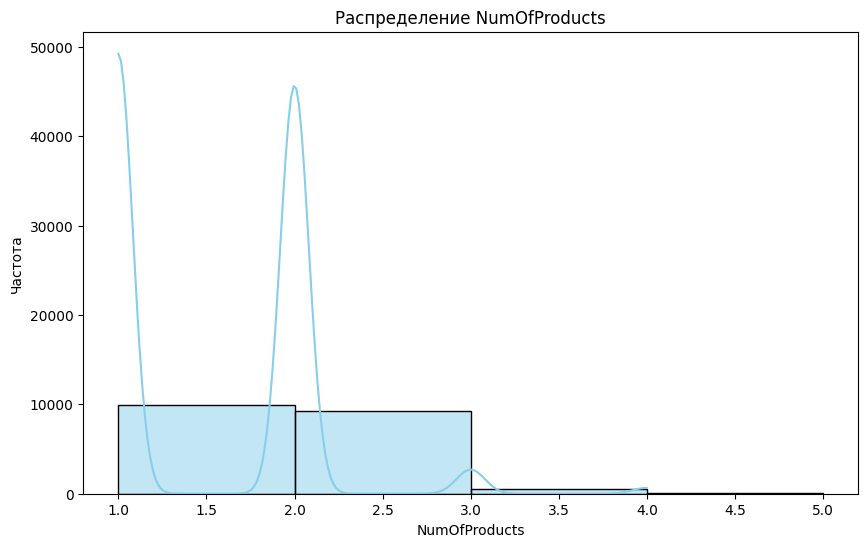

In [58]:
distribution(df, name='NumOfProducts', bins=[1, 2, 3, 4, 5])

Распределение показывает, что большиснтво клиентов используют либо один продукт (например, дебетовый счет), либо 2 продукта (например, дебетовый + кредитный). Реже клиенты используют 3 или 4 продукта (обычному клиенту они могут быть не нужны, а вот, например, бизнесу вполне).

Вывод: оставить данные такими, какие есть

### EstimatedSalary

Статистики

In [59]:
df['EstimatedSalary'].describe()

count    1.992200e+04
mean     1.364811e+05
std      3.548706e+05
min     -1.993075e+05
25%      5.677328e+04
50%      1.013711e+05
75%      1.451306e+05
max      5.123361e+06
Name: EstimatedSalary, dtype: float64

Распределение

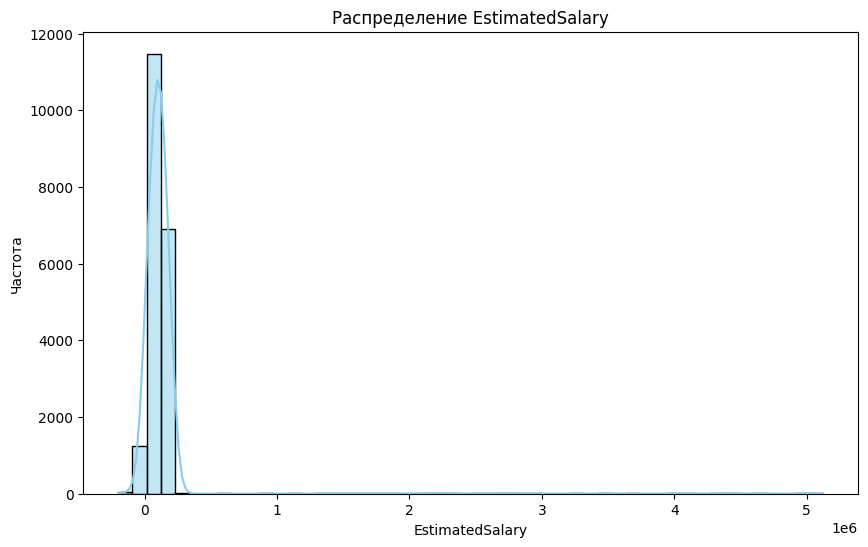

In [60]:
distribution(df, name='EstimatedSalary', bins=50)

График выбросов

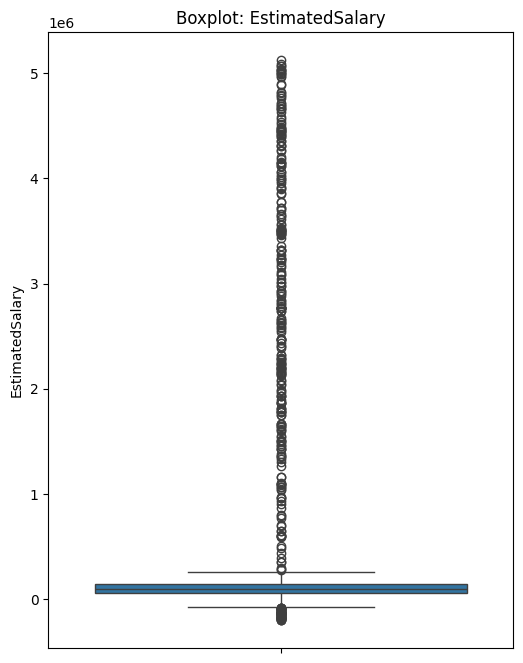

In [61]:
print_boxplot(df, name='EstimatedSalary')

Проверим нетипичные значения

In [62]:
negative = df[df['EstimatedSalary'] < 0]
zero = df[df['EstimatedSalary'] == 0]

Q1 = df['EstimatedSalary'].quantile(0.25)
Q3 = df['EstimatedSalary'].quantile(0.75)
IQR = Q3 -Q1
high_limit = Q3 + 1.5*IQR
high = df[df['EstimatedSalary'] > high_limit]

print(f"Отрицательных: {len(negative)}")
print(f"Нулевых: {len(zero)}")
print(f"Высоких: {len(high)}")

Отрицательных: 81
Нулевых: 0
Высоких: 274


Отрицательный прогнозируемый доход выглядит чем-то нереальным, если это не чистая прибыль или баланс. Отрицательные значения можно обработать (можно заменить их медианой и ввести флаг, что доход был отрицательным), хотя с ними тоже лучше быть аккуратней, чтобы модель не подстраивалась под данные выбросы (возможно их придется вовсе удалить)

In [63]:
df['NegativeSalary'] = (df['EstimatedSalary'] < 0).astype(int)

df['EstimatedSalary'] = df['EstimatedSalary'].where(df['EstimatedSalary'] >= 
                                                                            0)
median_salary = df['EstimatedSalary'].median()
df['EstimatedSalary'] = df['EstimatedSalary'].fillna(median_salary)

In [64]:
df['EstimatedSalary'].describe()

count    1.992200e+04
mean     1.372839e+05
std      3.545476e+05
min      1.158000e+01
25%      5.767719e+04
50%      1.013711e+05
75%      1.451306e+05
max      5.123361e+06
Name: EstimatedSalary, dtype: float64

Получили:

- диапазон - от 11.58 до 5.1 миллиона
- 81 клиент имел отрицательную оценку дохода, было принято решение заменить эти значения на медиану, но с сохранением информации о том, что их оценка была отрицательной.
- выскоие значения реалистичны (богатые клиенты)


### Point Earned

Статистики

In [65]:
df['Point Earned'].describe()

count    19922.000000
mean       613.764080
std        236.159777
min        119.000000
25%        413.000000
50%        622.000000
75%        819.000000
max       1000.000000
Name: Point Earned, dtype: float64

Статистики выглядят реалистично

Рассмотрим распределение

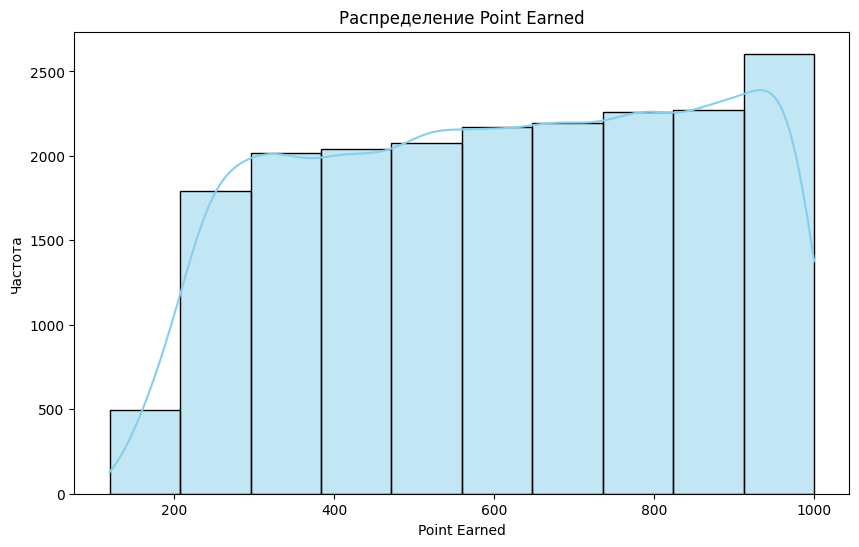

In [66]:
distribution(df, name='Point Earned', bins=10)

Рассмотрим boxplot

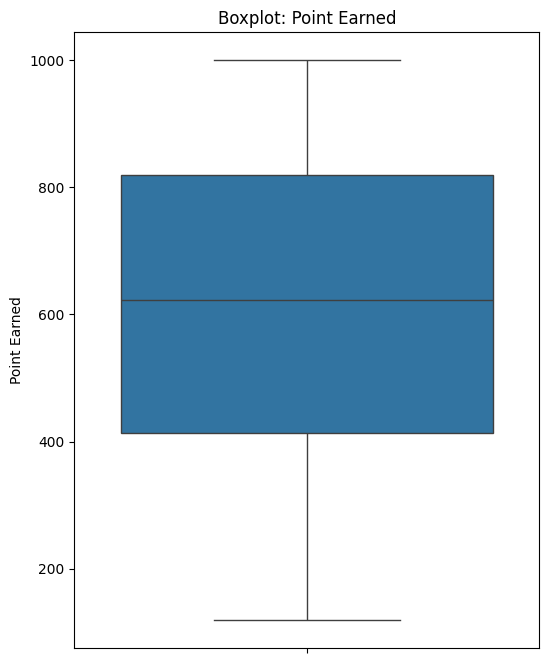

In [67]:
print_boxplot(df, name='Point Earned')

Boxplot выбросов не показывает. В принципе данные достаточно похожи на реальные

Итак, получили: 
- Диапазон - от 119 до 1000
- Максимум 1000 может означать, что либо число баллов по кредитной карте ограничено, либо искуссвтенно обрезается на значении 1000

Решение - не изменять признак

# Анализ

## Числовые признаки

### CreditScore

Статистика по лояльным клиентам

In [68]:
df[df['Exited'] == 0]['CreditScore'].describe()

count    15903.000000
mean       650.739546
std         88.426302
min        355.000000
25%        597.000000
50%        651.000000
75%        706.000000
max        850.000000
Name: CreditScore, dtype: float64

Статистика по ушедшим

In [69]:
df[df['Exited'] == 1]['CreditScore'].describe()

count    4019.000000
mean      645.718089
std        90.420245
min       350.000000
25%       592.000000
50%       651.000000
75%       703.000000
max       850.000000
Name: CreditScore, dtype: float64

Видно, что по описательным статистикам группы не особо отличаются (разница между средними 5 пунктов, медианы совпадают, остальные статистики отличаются также мало)

Попробуем визуализировать распределение

Построим гистограммы с наложением

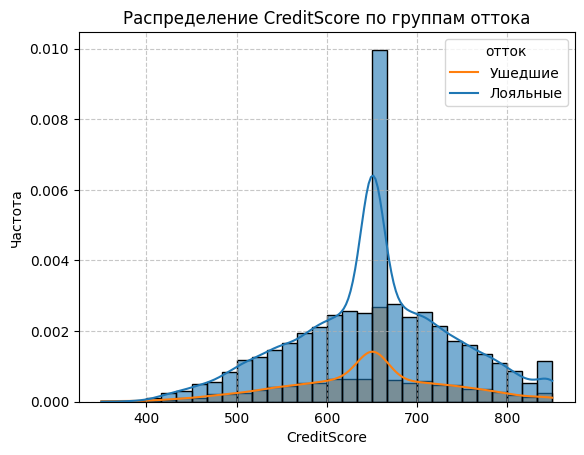

In [70]:
overlay_hists(df, name='CreditScore')

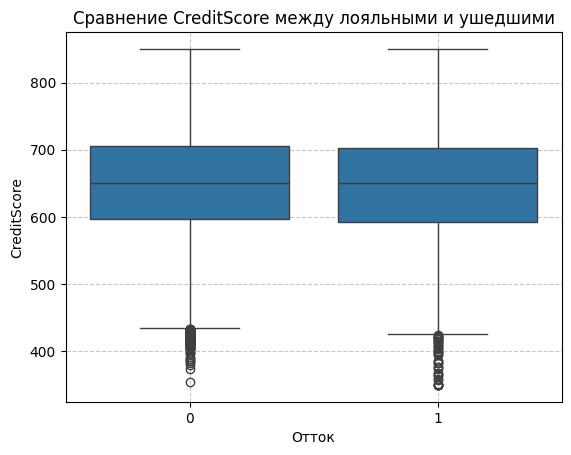

In [71]:
boxplot_comparison(df, name='CreditScore')

Графики распределений показывают, что пики находятся примерно в одном и том же месте, что может говорить о том, что кредитный рейтинг не особо влияет на отток. То же самое показывает и boxplot

Попробуем оценить влияние пропусков на отток

In [72]:
churn_rate_missed = df[df['Missed_CreditScore'] == 1]['Exited'].mean() * 100
churn_rate_not_missed = df[df['Missed_CreditScore'] == 0]['Exited'].mean()*100

print(f"Процент оттока, если CreditScore пропущен: {churn_rate_missed:.4f}")
print(f"Процент оттока, если CreditScore известен: " 
                f"{churn_rate_not_missed:.4f}")

Процент оттока, если CreditScore пропущен: 21.7391
Процент оттока, если CreditScore известен: 19.8846


Проведем бининг и рассмотрим долю оттока в каждой группе

In [73]:
bins = [0, 500, 600, 670, 700, 800, 860]
labels = ['<500', '500-600', '600-670', '670-700', '700-800', '800+']

df['credit_score_group'] = pd.cut(df['CreditScore'], bins=bins, labels=labels, 
                                                                right=False)

churn_by_score = df.groupby(
    by='credit_score_group',
    observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_score.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_score)

                    Доля оттока  Количество клиентов
credit_score_group                                  
<500                   0.236444                 1125
500-600                0.205109                 4032
600-670                0.206791                 7539
670-700                0.177966                 1888
700-800                0.195264                 4307
800+                   0.184287                 1031


Визуализация

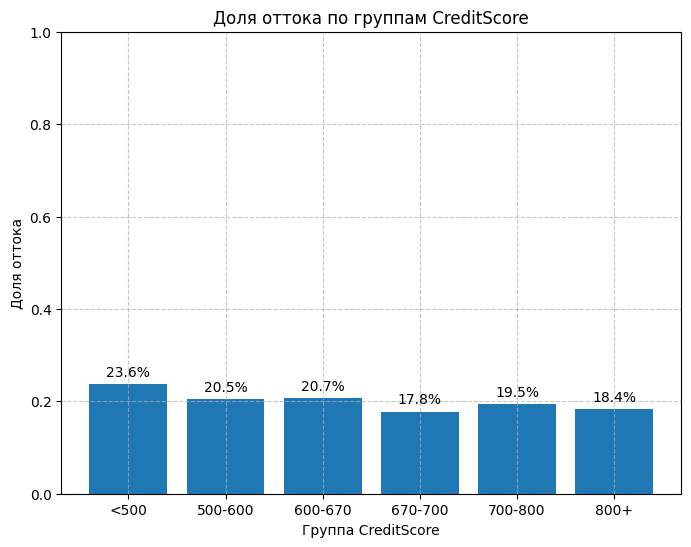

In [74]:
churn_bars(churn_by_score, labels=labels, name='CreditScore')

df.drop('credit_score_group', axis=1, inplace=True)

Видно, что в группах доля оттока примерно на равном уровне. Скорее всего данный признак сам по себе не влияет на отток, но может быть важным в комбинациях с другими.

Флаг пропуска может влиять на отток и возможно его стоит оставить, клиенты с пропущенным значением имеют более высокий уровень оттока (на 2 п.п. больше). Это может значить, что либо клиенты, которые собираются уйти, перестают взаимодействовать, либо слишком быстро уходят, либо это может быть технический сбой у проблемных клиентов.

### Age

Статистики для лояльных клиентов

In [75]:
df[df['Exited'] == 0]['Age'].describe()

count    15903.000000
mean        40.114444
std         16.610976
min         18.000000
25%         31.000000
50%         36.000000
75%         43.000000
max        100.000000
Name: Age, dtype: float64

Статистики для ушедших клиентов

In [76]:
df[df['Exited'] == 1]['Age'].describe()

count    4019.000000
mean       46.577507
std        17.769644
min        18.000000
25%        36.000000
50%        43.000000
75%        51.000000
max       100.000000
Name: Age, dtype: float64

По описательным статистикам видно, что средний возраст ушедших на 6 лет больше, чем у лояльных.

Гистограммы

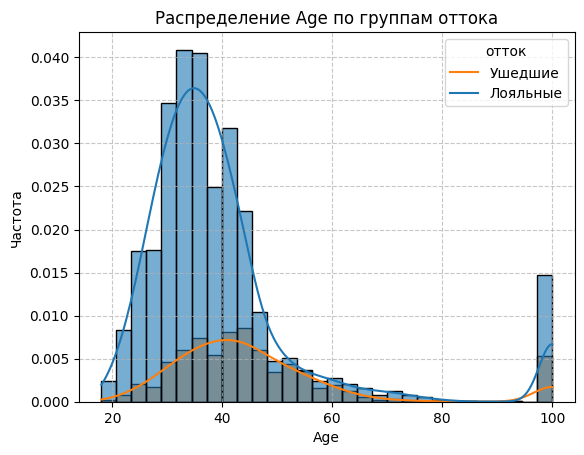

In [77]:
overlay_hists(df, name='Age')

Видно, что пики на графиках явно отличаются (для ушедших он находится правее), что может говорить, что чаще уходят те, кто старше (от 40 до 50 лет)

Построим boxplot

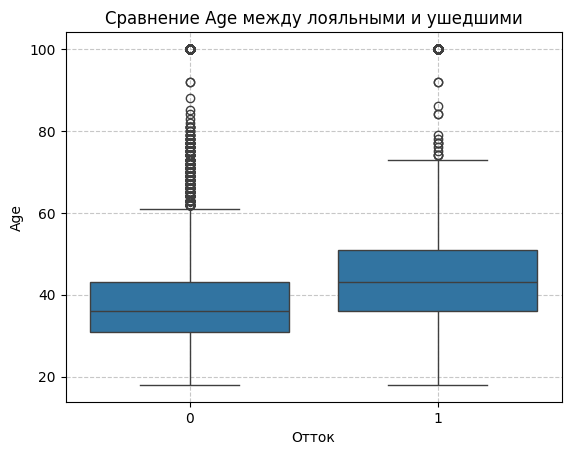

In [78]:
boxplot_comparison(df, name='Age')

У ушедших boxplot более приподнят, что может говорить о том, что чаще уходят более старшие клиенты.

Проанализируем выбросы (=100)

In [79]:
churn_rate_outliers = df[df['AbnormalAge'] == 1]['Exited'].mean() * 100
churn_rate_not_outliers = df[df['AbnormalAge'] == 0]['Exited'].mean()*100

print("Процент оттока, если Age - выброс: ", churn_rate_outliers)
print("Процент оттока, если Age нормальный: ", churn_rate_not_outliers)

Процент оттока, если Age - выброс:  26.48945921173236
Процент оттока, если Age нормальный:  19.807763793744357


Показывает достаточно большую долю оттока среди клиентов с выбросами

Рассмотрим долю оттока по возрастным группам

In [80]:
bins = [0, 30, 40, 45, 65, 100, 101]
labels = ['<30', '30-40', '40-45', '45-65', '65+', 'Abnormal']

df['age_group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

churn_by_age = df.groupby(
    by='age_group',
    observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_age.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_age)

           Доля оттока  Количество клиентов
age_group                                  
<30           0.095502                 3424
30-40         0.145529                 8287
40-45         0.223930                 3318
45-65         0.401396                 3438
65+           0.203297                  364
Abnormal      0.264895                 1091


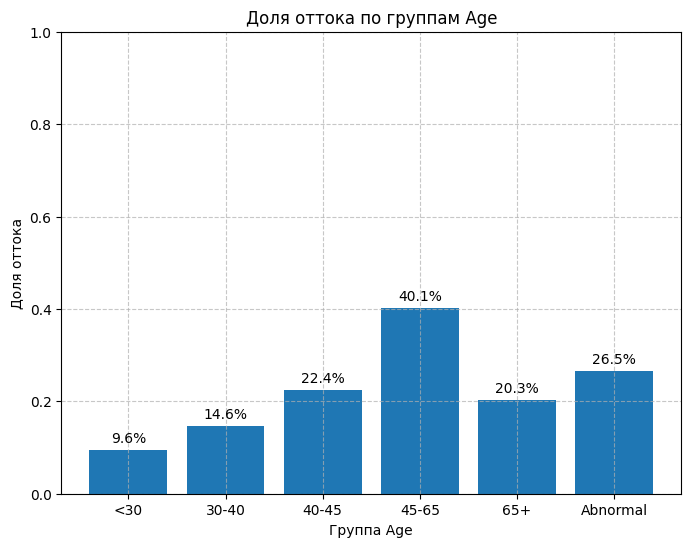

In [81]:
churn_bars(churn_by_feature=churn_by_age, labels=labels, name='Age')

df.drop('age_group', axis=1, inplace=True)

Анализ показал, что отток клиентов неравномерен по возрасту (самым лояльным киентам до 30 лет, группа риска - от 45 лет до 65). Почти каждый второй клиент в возрастном сегменте от 45 до 65 лет в зоне риска Так же повышенный отток среди клиентов с аномальным возрастом (26.4%). Отток в группе 45-65 лет может указывать на проблемы в цифровой доступности или на отсутсвие персонализированного обслуживания для зрелых клиентов.

Статистическая проверка:
- Пик в распределении в возрасте от 40 до 45 лет, скорее указывает на то, что таких клиентов в целом много (но отрезок меньше), а значит и больше тех, кто уходит
- Графики boxplot также отражают то, что среди возрастных клиентов много тех, кто уходит, на это также может указывать и значение среднего возраста для ушедших

Теперь попробуем проанализировать различные комбинации признаков

##### Age + NumOfProducts

Сводная таблица:
NumOfProducts     1     2     3     4
age_group                            
<30            0.12  0.06  0.35  0.15
30-40          0.17  0.11  0.39  0.44
40-45          0.27  0.14  0.52  0.67
45-65          0.47  0.24  0.80  0.92
65+            0.25  0.11  0.45  1.00
100            0.26  0.26  0.31  0.30


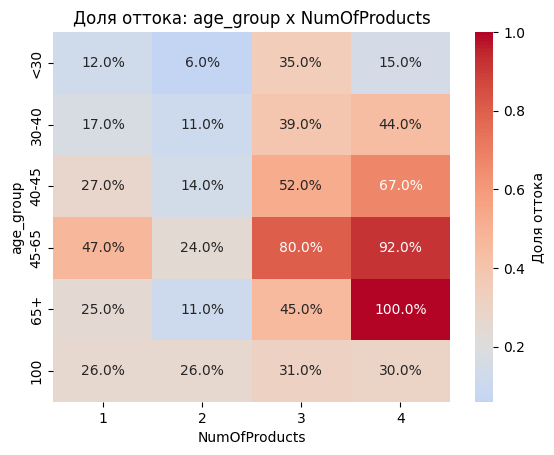

In [82]:
bins = [0,30, 40, 45, 65, 100, 110]
labels = ['<30', '30-40', '40-45', '45-65', '65+', '100']
df['age_group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

pivot_and_heatmap(df, fe_1='age_group', fe_2='NumOfProducts')

Видно, что в некоторых группах высокая доля оттока, однако это может быть связано с тем, что в группах может быть мало клиентов, но при этом все они ушли, поэтому нужно посмотреть кроме доли оттока также вклад каждой группы в отток (рассмотрим количество ушедших)

In [83]:
impact(df, fe_1='age_group', fe_2='NumOfProducts')

   age_group NumOfProducts  count      mean  Вклад
                           Exited    Exited       
0      45-65             1   1958  0.474974  930.0
1      30-40             1   3969  0.171832  682.0
2      40-45             1   1681  0.273647  460.0
3      30-40             2   4099  0.106611  437.0
4      45-65             2   1309  0.236058  309.0
5      40-45             2   1498  0.138184  207.0
6        <30             1   1589  0.120201  191.0
7        100             1    586  0.262799  154.0
8        100             2    460  0.263043  121.0
9        <30             2   1743  0.061962  108.0
10     45-65             3    134  0.798507  107.0
11     30-40             3    180  0.388889   70.0
12     40-45             3    115  0.521739   60.0
13       65+             1    197  0.253807   50.0
14     45-65             4     37  0.918919   34.0
15       <30             3     72  0.347222   25.0
16       65+             2    154  0.110390   17.0
17     30-40             4     

Видно, что наиболее "опасные" группы - это "45-65 лет + 1 продукт" и "45-65 лет + 3 продукта" (они вносят наибольший вклад)

##### Age + Geography

Пересечем возраст и географию, чтобы выявить группы риска

Сводная таблица:
Geography  France  Germany  Spain
age_group                        
<30          0.08     0.13   0.10
30-40        0.12     0.20   0.14
40-45        0.20     0.29   0.20
45-65        0.41     0.46   0.33
65+          0.10     0.30   0.24
100          0.26      NaN    NaN


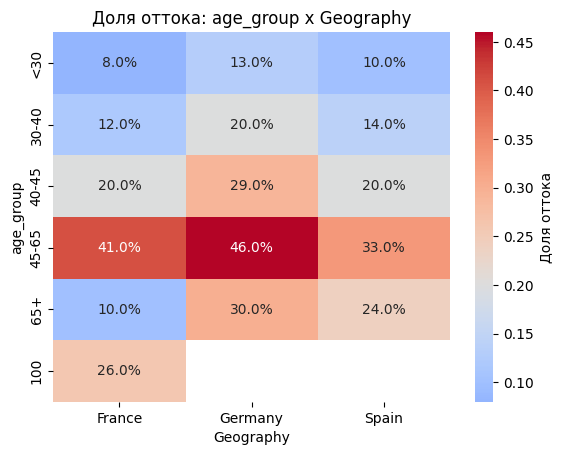

In [84]:
pivot_and_heatmap(df, fe_1='age_group', fe_2='Geography')

Это еще раз подтверждает, что возраст 45-65 лет является основной группой риска в каждой стране (хотя больше всего конечно в Германии), также интерес может представлять группа "40-45 + Germany". Также видно, что выбросы (=100) сконцентрированы только во Франции, что может указывать на какую-то региональную техническую ошибку.

##### Age + Gender

Проверим доли оттока по возрастным группам и полу

Сводная таблица:
Gender     Female  Male
age_group              
<30          0.12  0.08
30-40        0.17  0.13
40-45        0.25  0.20
45-65        0.44  0.36
65+          0.24  0.18
100          0.29  0.25


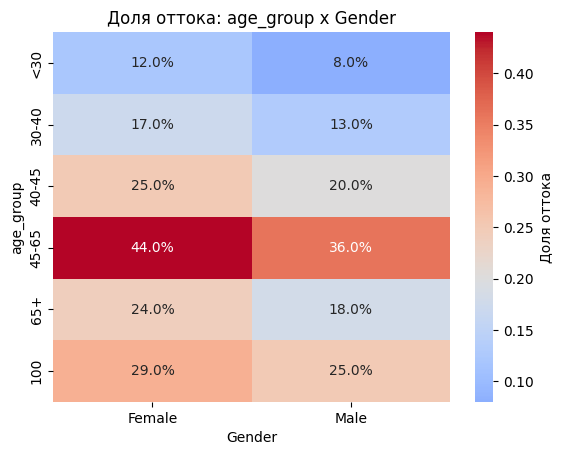

In [85]:
pivot_and_heatmap(df, fe_1='age_group', fe_2='Gender')

Здесь также видно, что основная группа оттока 45-65 лет, и в этой группе доля больше у женщин

In [86]:
impact(df, fe_1='age_group', fe_2='Gender')

   age_group  Gender  count      mean  Вклад
                     Exited    Exited       
0      45-65  Female   1662  0.444043  738.0
1      45-65    Male   1776  0.361486  642.0
2      30-40  Female   3683  0.168070  619.0
3      30-40    Male   4604  0.127498  587.0
4      40-45  Female   1511  0.249504  377.0
5      40-45    Male   1807  0.202546  366.0
6        <30  Female   1541  0.116807  180.0
7        100    Male    610  0.247541  151.0
8        <30    Male   1883  0.078067  147.0
9        100  Female    481  0.286902  138.0
10       65+  Female    165  0.236364   39.0
11       65+    Male    199  0.175879   35.0


Видно, что вклад в отток также больше у женщин 45-65 лет.

##### Age + Balance

Сводная таблица:
balance_group     0  до 25k  25k-75k  75k-125k  125k-150k  150k-200k  200k+
age_group                                                                  
<30            0.05    0.11     0.10      0.10       0.12       0.12   0.26
30-40          0.10    0.15     0.17      0.15       0.17       0.17   0.30
40-45          0.15    0.20     0.21      0.25       0.28       0.23   0.38
45-65          0.36    0.30     0.31      0.44       0.46       0.41   0.38
65+            0.10    0.20     0.36      0.23       0.32       0.14   0.14
100            0.29    0.25     0.26      0.26       0.31       0.22   0.38


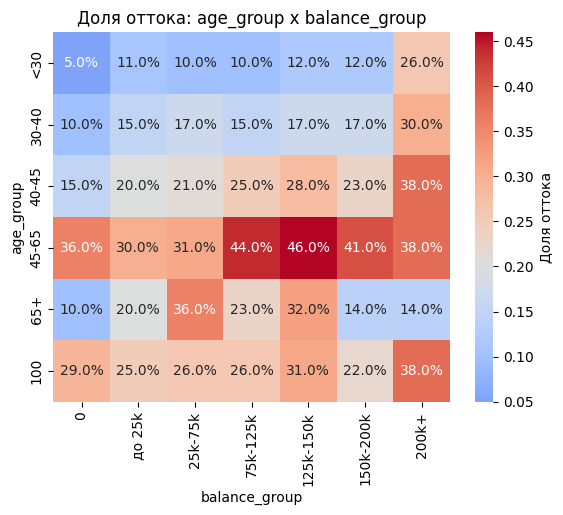

In [87]:
bins = [0, 1, 25_000, 75_000, 125_000, 150_000, 200_000, 300_000]
labels = ['0', 'до 25k', '25k-75k', '75k-125k', '125k-150k','150k-200k', 
                                                                    '200k+']

df['balance_group'] = pd.cut(df['Balance'], bins=bins, labels=labels, 
                                                                 right=False)

pivot_and_heatmap(df, fe_1='age_group', fe_2='balance_group')

Видно, что и здесь основная группа оттока 45-65 лет. Есть также и другие группы, которые могут представлять интерес, но в целом все выглядит так, как будто клиенты с высоким доходом более сколнны к оттоку независимо от возраста.

##### Age + IsActiveMember

Сводная таблица:
IsActiveMember   0.0   1.0
age_group                 
<30             0.11  0.09
30-40           0.17  0.13
40-45           0.26  0.19
45-65           0.53  0.29
65+             0.54  0.12
100             0.29  0.25


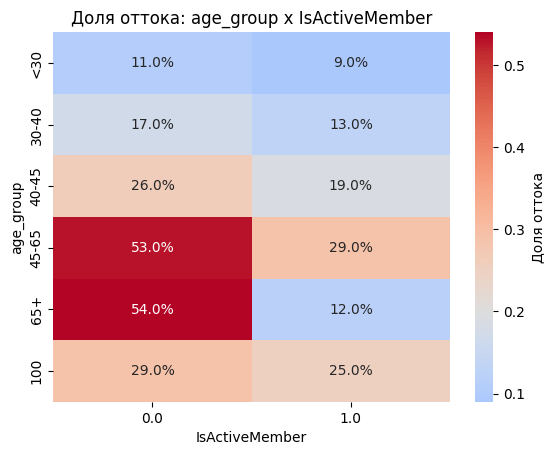

In [88]:
pivot_and_heatmap(df, fe_1='age_group', fe_2='IsActiveMember')

Видно, что самые "опасные" группы - это "45-65" и "65+" среди неактивных. Рассмотрим их вклад

In [89]:
impact(df, fe_1='age_group', fe_2='IsActiveMember')

   age_group IsActiveMember  count      mean  Вклад
                            Exited    Exited       
0      45-65            0.0   1573  0.527654  830.0
1      30-40            0.0   3944  0.166329  656.0
2      45-65            1.0   1865  0.294906  550.0
3      30-40            1.0   4343  0.126641  550.0
4      40-45            0.0   1598  0.264706  423.0
5      40-45            1.0   1720  0.186047  320.0
6        <30            0.0   1630  0.106748  174.0
7        100            1.0    632  0.246835  156.0
8        <30            1.0   1794  0.085284  153.0
9        100            0.0    459  0.289760  133.0
10       65+            0.0     74  0.540541   40.0
11       65+            1.0    290  0.117241   34.0


Видно, что неактивные пользователи в возрасте от 45 до 65 лет вносят огромный вклад в отток. Это очень важный сигнал для бизнеса. Нужно стараться вернуть активность таких клиентов

##### Age + Complain

Сводная таблица:
Complain    0.0   1.0
age_group            
<30        0.04  0.57
30-40      0.06  0.63
40-45      0.06  0.72
45-65      0.09  0.87
65+        0.05  0.75
100        0.20  0.49


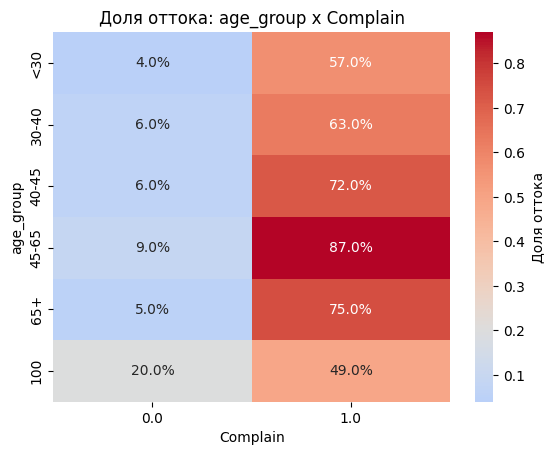

In [90]:
pivot_and_heatmap(df, fe_1='age_group', fe_2='Complain')

Видно, что наличие жалобы очень хорошо разделяет клиентов на ушедших и лояльных, но жалоба в 45-65 лет является огромным риском (доля оттока 87%).

##### Age + Satisfaction Score

Сводная таблица:
Satisfaction Score   1.0   2.0   3.0   4.0   5.0
age_group                                       
<30                 0.09  0.10  0.09  0.09  0.10
30-40               0.14  0.16  0.14  0.13  0.14
40-45               0.23  0.24  0.22  0.22  0.21
45-65               0.39  0.43  0.37  0.42  0.39
65+                 0.25  0.23  0.18  0.20  0.17
100                 0.29  0.30  0.20  0.27  0.29


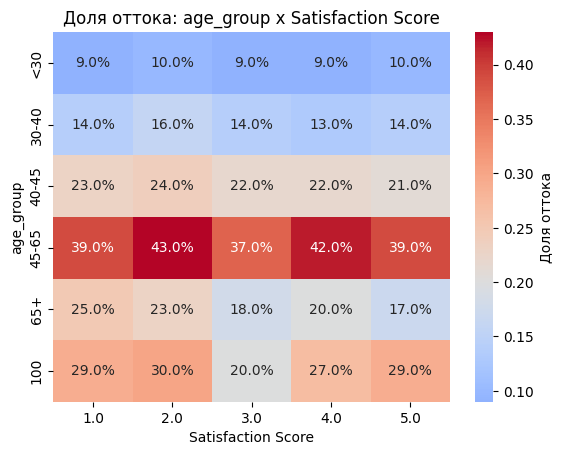

In [91]:
pivot_and_heatmap(df, fe_1='age_group', fe_2='Satisfaction Score')

Также подтверждает, что основная группа риска - 45-65 лет, но ничего нового такая комбинация не дала.

##### Age + Geography + Complain

In [92]:
pivot = df.pivot_table(
    index='age_group',
    columns=['Geography', 'Complain'],
    values='Exited',
    aggfunc='mean',
    observed=False
).round(2)

print('Доля оттока: Возраст x Страна x Жалоба:')
print(pivot)

Доля оттока: Возраст x Страна x Жалоба:
Geography France       Germany       Spain      
Complain     0.0   1.0     0.0   1.0   0.0   1.0
age_group                                       
<30         0.04  0.52    0.05  0.57  0.04  0.67
30-40       0.06  0.59    0.07  0.70  0.06  0.62
40-45       0.06  0.72    0.07  0.75  0.05  0.68
45-65       0.02  0.95    0.12  0.86  0.11  0.78
65+         0.00  1.00    0.06  0.72  0.13  0.64
100         0.20  0.49     NaN   NaN   NaN   NaN


Визуализация

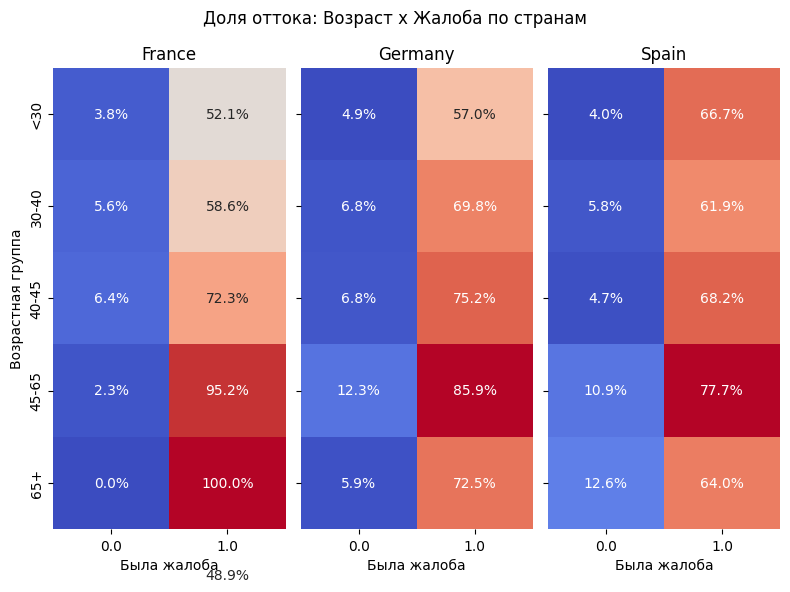

In [93]:
countries = ['France', 'Germany', 'Spain']

fig, axes = plt.subplots(1, 3, figsize=(8, 6), sharey=True)
for i, country in enumerate(countries):
    df_country = df[df['Geography']==country]
    pivot_country = df_country.pivot_table(
        index='age_group', columns='Complain', values='Exited', 
        aggfunc='mean', observed=False
    )

    sns.heatmap(
        pivot_country,
        annot=True,
        fmt='.1%',
        cmap='coolwarm',
        cbar=False,
        ax=axes[i]
    )
    axes[i].set_title(f'{country}')
    axes[i].set_xlabel('Была жалоба')
    if i==0:
        axes[i].set_ylabel('Возрастная группа')
    else:
        axes[i].set_ylabel('')

plt.suptitle('Доля оттока: Возраст x Жалоба по странам')
plt.tight_layout()
plt.show()

Видно, что во Франции проблемы с клиентами с жалобами начинаются с возраста более 40 лет, в Германии и Франции есть проблемы с удовлетворением жалоб в каждой возрастной группе. Посмотрим вклад в отток каждой группы.

In [94]:
df_grouped = df.groupby(
    by=['age_group', 'Geography', 'Complain'], 
    observed=False
).agg(
      churn_rate=('Exited', 'mean'),
      n_clients=('Exited', 'size')
).reset_index()

df_grouped['ImpactScore'] = df_grouped['churn_rate'] * df_grouped['n_clients']
df_grouped = df_grouped.sort_values('ImpactScore', ascending=False)

print('ТОП рисковых групп: Возраст x Страна x Жалоба')
print(df_grouped.round(1).head(10))

ТОП рисковых групп: Возраст x Страна x Жалоба
   age_group Geography  Complain  churn_rate  n_clients  ImpactScore
21     45-65   Germany       1.0         0.9        576        495.0
19     45-65    France       1.0         1.0        439        418.0
7      30-40    France       1.0         0.6        524        307.0
9      30-40   Germany       1.0         0.7        401        280.0
23     45-65     Spain       1.0         0.8        354        275.0
13     40-45    France       1.0         0.7        329        238.0
15     40-45   Germany       1.0         0.8        286        215.0
6      30-40    France       0.0         0.1       3616        204.0
11     30-40     Spain       1.0         0.6        289        179.0
30       100    France       0.0         0.2        731        143.0


Видно, что самая рисковая группа - это клиенты из Германии с наличием жалобы возраста 45-65 лет. Среди французов той же возрастной группы с жалобой также много клиентов склонных к уходу.

Ключевые "находки":
- 45-65 лет + жалоба + любая страна (отток 77% - 95%)
- 45-65 лет + 1 продукт (отток 53%, но большой вклад)
- 45-65 лет + 3 продукта (отток 80%)
- 45-65 лет + баланс 125k-150k и 200k+ (отток 40% и более)

### Tenure

Сравним статистики у ушедших и у оставшихся

Ушедшие

In [95]:
df[df['Exited'] == 1]['Tenure'].describe()

count    4019.000000
mean        5.386415
std         2.994058
min         0.000000
25%         3.000000
50%         6.000000
75%         8.000000
max        10.000000
Name: Tenure, dtype: float64

Оставшиеся

In [96]:
df[df['Exited'] == 0]['Tenure'].describe()

count    15903.000000
mean         5.422122
std          2.956517
min          0.000000
25%          3.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: Tenure, dtype: float64

Статистики сильного различия не показали

Гистограммы

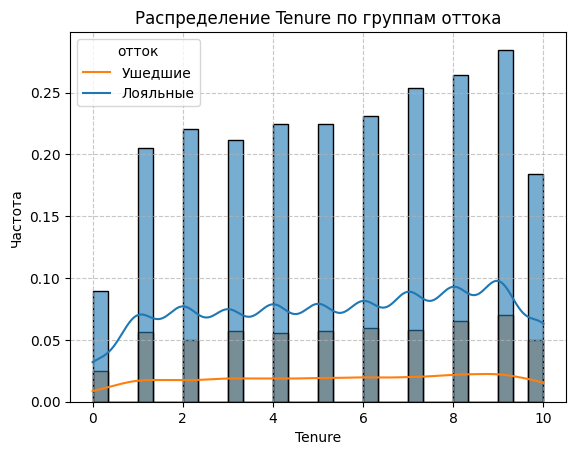

In [97]:
overlay_hists(df, name='Tenure')

Гистограммы пиков не показали.

Рассмотрим boxplot'ы

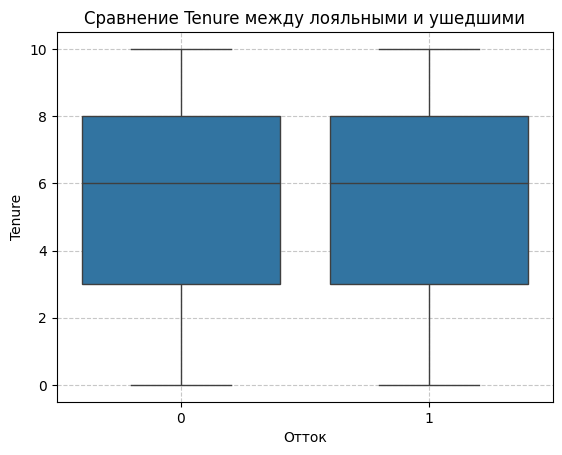

In [98]:
boxplot_comparison(df, name='Tenure')

Boxplot тоже не показал какого-то особо различия в группах

Попробуем разбить на отрезки по Tenure и посмотреть долю оттока в каждом отрезке

In [99]:
bins = [0, 2, 4, 6, 8, 10, 12]
labels = ['0-2', '2-4', '4-6', '6-8', '8-10', '10 и более']
df['Tenure_group'] = pd.cut(df['Tenure'], bins=bins, labels=labels, 
                                                                right=False)

churn_by_Tenure = df.groupby(
    by='Tenure_group',
    observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_Tenure.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_Tenure)
df.drop('Tenure_group',  axis=1, inplace=True)

              Доля оттока  Количество клиентов
Tenure_group                                  
0-2              0.216032                 2495
2-4              0.199052                 3587
4-6              0.200642                 3738
6-8              0.195402                 4002
8-10             0.198063                 4544
10 и более       0.214653                 1556


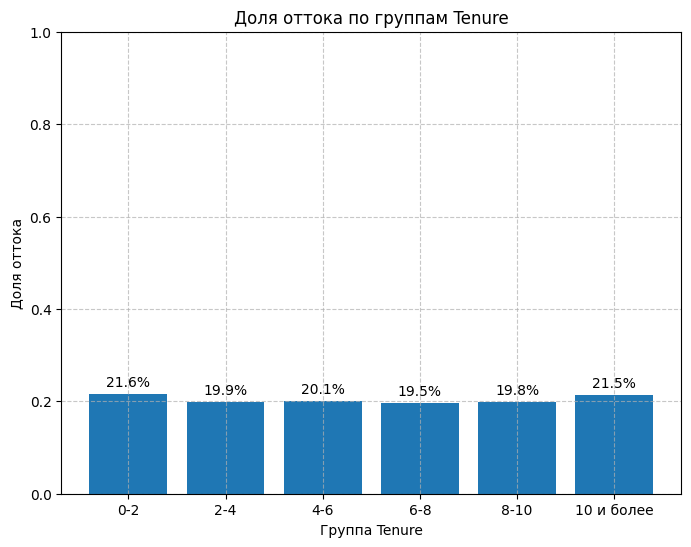

In [100]:
Tenure_groups = ['0-2', '2-4', '4-6', '6-8', '8-10', '10 и более']
churn_rates = [0.217, 0.199, 0.201, 0.195, 0.198, 0.214]

churn_bars(
    churn_by_feature=churn_by_Tenure, labels=Tenure_groups, name='Tenure'
)

Итак, в ходе анализа признака Tenure получили, что:
- Статистики ушедших и оставшихся практически не различаются
- Распределния также почти идентичны, не имеют пиков
- Не удалось выделить какую-либо особую группу клментов по Tenure, в которой была бы большая доля оттока

Исследование показало, что продолжительность отношений клиента с банком почти не влияет на отток сама по себе (но возможно будет влиять в комбинации с другими признаками)

### Balance

Сравним статистики по группам ушедших и оставшихся

Ушедшие:

In [101]:
df[df['Exited'] == 1]['Balance'].describe()

count      4019.000000
mean      87997.794028
std       58067.760190
min           0.000000
25%       37795.870000
50%       99422.100000
75%      129353.280000
max      250898.090000
Name: Balance, dtype: float64

Лояльные

In [102]:
df[df['Exited'] == 0]['Balance'].describe()

count     15903.000000
mean      74918.164332
std       59338.836570
min           0.000000
25%           0.000000
50%       81481.680000
75%      121766.610000
max      250898.090000
Name: Balance, dtype: float64

По статистикам видно, что в среднем баланс у ушедших выше, медиана также у ушедших несколько выше

Рассмотрим гистограммы

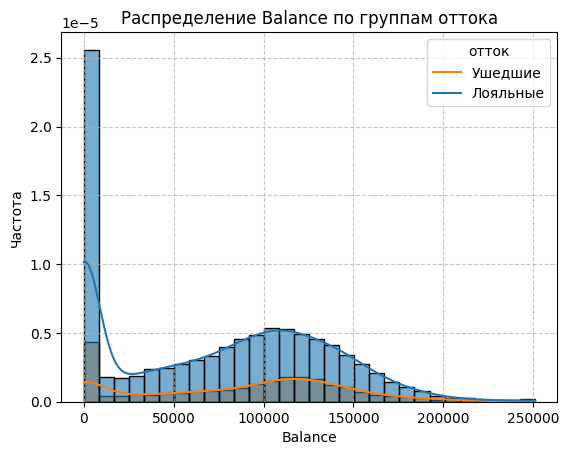

In [103]:
overlay_hists(df, name='Balance')

Можно увидеть, что большая часть клиентов с низким балансом являются лояльными, а пик распределения баланса среди ушедших несколько правее относительно пика распределения баланса лояльных клиентов.

Рассмотрим boxplot-графики

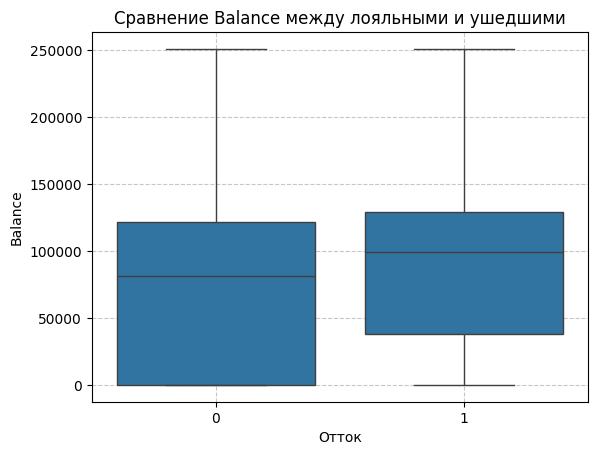

In [104]:
boxplot_comparison(df, name='Balance')

boxplot показывает также показывает, что больше ушедших среди клиентов с меньшим балансом

Рассмотрим теперь доли ушедших по группам

In [105]:
bins = [0, 1, 25_000, 75_000, 125_000, 150_000, 200_000, 300_000]
labels = ['0', 'до 25k', '25k-75k', '75k-125k', '125k-150k','150k-200k', '200k+']

df['balance_group'] = pd.cut(df['Balance'], bins=bins, labels=labels, right=False)

churn_by_balance = df.groupby(
    by='balance_group',observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_balance.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_balance)

               Доля оттока  Количество клиентов
balance_group                                  
0                 0.145660                 4689
до 25k            0.181377                 1031
25k-75k           0.195378                 3245
75k-125k          0.221861                 6157
125k-150k         0.244246                 2694
150k-200k         0.220899                 1847
200k+             0.320463                  259


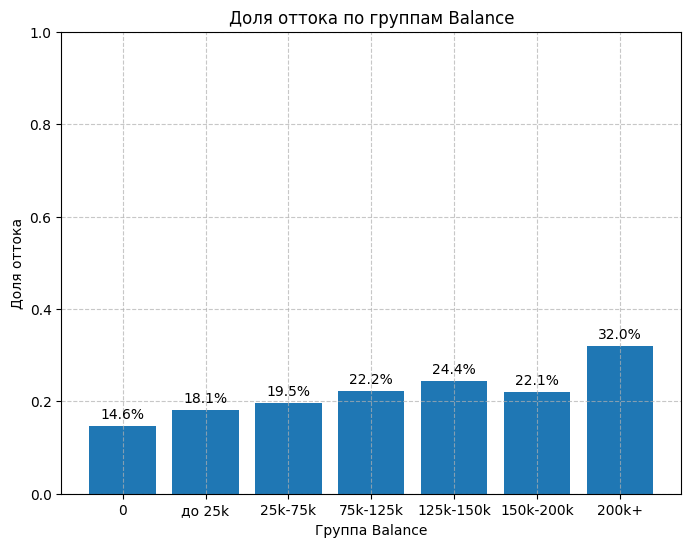

In [106]:
churn_bars(churn_by_feature=churn_by_balance, labels=labels, name='Balance')

df.drop('balance_group', axis=1, inplace=True)

Анализ баланса: 
- Клиенты с нулевым балансом демонстрируют наиболее низкий отток (14.6%), что может быть связано, например, с тем, что клиент получает зарплату на карту банка, либо это новый клиент (требуется дополнительный анализ)
- Начиная с баланса 75 тысяч отток стабильно превышает средний уровень (~22%)
- Самые богатые клиенты (баланс более 200 тысяч) имеют критически высокий отток (32.2%). Это может указывать на системную проблему удержания премимум-сегмента.

##### Balance + NumOfProducts

Сводная таблица:
NumOfProducts     1     2     3     4
balance_group                        
0              0.32  0.06  0.53  0.62
до 25k         0.20  0.17  0.22  0.10
25k-75k        0.21  0.17  0.34  0.30
75k-125k       0.24  0.16  0.55  0.78
125k-150k      0.26  0.16  0.60  0.88
150k-200k      0.23  0.15  0.61  0.86
200k+          0.31  0.36  0.25   NaN


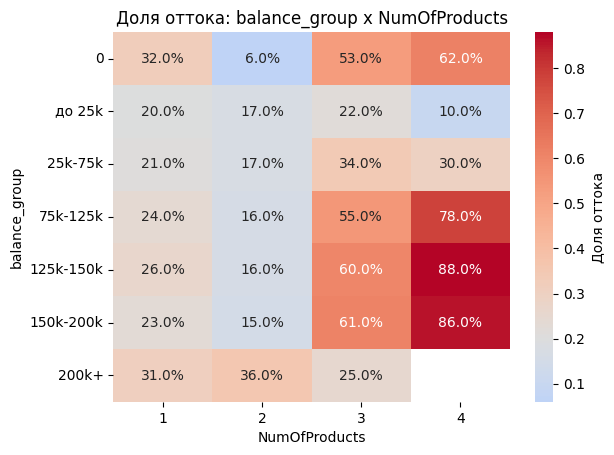

In [107]:
bins = [0, 1, 25_000, 75_000, 125_000, 150_000, 200_000, 300_000]
labels = ['0', 'до 25k', '25k-75k', '75k-125k', '125k-150k','150k-200k', 
                                                                    '200k+']

df['balance_group'] = pd.cut(df['Balance'], bins=bins, labels=labels, 
                                                                 right=False)

pivot_and_heatmap(df, fe_1='balance_group', fe_2='NumOfProducts')

Видно, что наибольший отток демонстрируют клиенты с 3+ продуктами, причем все усугубляется с увеличением баланса (при балансе от 75 тысяч получаем отток от 55%), что интересно имеется высокий отток у клиентов с нулевым балансом и 3+ продуктами, что возможно говорит о навязывании продуктов клиентам, которые в этом не нуждаются, так как не держат деньги в банке, возможно это связано с навязыванием продуктов в самом начале. Стоит посмотреть на вклады групп

In [108]:
impact(df, fe_1='balance_group', fe_2='NumOfProducts')

   balance_group NumOfProducts  count      mean  Вклад
                               Exited    Exited       
0       75k-125k             1   3683  0.237035  873.0
1      125k-150k             1   1731  0.264587  458.0
2              0             1   1215  0.320165  389.0
3       75k-125k             2   2270  0.164317  373.0
4        25k-75k             1   1537  0.210800  324.0
5      150k-200k             1   1219  0.234619  286.0
6        25k-75k             2   1587  0.170132  270.0
7              0             2   3314  0.062161  206.0
8      125k-150k             2    868  0.158986  138.0
9         до 25k             2    579  0.172712  100.0
10      75k-125k             3    172  0.552326   95.0
11     150k-200k             2    572  0.150350   86.0
12        до 25k             1    413  0.196126   81.0
13             0             3    128  0.531250   68.0
14         200k+             1    182  0.307692   56.0
15     125k-150k             3     78  0.602564   47.0
16       2

Видно, что в ТОП 5 групп по вкладу в отток входят в основном клиенты с 1 или двумя продуктами, что может говорить просто о том, что такие группы достаточно большие и уход может быть связан с другими причинами.

##### Balance + Geography

Сводная таблица:
Geography      France  Germany  Spain
balance_group                        
0                0.15     0.18   0.14
до 25k           0.17     0.23   0.18
25k-75k          0.19     0.17   0.24
75k-125k         0.17     0.31   0.18
125k-150k        0.19     0.32   0.20
150k-200k        0.21     0.23   0.22
200k+            0.38     0.29   0.31


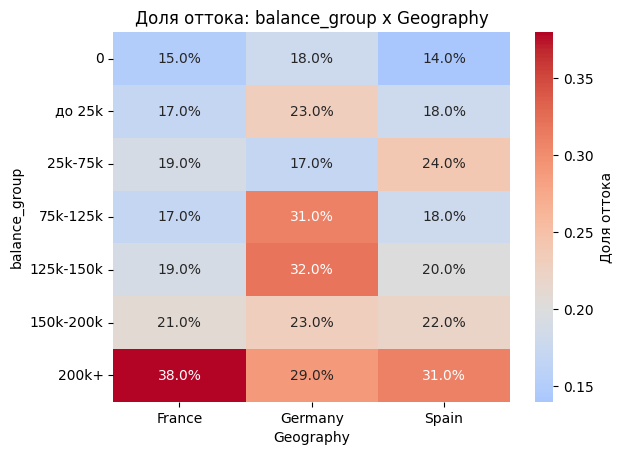

In [109]:
pivot_and_heatmap(df, fe_1='balance_group', fe_2='Geography')

Видно, что есть проблемы у клиентов с самым высоким балансом в каждой стране, что может говорить о проблемах в работе с  премиальными клиентами (особенно во Франции). Также видно, что есть проблемы в работе с клиентами с балансом от 75 до 150 тысяч в Германии. Посмотрим на вклад в отток каждой группы. 

In [110]:
impact(df, fe_1='balance_group', fe_2='Geography')

   balance_group Geography  count      mean  Вклад
                           Exited    Exited       
0       75k-125k   Germany   2102  0.309229  650.0
1              0    France   3202  0.146783  470.0
2       75k-125k    France   2599  0.173144  450.0
3      125k-150k   Germany   1066  0.322702  344.0
4        25k-75k    France   1753  0.187678  329.0
5       75k-125k     Spain   1456  0.182692  266.0
6      125k-150k    France   1089  0.187328  204.0
7              0     Spain   1377  0.140160  193.0
8        25k-75k     Spain    763  0.237221  181.0
9      150k-200k   Germany    681  0.227606  155.0
10     150k-200k    France    705  0.212766  150.0
11       25k-75k   Germany    729  0.170096  124.0
12        до 25k    France    658  0.170213  112.0
13     125k-150k     Spain    539  0.204082  110.0
14     150k-200k     Spain    461  0.223427  103.0
15        до 25k     Spain    228  0.184211   42.0
16         200k+   Germany    137  0.291971   40.0
17        до 25k   Germany    1

Здесь также подтверждается проблема в работе с клиентами с доходом от 75 до 150 тысяч в Германии (суммарно 995 таких клиентов ушли). Клиенты с выскоим балансом дают меньший вклад, однако их уход может быть болезненным, поскольку они могут приносить больше денег.

##### Balance + IsActiveMember

Сводная таблица:
IsActiveMember   0.0   1.0
balance_group             
0               0.18  0.11
до 25k          0.20  0.17
25k-75k         0.22  0.18
75k-125k        0.28  0.17
125k-150k       0.29  0.20
150k-200k       0.27  0.18
200k+           0.28  0.35


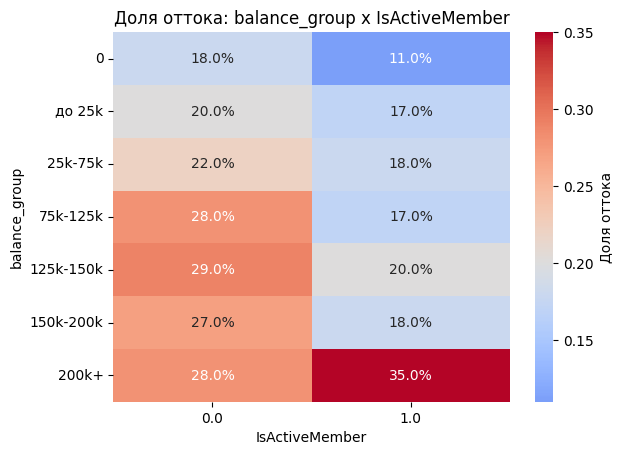

In [111]:
pivot_and_heatmap(df, fe_1='balance_group', fe_2='IsActiveMember')

Видно, что достаточно большой процент оттока среди активных и богатых клиентов, что также говорит о том, что проводится плохая работа с премиум сегментом. Что касается неактивных клиентов, то тут также проблемы начинаются с баланса 75 тысяч. Проверим вклад

In [112]:
impact(df, fe_1='balance_group', fe_2='IsActiveMember')

   balance_group IsActiveMember  count      mean  Вклад
                                Exited    Exited       
0       75k-125k            0.0   2880  0.281597  811.0
1       75k-125k            1.0   3277  0.169362  555.0
2              0            0.0   2219  0.181613  403.0
3      125k-150k            0.0   1278  0.291862  373.0
4        25k-75k            1.0   1805  0.179501  324.0
5        25k-75k            0.0   1440  0.215278  310.0
6      125k-150k            1.0   1416  0.201271  285.0
7              0            1.0   2470  0.113360  280.0
8      150k-200k            0.0    872  0.267202  233.0
9      150k-200k            1.0    975  0.179487  175.0
10        до 25k            0.0    480  0.200000   96.0
11        до 25k            1.0    551  0.165154   91.0
12         200k+            1.0    150  0.353333   53.0
13         200k+            0.0    109  0.275229   30.0


Здесь также проявляется проблема в удержании неактивных клиентов с балансом от 75 тысяч.

##### Balance + Complain

Сводная таблица:
Complain        0.0   1.0
balance_group            
0              0.02  0.85
до 25k         0.14  0.38
25k-75k        0.12  0.51
75k-125k       0.06  0.74
125k-150k      0.06  0.81
150k-200k      0.07  0.73
200k+          0.19  0.64


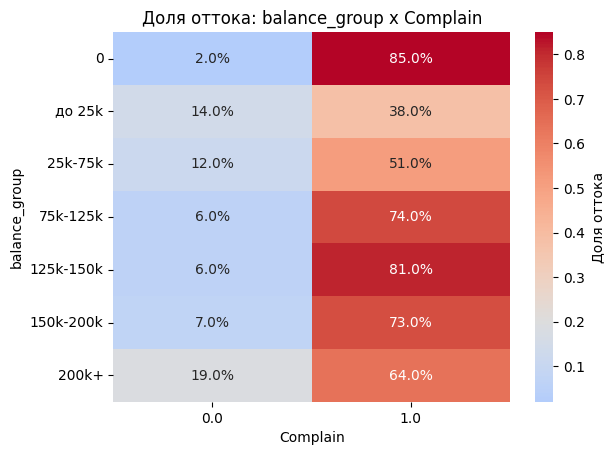

In [113]:
pivot_and_heatmap(df, fe_1='balance_group', fe_2='Complain')

Выделяются несколько зон с высокм риском. Больше всего - клиенты с нулевым балансом и жалобой, с балансом от 75 тысяч и жалобой. Сравним вклады

In [114]:
impact(df, fe_1='balance_group', fe_2='Complain')

   balance_group Complain  count      mean   Вклад
                          Exited    Exited        
0       75k-125k      1.0   1429  0.741777  1060.0
1              0      1.0    686  0.851312   584.0
2      125k-150k      1.0    663  0.808446   536.0
3        25k-75k      1.0    617  0.510535   315.0
4      150k-200k      1.0    407  0.729730   297.0
5        25k-75k      0.0   2412  0.118988   287.0
6       75k-125k      0.0   4495  0.060289   271.0
7      125k-150k      0.0   1966  0.055951   110.0
8         до 25k      0.0    761  0.141919   108.0
9      150k-200k      0.0   1376  0.071948    99.0
10             0      0.0   3918  0.022460    88.0
11        до 25k      1.0    185  0.383784    71.0
12         200k+      1.0     80  0.637500    51.0
13         200k+      0.0    164  0.189024    31.0


Катастрофическая проблема в обработке жалоб клиентов с доходом от 75 тысяч, также интересна ситуация с клиентами с нулвым балансом. Также мы теряем очень много премиум клиентов с жалобой, что тоже критично.

##### Balance + Tenure

Сводная таблица:
tenure_group    0-2   2-4   4-6   6-8  8-10   10+
balance_group                                    
0              0.16  0.16  0.14  0.14  0.12  0.17
до 25k         0.17  0.15  0.20  0.19  0.18  0.20
25k-75k        0.18  0.22  0.19  0.22  0.18  0.17
75k-125k       0.25  0.21  0.23  0.19  0.23  0.23
125k-150k      0.24  0.23  0.25  0.25  0.25  0.25
150k-200k      0.25  0.21  0.18  0.23  0.24  0.26
200k+          0.38  0.35  0.31  0.27  0.27  0.44


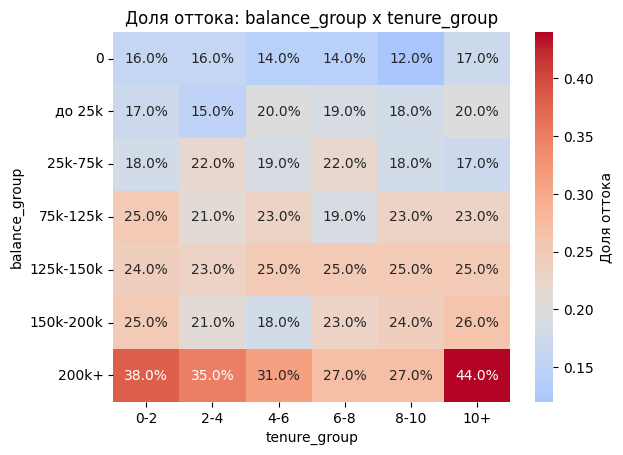

In [115]:
bins = [0, 2, 4, 6, 8, 10, 12]
labels = ['0-2', '2-4', '4-6', '6-8', '8-10', '10+']
df['tenure_group'] = pd.cut(df['Tenure'], bins=bins, labels=labels, 
                                                                right=False)

pivot_and_heatmap(df, fe_1='balance_group', fe_2='tenure_group')

Здесь явно выделяется проблема в работе с клиентами с высоким балансом и почти любым стажем (особенно, 0-2 года, 2-4 года и 10+ лет). Посмотрим на вклад в отток

##### Balance + IsActiveMember + NumOfProducts

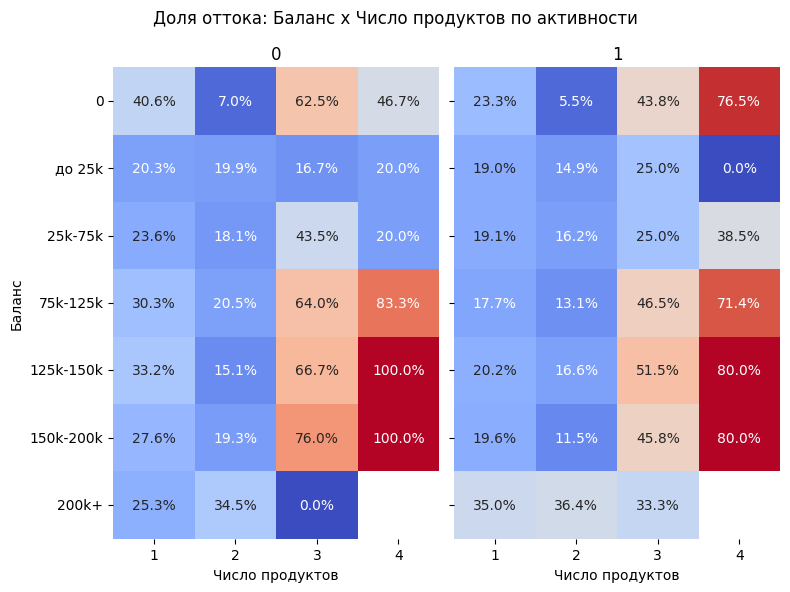

In [116]:
IsActive = [0, 1]

fig, axes = plt.subplots(1, 2, figsize=(8, 6), sharey=True)
for i, active in enumerate(IsActive):
    df_active = df[df['IsActiveMember']==active]
    pivot_active = df_active.pivot_table(
        index='balance_group', columns='NumOfProducts', values='Exited', 
        aggfunc='mean', observed=False
    )

    sns.heatmap(
        pivot_active,
        annot=True,
        fmt='.1%',
        cmap='coolwarm',
        cbar=False,
        ax=axes[i]
    )
    axes[i].set_title(f'{active}')
    axes[i].set_xlabel('Число продуктов')
    if i==0:
        axes[i].set_ylabel('Баланс')
    else:
        axes[i].set_ylabel('')

plt.suptitle('Доля оттока: Баланс x Число продуктов по активности')
plt.tight_layout()
plt.show()

На обоих графиках видно, что в зоне риска те же прямоугольники, что и на графике "Баланс x Число продуктов", однако ситуация обстоит хуже с неактивными клиентами. Они хранят много денег, используют много продуктов, но являются неактивными и в итоге уходят, значит продукты предлагаемые банком либо им неинтересны либо неудобны. То же может касаться и активных клиентов, но там ситуацию несколько лучше особенно для 3 продуктов. Возможно клиенты только начали ими пользоваться. Также интересна ситуация с клиентами с нулевым балансом и 4 продуктами, эти продукты явно неинтересны таким клиентам, возможно были навязаны, раздражают клиентов.

##### Balance + NumOfProducts + Complain

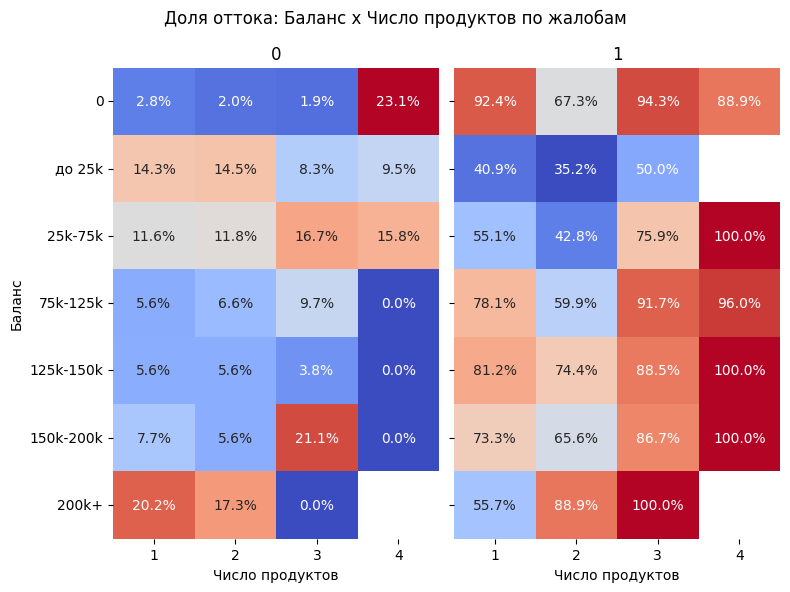

In [117]:
Complains = [0, 1]

fig, axes = plt.subplots(1, 2, figsize=(8, 6), sharey=True)
for i, complain in enumerate(Complains):
    df_complain = df[df['Complain']==complain]
    pivot_complain = df_complain.pivot_table(
        index='balance_group', columns='NumOfProducts', values='Exited', 
        aggfunc='mean', observed=False
    )

    sns.heatmap(
        pivot_complain,
        annot=True,
        fmt='.1%',
        cmap='coolwarm',
        cbar=False,
        ax=axes[i]
    )
    axes[i].set_title(f'{complain}')
    axes[i].set_xlabel('Число продуктов')
    if i==0:
        axes[i].set_ylabel('Баланс')
    else:
        axes[i].set_ylabel('')

plt.suptitle('Доля оттока: Баланс x Число продуктов по жалобам')
plt.tight_layout()
plt.show()

Стоит обратить вниманиен на тот же прямоугольник. Видно, что, если у клиента нет жалобы на продукт, то и отток меньше. Почти во всех случая, когда клиент пользуется 3+ продуктами, то при наличии жалобы он скорее всего точно уйдет. Это отражает тот же прямоугольник только для графика с наличием жалобы

Главные находки:
- баланс 75-200 тысяч + 3-4 продукта (отток от 55% до 88%). Особенно критично баланс 75-200 тысяч + 4 продукта (отток от 78% до 88%), в комбинации с неактивностью отток 64-100%, в комбинации с жалобой отток 100% в нескольких группах.
- баланс 0 или 125-200 тысяч + жалоба (отток 81-100%). Жалоба + высокий баланс - почти гарантированный отток.
- стаж 0-2 года или 10+ лет (отток 41-44%). Проблема на старте и с удержанием с высоким стажем.
- Баланс более 75 тысяч + неактивные (отток 27.5%, 1451 клиент)
- Кризис с премиум клиентами во Франции (отток 38%)

### NumOfProducts

Статистики у ушедших и оставшихся

Ушедшие:

In [118]:
df[df['Exited'] == 1]['NumOfProducts'].describe()

count    4019.000000
mean        1.492660
std         0.707377
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         4.000000
Name: NumOfProducts, dtype: float64

Оставшиеся:

In [119]:
df[df['Exited'] == 0]['NumOfProducts'].describe()

count    15903.000000
mean         1.551657
std          0.550169
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          4.000000
Name: NumOfProducts, dtype: float64

Значительных отличий между ушедшими и оставшимися статистики не показали (только медиана у ушедших ниже)

Рассмотрим распределение числа продуктов у ушедших и оставшихся

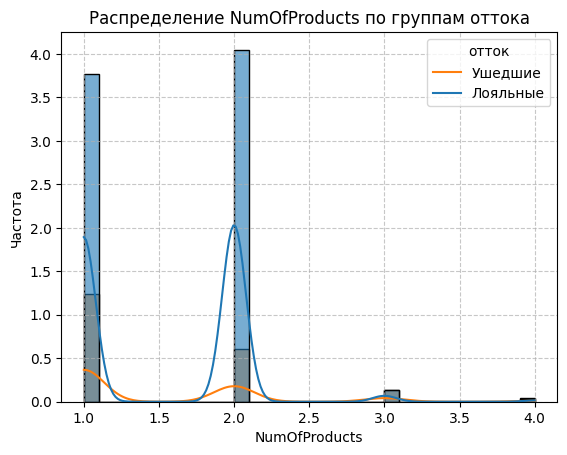

In [120]:
overlay_hists(df, name='NumOfProducts')

Посчитаем доли оттока в каждой группе

In [121]:
churn_by_products = df.groupby(
    by='NumOfProducts',observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_products.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_products)

               Доля оттока  Количество клиентов
NumOfProducts                                  
1                 0.247194                 9980
2                 0.129440                 9263
3                 0.508227                  547
4                 0.568182                  132


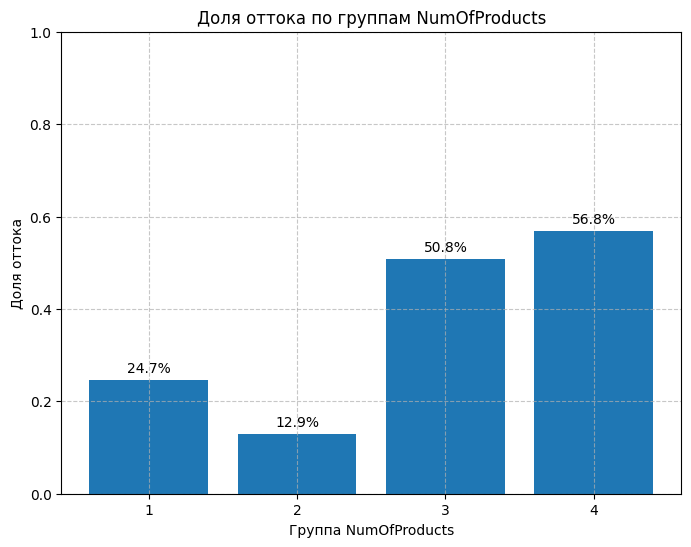

In [122]:
labels = ['1', '2', '3', '4']

churn_bars(
    churn_by_feature=churn_by_products, labels=labels, name='NumOfProducts'
)

Видно, что есть большие проблемы с удержанием клиентов с количеством продуктов от 3 (3 продукта 50.5%, 4 продукта 56.8%). Самые лояльные оказались клиенты с двумя продуктами (13% оттока).

Анализ количества продуктов:
- Клиенты с двумя продуктами демонстрируют наименьший отток (13%) - самые лояльные
- Клиенты с одним прордуктом имеют отток 24.7%, что можно было бы объяснить низкой вовлеченностью
- Клиенты с 3 и 4 продуктами имеют критически высокий отток (50.5% и 56.8% соответственно). Это указывает на системную проблему (продукты могут быть навязанными, перегружать клиента , вызывать технические трудности). К тому же такие клиенты могут приносить больше денег самому банку, ведь пользуются большим числом продуктов.
- Требуется смотреть данный признак в комбинации с другими, чтобы уточнить причины ухода клиентов.
- Помимо выявления причин оттока клиентов с большим числом продуктов, требуется изучить наиболее лояльных клиентов, чтобы понять, почему они настолько лояльны.

##### NumOfProducts + Satisfaction Score

Сводная таблица:
Satisfaction Score   1.0   2.0   3.0   4.0   5.0
NumOfProducts                                   
1                   0.25  0.27  0.23  0.25  0.24
2                   0.13  0.13  0.13  0.13  0.13
3                   0.49  0.60  0.50  0.44  0.51
4                   0.67  0.59  0.54  0.55  0.48


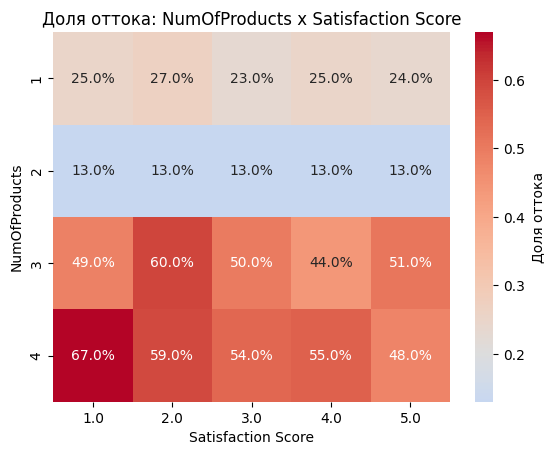

In [123]:
pivot_and_heatmap(df, fe_1='NumOfProducts', fe_2='Satisfaction Score')

Такая комбинация не является особо информативной, поскольку просто показывает, что клиенты с 3 и более продуктами склонны к оттоку (что было известно и до этого), при этом отток почти не зависит от оценки

##### NumOfProducts + Geography

Сводная таблица:
Geography      France  Germany  Spain
NumOfProducts                        
1                0.21     0.33   0.22
2                0.11     0.17   0.13
3                0.43     0.62   0.51
4                0.50     0.84   0.43


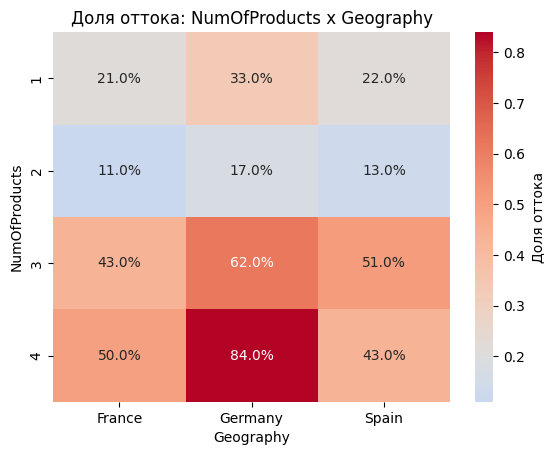

In [124]:
pivot_and_heatmap(df, fe_1='NumOfProducts', fe_2='Geography')

Здесь тоже основной отток идет у клиентов с 3 и более продуктами, однако видна проблема у клиентов в Германии (во-первых, очень высокий отток у клиентов с 4 продуктами, во-вторых, высокий относительно остальных стран отток у клиентов с одним продуктом). Во Франции и Испании отток у клиентов с 3 и более продуктов от 43% до 51%, что также сигнализирует о проблеме в данном сегменте. Рассмотрим вклад в отток различных групп.

In [125]:
impact(df, fe_1='NumOfProducts', fe_2='Geography')

   NumOfProducts Geography  count      mean   Вклад
                           Exited    Exited        
0              1    France   4956  0.213479  1058.0
1              1   Germany   2577  0.334109   861.0
2              1     Spain   2447  0.223948   548.0
3              2    France   4795  0.112200   538.0
4              2   Germany   2199  0.171442   377.0
5              2     Spain   2269  0.125165   284.0
6              3    France    253  0.434783   110.0
7              3   Germany    162  0.623457   101.0
8              3     Spain    132  0.507576    67.0
9              4    France     70  0.500000    35.0
10             4   Germany     32  0.843750    27.0
11             4     Spain     30  0.433333    13.0


Видно, что при любом количестве используемых продуктов по вкладу лидирует Франция, но это может быть связано с тем, что Франция - это основной (или родной) рынок банка

##### NumOfProducts + IsActiveMember

Сводная таблица:
IsActiveMember   0.0   1.0
NumOfProducts             
1               0.30  0.20
2               0.15  0.12
3               0.60  0.41
4               0.56  0.57


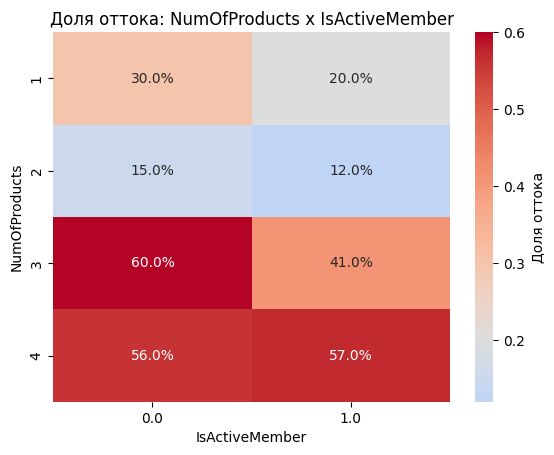

In [126]:
pivot_and_heatmap(df, fe_1='NumOfProducts', fe_2='IsActiveMember')

Так же подтверждает отток у клиентов с 3+ продуктами, также есть важный сигнал оттока неактивных клиентов с 1 продуктом (30%)

##### NumOfProducts + Complain

Сводная таблица:
Complain        0.0   1.0
NumOfProducts            
1              0.07  0.76
2              0.06  0.58
3              0.10  0.89
4              0.13  0.96


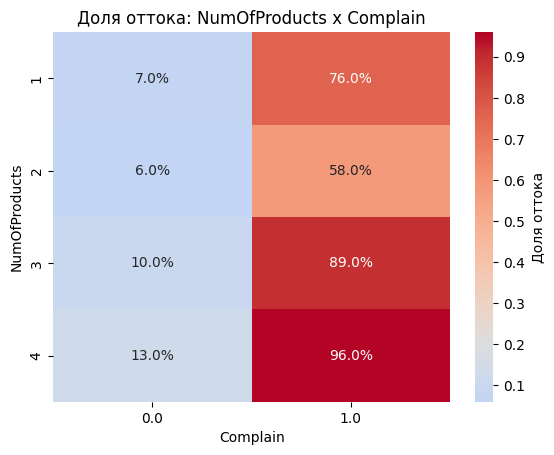

In [127]:
pivot_and_heatmap(df, fe_1='NumOfProducts', fe_2='Complain')

Подтверждает инсайт о том, что жалобы клиентов очень плохо обрабатываются, в комбинации с числом продуктов получаются более сильные результаты (меньше проблем с клиентами, у которых 2 продукта, совсем плохо у клиентов с 3 и 4 продуктами). Можно сравнить вклад в отток разных групп

In [128]:
impact(df, fe_1='NumOfProducts', fe_2='Complain')

  NumOfProducts Complain  count      mean   Вклад
                         Exited    Exited        
0             1      1.0   2521  0.756049  1906.0
1             2      1.0   1195  0.579079   692.0
2             1      0.0   7091  0.070794   502.0
3             2      0.0   7687  0.059711   459.0
4             3      1.0    284  0.887324   252.0
5             4      1.0     67  0.955224    64.0
6             3      0.0    252  0.099206    25.0
7             4      0.0     62  0.129032     8.0


Теряем очень много клиентов с 3 и более продуктами, хотя они могли бы приносить много прибыли

Главные находки:
- Жалоба + 4 продукта (почти 100% отток)
- Проблема с продажей и поддержкой продуктов в Германии (4 продукта 84% оттока, по другим продуктами показатели в Германии также хуже), но и у Франции с Испанией достаточно высокие показатели оттока по 3 и более продуктам.
- Неактивные + 3 продукта (отток 60%). Возможно связано с навязыванием продуктов.
- Активные + 4 продукта (57% отток). Даже активные пользователи не справляются с 4 продуктами.

### EstimatedSalary

Рассмотрим статистики у ушедших и у лояльных

Ушедшие:

In [129]:
df[df['Exited'] == 1]['EstimatedSalary'].describe()

count    4.019000e+03
mean     1.343553e+05
std      3.364710e+05
min      1.158000e+01
25%      5.825599e+04
50%      1.013711e+05
75%      1.470653e+05
max      5.032189e+06
Name: EstimatedSalary, dtype: float64

Лояльные

In [130]:
df[df['Exited'] == 0]['EstimatedSalary'].describe()

count    1.590300e+04
mean     1.380240e+05
std      3.589782e+05
min      2.409000e+01
25%      5.759772e+04
50%      1.013711e+05
75%      1.447953e+05
max      5.123361e+06
Name: EstimatedSalary, dtype: float64

Попробуем построить boxplot

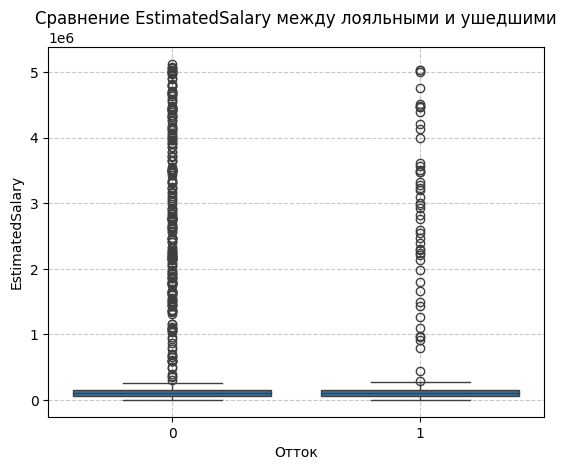

In [131]:
boxplot_comparison(df, name='EstimatedSalary')

Попробуем теперь разбить клиентов на группы по доходу и посмотреть на долю оттока

In [132]:
bins = [0, 10_000, 50_000, 100_000, 150_000, 200_000, 6_000_000]
labels = ['<10k', '10k-50k', '50k-100k', '100k-150k', '150k-200k', 
                                                        '200k+']

df['salary_group'] = pd.cut(df['EstimatedSalary'], bins=bins, labels=labels,
                           right=False)

churn_by_salary = df.groupby(
    by='salary_group',
    observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_salary.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_salary)

              Доля оттока  Количество клиентов
salary_group                                  
<10k             0.187643                  874
10k-50k          0.203170                 3470
50k-100k         0.199574                 4224
100k-150k        0.201116                 6812
150k-200k        0.207786                 4264
200k+            0.183453                  278


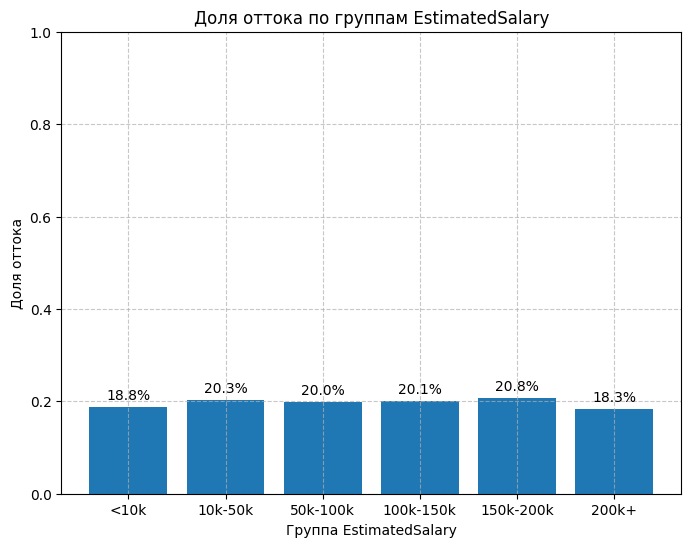

In [133]:
churn_bars(
    churn_by_feature=churn_by_salary, labels=labels, name='EstimatedSalary'
)

df.drop('salary_group', axis=1, inplace=True)

Видно, что отличий по доле оттока в группах особо нет

Исследование показало:
- Прогнозируемый доход не влияет на отток
- Средние значения, распределения и доли оттока по группам дохода находятся на сопоставимом уровне

Вывод: признак EstimatedSalary не является сильным предиктором оттока в данной выборке. Однако стоило бы посмотреть на влияние данного признака в комбинации с другими признаками.

### Satisfaction Score

Рассмотрим статистики ушедших и лояльных

Ушедшие:

In [134]:
df[df['Exited'] == 1]['Satisfaction Score'].describe()

count    4019.000000
mean        3.000249
std         1.388013
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Satisfaction Score, dtype: float64

Лояльные

In [135]:
df[df['Exited'] == 0]['Satisfaction Score'].describe()

count    15903.000000
mean         3.028108
std          1.381928
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: Satisfaction Score, dtype: float64

Статистики не показывают особых различий в группах

Построим распределения 

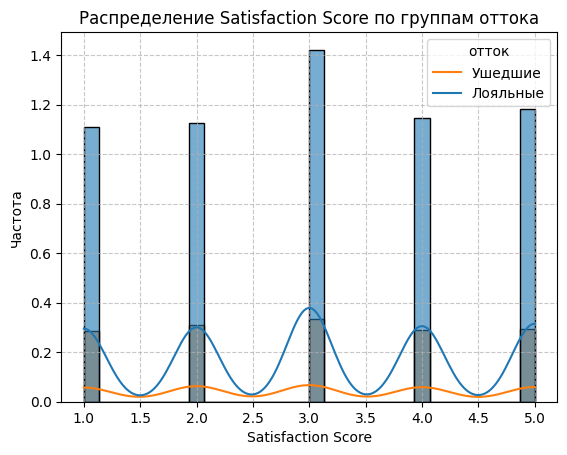

In [136]:
overlay_hists(df, name='Satisfaction Score')

Распределение не показывает особых отличий 

разобьем на группы и посмотрим долю оттока в каждой группе

In [137]:
labels = ['1', '2', '3', '4', '5']

churn_by_satisfaction = df.groupby('Satisfaction Score')['Exited'].agg([
    'mean', 'count'])
churn_by_satisfaction.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_satisfaction)

                    Доля оттока  Количество клиентов
Satisfaction Score                                  
1.0                    0.203949                 3697
2.0                    0.216322                 3823
3.0                    0.189485                 4660
4.0                    0.202671                 3819
5.0                    0.199082                 3923


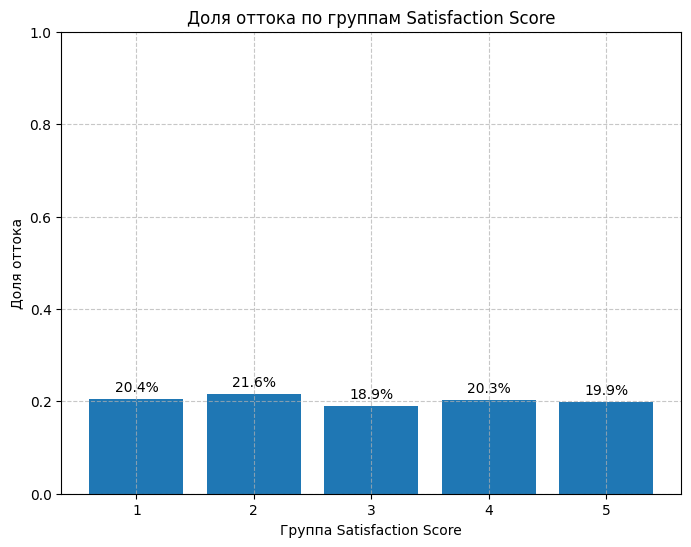

In [138]:
churn_bars(
    churn_by_feature=churn_by_satisfaction, labels=labels, 
    name='Satisfaction Score'
)

Видно, что и разделение на группы по оценке не показало особых различий в группах. Все доли примерно в одном диапазоне

Выводы из анализа:
- описательные статистики почти идентичны между ушедшими и лояльными
- распределения визуально похожи, без выраженных сдвигов
- доли оттока примерно одинаковы по группам

Satisfaction Score не является сильным предиктором оттока сам по себе, но он может оказывать влияение совместно с другим признаком (например, наличие жалобы). Редкий уход у клиентов без оценки может быть связан с тем, что довольные клиенты реже оставляют оценки, либо это новые клиенты.

### Point Earned

Сравним статистики по ушедшим и оставшимся 

Ушедшие:

In [139]:
df[df['Exited']==1]['Point Earned'].describe()

count    4019.000000
mean      607.661607
std       236.375166
min       146.000000
25%       404.500000
50%       617.000000
75%       810.500000
max      1000.000000
Name: Point Earned, dtype: float64

Оставшиеся:

In [140]:
df[df['Exited']==0]['Point Earned'].describe()

count    15903.000000
mean       615.306294
std        236.087781
min        119.000000
25%        414.000000
50%        623.000000
75%        822.000000
max       1000.000000
Name: Point Earned, dtype: float64

Видно, что в среднем у ушедших количество баллов ниже, медиана также ниже у ушедших. Но на первый взгляд это незначительные отличия

Рассмотрим теперь распределния

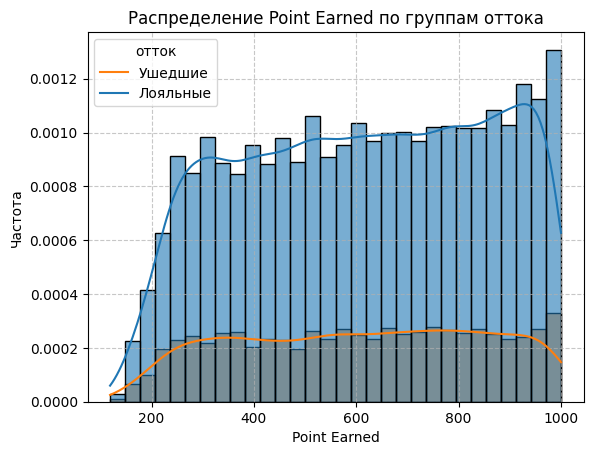

In [141]:
overlay_hists(df, name='Point Earned')

Видно, что в целом распределения похожи на равномерное, особых пиков нет, отличия тоже не особо заметны

Рассмотрим boxplot

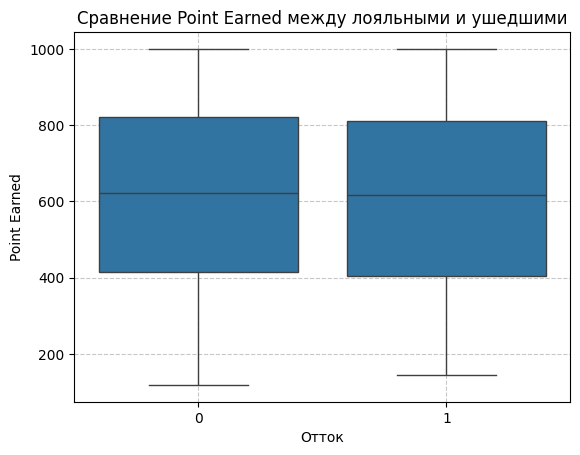

In [142]:
boxplot_comparison(df, name='Point Earned')

Также значмых отличий не наблюдается

Попробуем разбиение на группы

In [143]:
bins = [0, 200, 400, 600, 800, 1_001]
labels = ['<200', '200-400', '400-600', '600-800', '800-1000']

df['point_groups'] = pd.cut(df['Point Earned'], bins=bins, labels=labels, 
                                                                right=False)

churn_by_points = df.groupby(
    by='point_groups',
    observed=False
)['Exited'].agg(['mean', 'count'])
churn_by_points.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_points)

              Доля оттока  Количество клиентов
point_groups                                  
<200             0.221951                  410
200-400          0.208776                 4239
400-600          0.200209                 4780
600-800          0.205548                 5011
800-1000         0.192630                 5482


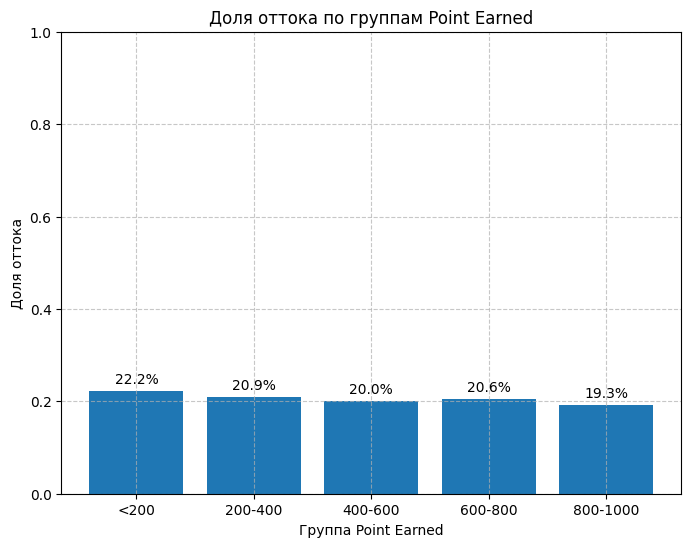

In [144]:
churn_bars(
    churn_by_feature=churn_by_points, labels=labels, name='Point Earned'
)

df.drop('point_groups', axis=1, inplace=True)

Разбиение на группы таке не показало влияния числа баллов на отток

Итоги анализа:
- Описательные статистики почти идентичны
- Распределения похожи на равномерные, без выраженных пиков
- Boxplot почти идентичны

Вывод: баллы не значимы для лояльности

## Категориальные признаки

### Geography

Рассмотрим распределение клиентов по странам в процентах

In [145]:
country_dist = df['Geography'].value_counts(normalize=True).round(3) * 100
print("Распределение клиентов по странам:")
print(country_dist)

Распределение клиентов по странам:
Geography
France     50.6
Germany    24.9
Spain      24.5
Name: proportion, dtype: float64


Основной рынок - Франция, Германия и Испания имеют примерно одинаковый объем

Рассмотрим долю оттока по странам 

In [146]:
churn_by_country = df.groupby('Geography')['Exited'].agg(['mean', 
                                                          'count']).round(3)
churn_by_country.columns = ['Доля оттока', 'Количество']
print(churn_by_country)

           Доля оттока  Количество
Geography                         
France           0.173       10074
Germany          0.275        4970
Spain            0.187        4878


Наибольшая доля оттока в Германии

Теперь построим визуализацию

Распределение

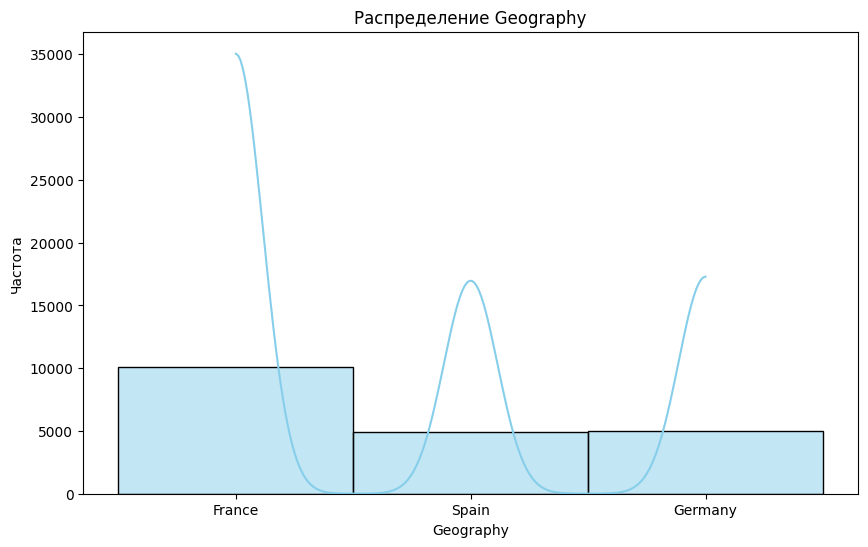

In [147]:
distribution(df, name='Geography')

Доля оттока по странам

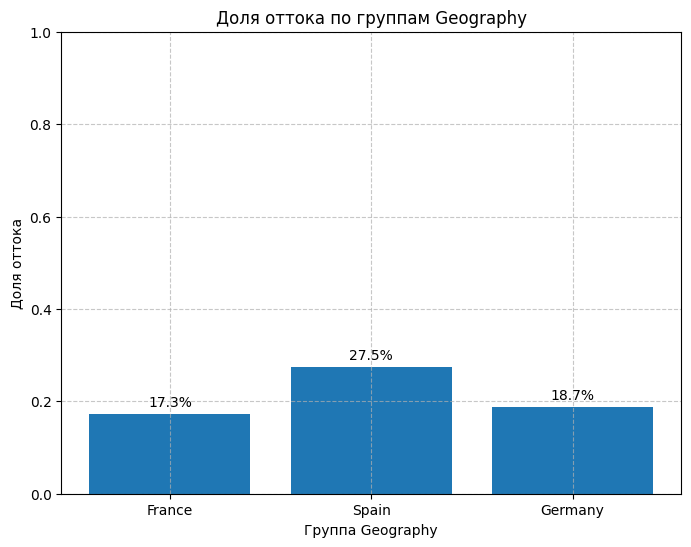

In [148]:
churn_bars(
    churn_by_feature=churn_by_country, labels=df['Geography'].unique(), 
    name='Geography'
)

Итоги анализа:
- Основной рынок - Франция (доля клиентов ~50%), при этом Франция является и самым лояльным рынком (доля оттока 17.3%)
- Зона риска - Германия (доля клиентов ~25%), но больше всего доля оттока (27.5%)
- Испания - по объему такая же, как Германия (~25%), но доля оттока близка к Франции (18.7%), что тоже ниже среднего. Является стабильным рынком

Для выявления причин оттока в Германии требуется комбинация с другими признаками.

##### Geography + IsActiveMember

Сводная таблица:
IsActiveMember   0.0   1.0
Geography                 
France          0.21  0.15
Germany         0.33  0.22
Spain           0.23  0.15


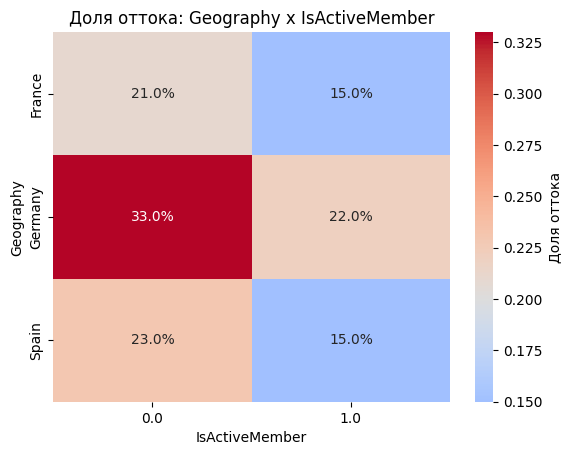

In [149]:
pivot_and_heatmap(df, fe_1='Geography', fe_2='IsActiveMember')

Видно, что главная группа риска - неактивные немцы, что говорит о плохой стратегии раоты с неактивными клиентами из Германии.

##### Geography + Complain

Сводная таблица:
Complain    0.0   1.0
Geography            
France     0.06  0.69
Germany    0.07  0.76
Spain      0.06  0.70


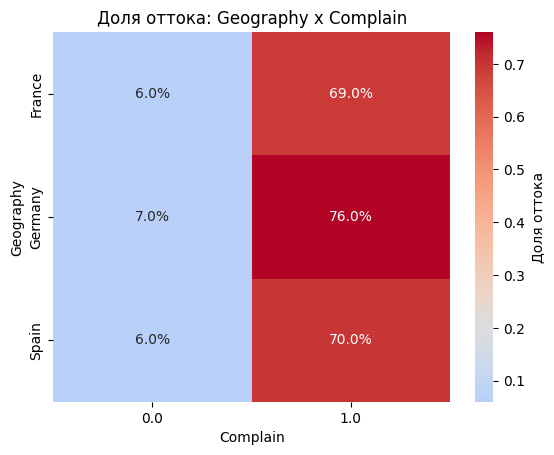

In [150]:
pivot_and_heatmap(df, fe_1='Geography', fe_2='Complain')

Находки:
- В Германи неактивность наиболее опасна - клиенты быстрее "охладевают" к банку и уходят
- Жалоба - проблема во всех странах, но в Германии критичней всего, хотя разница в долях оттока не критична.

### Gender

Посмотрим распределение по полу 

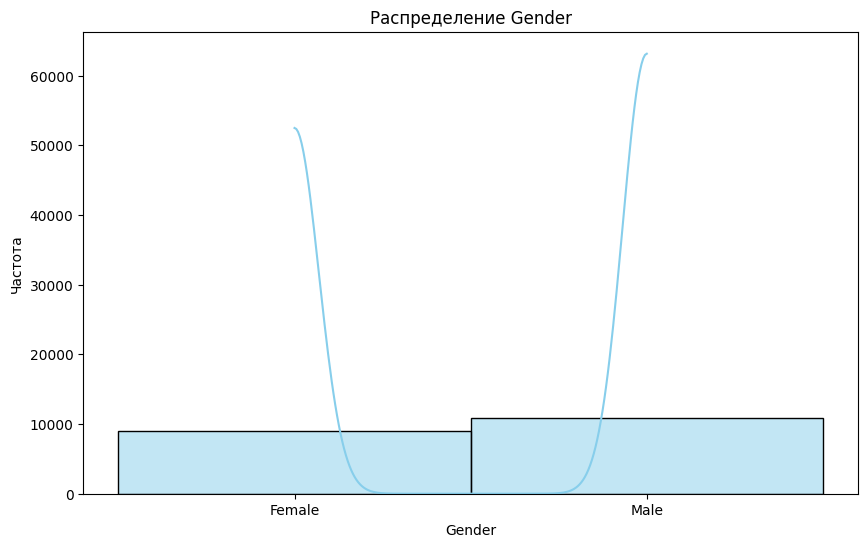

In [151]:
distribution(df, name='Gender')

Доля оттока по полу

In [152]:
churn_by_gender = df.groupby('Gender')['Exited'].agg(['mean', 'count'])
churn_by_gender.columns = ['Доля оттока', 'Количество человек']

print(churn_by_gender)

        Доля оттока  Количество человек
Gender                                 
Female     0.231229                9043
Male       0.177222               10879


Визуализация

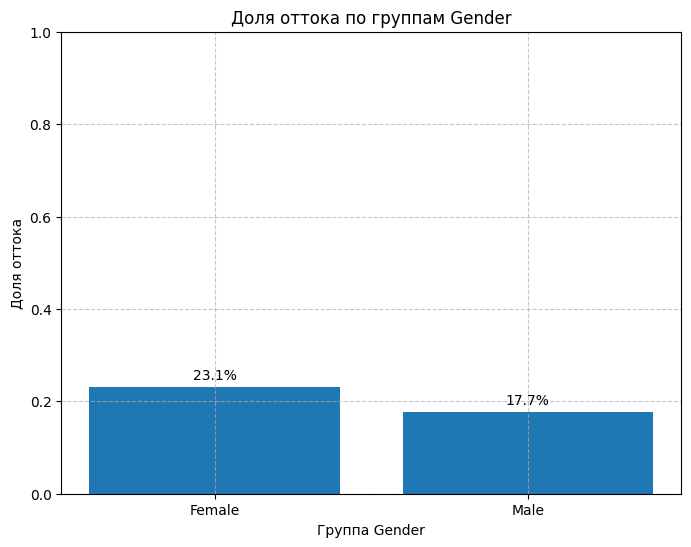

In [153]:
churn_bars(
    churn_by_feature=churn_by_gender, labels=df['Gender'].unique(),
    name='Gender'
)

Итоги анализа:
- Мужчины - доля клиентов 54.3%, являются самыми лояльными клиентами (отток всего 17.7%)
- Женщины - доля клиентов 45.2%, являются зоной с наибольшим оттоком (23.1%)

### HasCrCard

Сравним распределения

In [154]:
card_dist = df['HasCrCard'].value_counts()
card_dist_pct = df['HasCrCard'].value_counts(normalize=True) * 100

print('Распределение клиентов по наличию кредитной карты' 
                                                    '(абсолютные значения)')
print(card_dist)
print('\nРаспределение клиентов по наличию кредитной карты (в %)')
print(card_dist_pct)

Распределение клиентов по наличию кредитной карты(абсолютные значения)
HasCrCard
1    14086
0     5836
Name: count, dtype: int64

Распределение клиентов по наличию кредитной карты (в %)
HasCrCard
1    70.705752
0    29.294248
Name: proportion, dtype: float64


Рассмотрим долю оттока

In [155]:
churn_by_card = df.groupby('HasCrCard')['Exited'].agg(['mean', 'count'])
churn_by_card.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_card)

           Доля оттока  Количество клиентов
HasCrCard                                  
0             0.203907                 5836
1             0.200838                14086


Визуализация

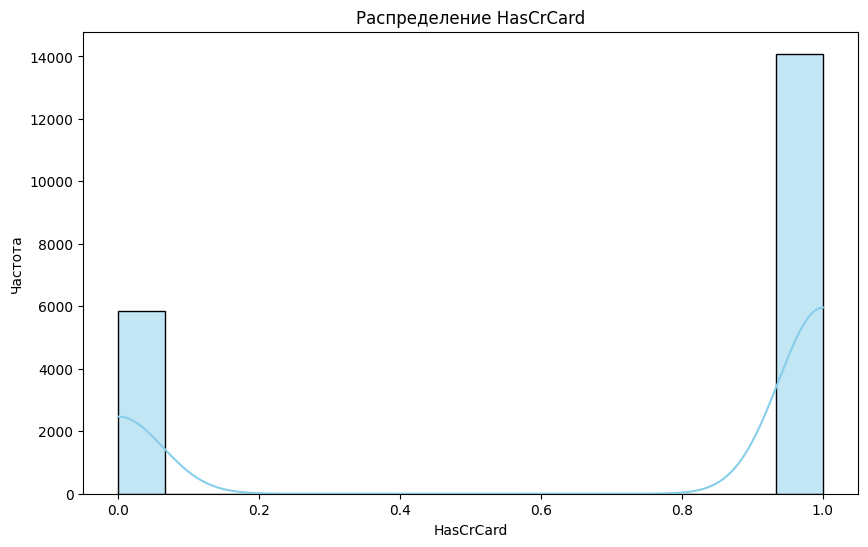

In [156]:
distribution(df, name='HasCrCard')

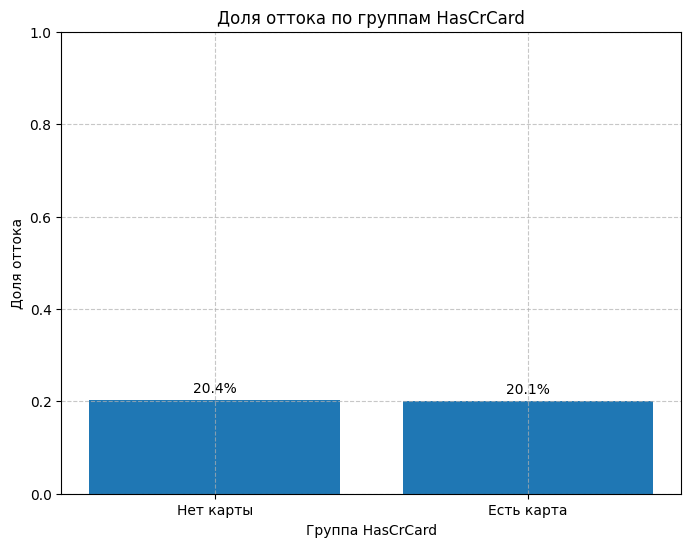

In [157]:
churn_bars(
    churn_by_feature=churn_by_card, labels=['Нет карты', 'Есть карта'],
    name='HasCrCard'
)

Итоги анализа:
- Большинство пользователей (71%) имеют кредитную карту при доле оттока 20.4%
- Пользователи без карты (29%) имеют долю оттока 20.1%
- Получается, что наличие кредитной карты само по себе не является значимым предиктором оттока, но возможно оно усилит некоторые другие признаки

### IsActiveMember

Сравним распределения ушедших и оставшихся

In [158]:
active_dist = df['IsActiveMember'].value_counts()
active_dist_pct = df['IsActiveMember'].value_counts(normalize=True) * 100

print('Распределение пользователей по активности (абсолютная величина):')
print(active_dist)
print('\nРаспределние пользователей по активности (в %):')
print(active_dist_pct)

Распределение пользователей по активности (абсолютная величина):
IsActiveMember
1.0    10644
0.0     9278
Name: count, dtype: int64

Распределние пользователей по активности (в %):
IsActiveMember
1.0    53.428371
0.0    46.571629
Name: proportion, dtype: float64


Видно, что пользователей примерно поровну

Теперь посмотрим долю оттока

In [159]:
churn_by_active = df.groupby('IsActiveMember')['Exited'].agg(['mean', 
                                                              'count'])

churn_by_active.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_active)

                Доля оттока  Количество клиентов
IsActiveMember                                  
0.0                0.243156                 9278
1.0                0.165633                10644


Проверим влияние на отток клиенетов с пропущенной информацией об активности

In [160]:
passes_churn = df[df['Missed_IsActiveMember'] == 1]['Exited'].mean() * 100

print('Процент  оттока среди клиентов с пропущенной информацией об ' 
                                        'активности', passes_churn.round(2))

Процент  оттока среди клиентов с пропущенной информацией об активности 14.55


Итак, процент оттока среди пользователей с пропусками по активности составляет 14%, что кажется не критичным

Визуализация

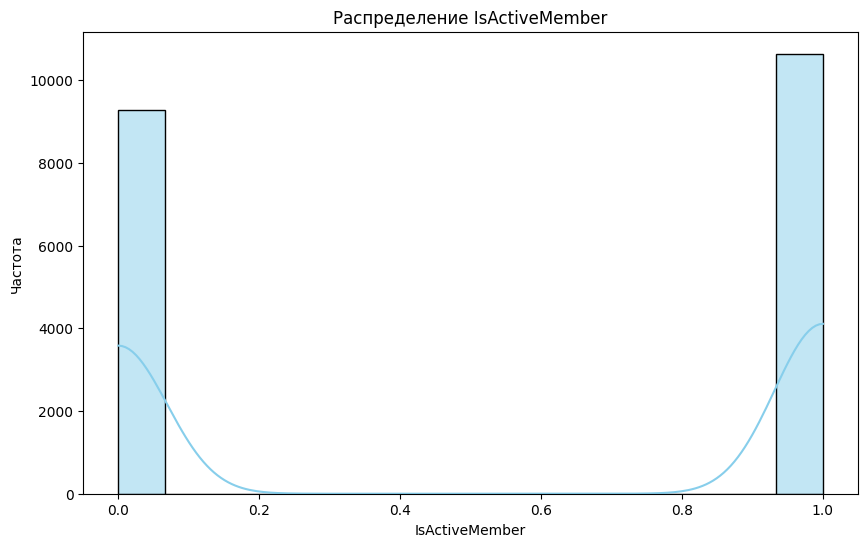

In [161]:
distribution(df, name='IsActiveMember')

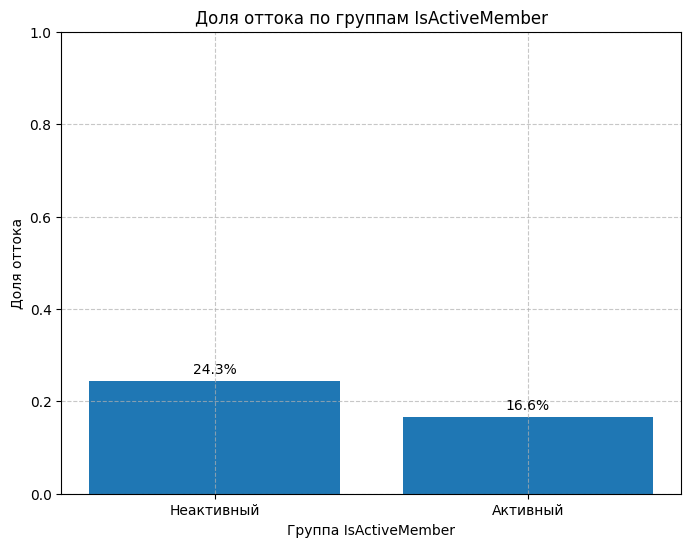

In [162]:
churn_bars(
    churn_by_feature=churn_by_active, labels=['Неактивный', 'Активный'],
    name='IsActiveMember'
)

Итоги анализа:
- По активности клиенты делятся примерно в одинаковом соотношении (53% активных и 47% неактивных)
- Наиболее склонными к оттоку являются неактивные клиенты (доля оттока 24.3%), что является вполне разумным
- Активные же клиенты менее склонны к оттоку (доля оттока 16.6%)
- Клиенты с пропусками по активности не особо сильно влияют на отток

### Complain

Сравним распределение лояльных и ушедших по жалобам

In [163]:
complain_dist = df['Complain_1'].value_counts()
complain_dist_pct = df['Complain_1'].value_counts(normalize=True) * 100

print('Распределние клиентов по наличию жалоб (абсолютная величина):')
print(complain_dist)
print('\nРаспределение клиентов по наличию жалоб (в %):')
print(complain_dist_pct)

Распределние клиентов по наличию жалоб (абсолютная величина):
Complain_1
0    15855
1     4067
Name: count, dtype: int64

Распределение клиентов по наличию жалоб (в %):
Complain_1
0    79.585383
1    20.414617
Name: proportion, dtype: float64


Рассмотрим долю оттока в зависимости от наличия жалобы

In [164]:
churn_by_complain = df.groupby('Complain_1')['Exited'].agg(['mean', 'count'])
churn_by_complain.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_complain)

            Доля оттока  Количество клиентов
Complain_1                                  
0              0.069694                15855
1              0.716499                 4067


Проверим влияние пропусков

In [165]:
passes_churn = df[df['missed_complain']==1]['Exited'].mean() * 100

print('Доля оттока у клиентов с пропущенной информацией о наличии жалобы',
                                                        passes_churn.round(2))

Доля оттока у клиентов с пропущенной информацией о наличии жалобы 14.55


Визуализация

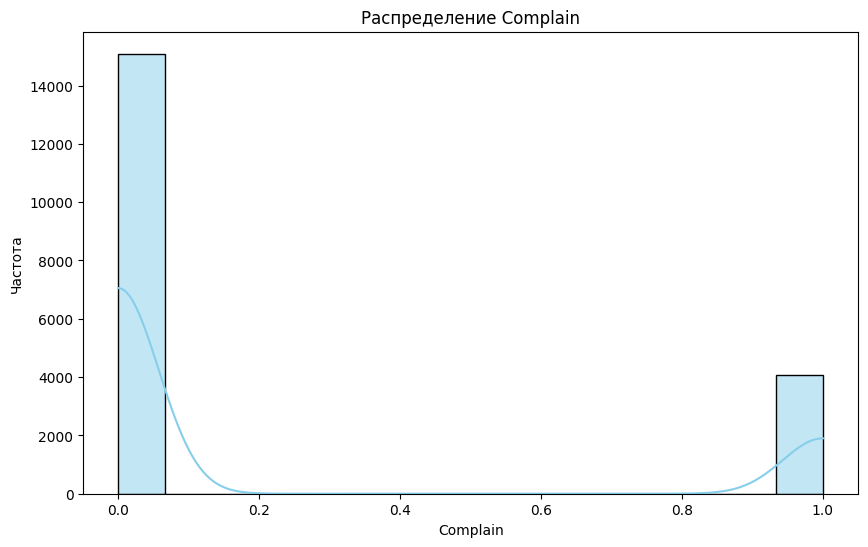

In [166]:
distribution(df, name='Complain')

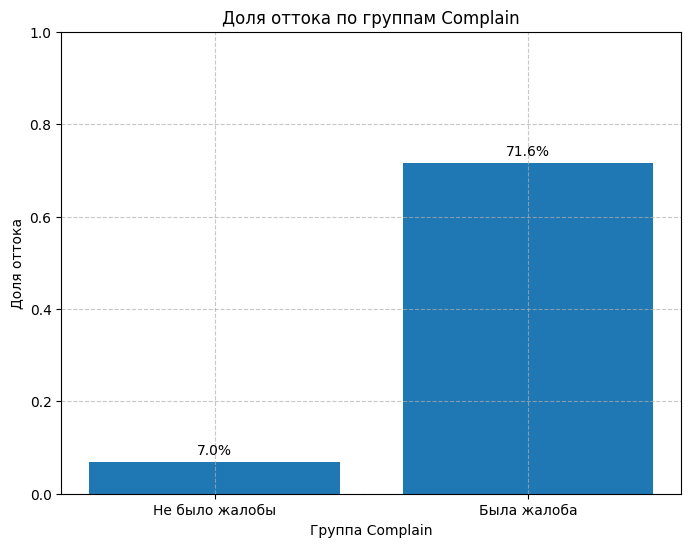

In [167]:
churn_bars(
    churn_by_feature=churn_by_complain, 
    labels=['Не было жалобы', 'Была жалоба'],
    name='Complain'
)

Итоги анализа: 
- У большинства пользователей нет жалоб, что похоже на реальный результат
- Пользователи с жалобами имеют отток 71.5%, что является критичным результатом, то есть проводится плохая работа с жалобами клиентов.
- Пользователи с пропущенной информацией о жалобах имеют малую долю оттока, что может говорить о том, что пропуски особого влияния не оказывают

### CardType

Проверим уникальные значения

In [168]:
df['Card Type'].unique()

array(['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD'], dtype=object)

Пропущенных значений нет

Теперь проверим распределние клиентов по типу карты

In [169]:
CardType_dist = df['Card Type'].value_counts()
CardType_dist_pct = df['Card Type'].value_counts(normalize=True) * 100

print('Распредление клиентов по типу карты (абсолютное значение):')
print(CardType_dist)
print('\nРаспределение клиентов по типу карты (в %):')
print(CardType_dist_pct)

Распредление клиентов по типу карты (абсолютное значение):
Card Type
DIAMOND     5055
PLATINUM    4999
GOLD        4969
SILVER      4899
Name: count, dtype: int64

Распределение клиентов по типу карты (в %):
Card Type
DIAMOND     25.373958
PLATINUM    25.092862
GOLD        24.942275
SILVER      24.590905
Name: proportion, dtype: float64


Рассмотрим теперь долю оттока по типу карты

In [170]:
churn_by_card = df.groupby('Card Type')['Exited'].agg(['mean', 'count'])
churn_by_card.columns = ['Доля оттока', 'Количество клиентов']

print(churn_by_card)

           Доля оттока  Количество клиентов
Card Type                                  
DIAMOND       0.208309                 5055
GOLD          0.194204                 4969
PLATINUM      0.201240                 4999
SILVER        0.203103                 4899


Визуализация

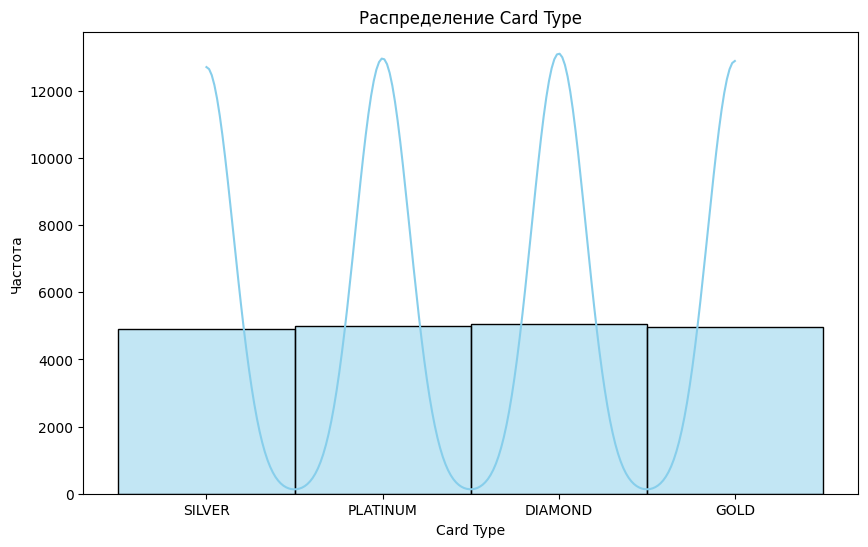

In [171]:
distribution(df, name='Card Type')

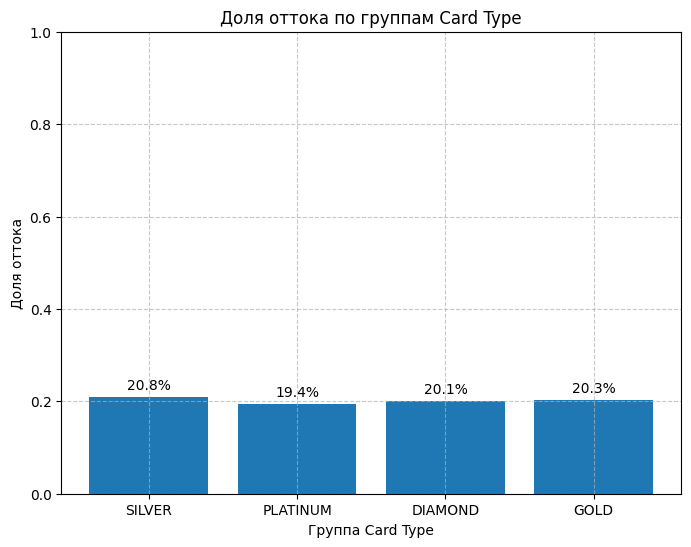

In [172]:
churn_bars(
    churn_by_feature=churn_by_card, labels=df['Card Type'].unique(),
    name='Card Type'
)

Итоги анализа:
- По типу карты клиенты разбиты примерно на равные доли
- Отток не различается по типу карты. У групп доли оттока примерно совпадают
- Анализ позволяет сказать, что сам по себе тип карты особо не влияет на отток, но возможно стоить скомбинировать данный признак с другими (например, баланс владельца карты)

##### CardType + Balance

Сводная таблица:
balance_group     0  до 25k  25k-75k  75k-125k  125k-150k  150k-200k  200k+
Card Type                                                                  
DIAMOND        0.16    0.15     0.19      0.24       0.25       0.20   0.36
GOLD           0.15    0.19     0.18      0.21       0.23       0.22   0.25
PLATINUM       0.14    0.18     0.19      0.22       0.26       0.22   0.28
SILVER         0.14    0.20     0.21      0.21       0.24       0.25   0.36


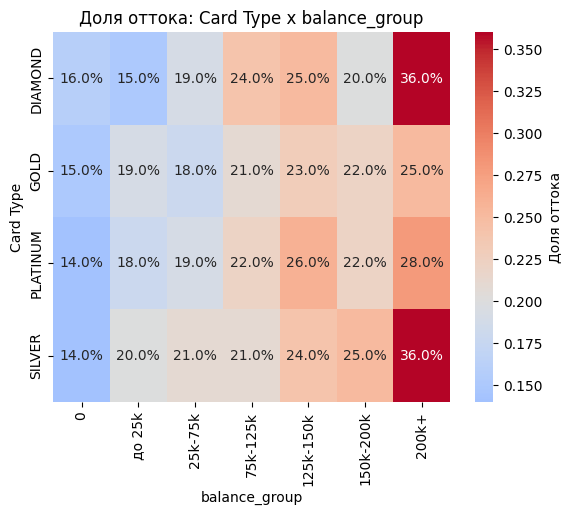

In [173]:
pivot_and_heatmap(df, fe_1='Card Type', fe_2='balance_group')

In [174]:
impact(df, fe_1='Card Type', fe_2='balance_group')

   Card Type balance_group  count      mean  Вклад
                           Exited    Exited       
0    DIAMOND      75k-125k   1640  0.237805  390.0
1   PLATINUM      75k-125k   1528  0.221204  338.0
2       GOLD      75k-125k   1548  0.213824  331.0
3     SILVER      75k-125k   1441  0.213046  307.0
4    DIAMOND             0   1127  0.155280  175.0
5    DIAMOND     125k-150k    686  0.250729  172.0
6       GOLD             0   1170  0.145299  170.0
7     SILVER             0   1216  0.139803  170.0
8   PLATINUM       25k-75k    873  0.194731  170.0
9     SILVER       25k-75k    800  0.212500  170.0
10  PLATINUM     125k-150k    653  0.258806  169.0
11  PLATINUM             0   1176  0.142857  168.0
12    SILVER     125k-150k    692  0.239884  166.0
13      GOLD     125k-150k    663  0.227753  151.0
14   DIAMOND       25k-75k    774  0.192506  149.0
15      GOLD       25k-75k    798  0.181704  145.0
16      GOLD     150k-200k    496  0.219758  109.0
17    SILVER     150k-200k    4

Видим, что самый большой вклад в отток клиентов с "премиальными картами" и достаточно высоким балансом, при этом в такие группы входит достаточно много клиентов. Также интересна ситуация у клиентов с нулевым балансом и картой "DIAMOND", то есть они получили такие карты, но могут ими не пользоваться , возможно, они были им навязаны и совсем не нужны

Получилась интересная ситуация: клиенты с балансом 200+ тысяч и картами SILVER и DIAMOND имеют наибольший отток (35-37%). Возможные причины:
- Недообслуживание (клиент с высоким балансом не получил предложение на повышение типа карты или его не устраивают услови пермиальных карт)
- Разочарование (условия премиальных карт не соответсвуют обещаниям, не устраивает поддержка)

## Портреты

### Портрет лояльного клиента

Демография:
- Возраст: менее 45 лет (пик лояльности в 36 лет)
- Мужчины немного лояльнее (отток 17.7% против 23.3% у женщин), но не критично
- Страна: Франция самый лояльный рынок, но и Испания тоже не сильно хуже

Финансы:
- Баланс 0-75 тысяч - "золотая середина" (не слишком мало и не слишком много)
- Прогнозируемый доход: не имеет значения
- Кредитный рейтинг: чуть выше, но не ключевой фактор

Поведение и продукты:
- 2 продукта - идеальный баланс (отток 13%)
- Активный пользователь (отток 16.6%)
- Наличие кредитной карты сильно на отток не влияет
- Тип карты почти не оказывает влияния
- Баллы по кредитной карте: не влияют - лояльность не зависит от бонусов.

Удовлетворенность и жалобы:
- Жалобы: нет (отток 20% против 71.5% у тех, кто жаловался)
- Оценка удовлетворенности: не имеет значения - если нет жалоб, то клиент остается

Почему остается: 
- Не перегружен - 2 продукта, которыми легко управлять
- Активен - регулярно пользуется сервисом
- Не сталкивается с проблемами - жалоб нет
- Банк хорошо работает с сегментом клиентов со средним балансом, а также хорошо работает с молодежью.

Рекомендации:
- Не трогать, но изучать, почему остаются лояльным
- Предлагать продукты только осознанно (если клиент готов), не навязывать

### Портрет клиента, склонного к оттоку

Демография:
- Возраст: 45-65 лет - пик оттока (теряем 40% клиентов)
- Пол: женщины, особенно в 45-65 лет, но не слишком критичное отличие от мужчин
- Страна: Германия - самый высокий отток (каждый третий уходит), особенно в 45-65 лет (почти каждый второй)

Финансы: 
- Баланс: 75-200+ тысяч - чем выше, тем выше риск (при 200+ тысяч теряем каждого третьего)
- Прогнозируемый доход: не имеет значения
- Кредитный рейтинг: не ключевой фактор

Поведение и продукты:
- Количество продуктов: 3-4 продукта - один из главных триггеров оттока (теряем каждого второго при 3 продуктах и теряем 2 из 3 при 4 продуктах; если имеется жалоба и 3+ продукта, то теряем почти каждого клиента)
- Активность: неактивный (теряем чуть больше чем 1 из 5 неактивных клиентов, причем в Германии каждого третьего, а в возрасте от 45 лет теряем около половины неактивных клиентов)
- Кредитная карта: не влияет
- Тип карты SILVER или DIAMOND при балансе 200+ тысяч - теряем почти двух из пяти клиентов (недооцененные или разочарованные)

Удовлетворенность и жалобы:
- Жалобы: есть - главный триггер оттока (71.5%, до 96% при 4 продуктах, до 95% в 45-65 лет)
- Оценка удовлетворенности: не спасает - даже при высокой оценке, но наличии жалобы или при наличии 3 и более продуктов теряем много клиентов.
- Обработка жалоб: катастрофически неэффективна.

Почему уходит:
- Перегрузка продуктами - не справляется, стресс, плохая поддержка
- Игнорирование - неактивных клиентов не стараются вернуть
- Плохой сервис - жалобы решаются некачественно
- Локальные проблемы - особенно в Германии (возможные причины: конкуренция, культура, локализация)
- Плохая работа со зрелыми клиентами (возможно, неудобный или непонятный интерфейс)
- Возможно плохие условия для премиум-клиентов

Рекомендации по удержанию:
- Улучшение поддержки клиентов с жалобой (возможно звонок менеджера, компенсация за неудобства), особенно для клиентов 45-65 лет с 3+ продуктами
- Улучшение сервиса в Германии
- Не предлагать клиенту много продуктов сразу
- Повышение типа карты клиента с высоким балансом
- Улучшение условия карты типа DIAMOND

In [175]:
df_copy = df.copy()

In [176]:
df_copy.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned',
       'Missed_CreditScore', 'Missed_IsActiveMember', 'Missed_EstimatedSalary',
       'Complain_1', 'missed_complain', 'missed_SatisfactionSCore',
       'AbnormalAge', 'NegativeSalary', 'age_group', 'balance_group',
       'tenure_group'],
      dtype='object')

In [177]:
df_copy.drop(['age_group', 'balance_group', 'tenure_group'], axis=1, 
             inplace=True)

In [178]:
df_copy.to_csv('clients.csv')

# Моделирование

Основной метрикой для сравнения моделей выберем PR AUC (лучше учитывает дисбаланс классов). Построим пайплайны моделей логистической регрессии и случайного леса. Разберем два подходла: удаление пропусков и выбросов либо их обработка. Разделим выборку на обучающую и тестовую в соотношении 75/25 со стратификацией для учета дисбаланса. Оценим модель на тестовой выборке, а также проверим ее калиьровку. При подборе гиперпараметров используем кросс-валидацию, а также используем ее для оценки переобучения в процессе подбора гиперпараметров

**Обобснование выбора метрики**

PR-AUC оценивает способность модели правильно классифицировать положительные примеры, избегая ложноположительных ошибок.

Если, например, N - общее число истинно отрицательных представителей, а P - общее число истинно положительных представителей, то в нашем случае N = 0.8*M, P = 0.2*M, где M - объем выборки.

Проблема ROC-AUC при дисбалансе: FPR = FP/(FP + TN) = FP/N "разбавляется" большим N. При N = 8000, даже FP = 1600 дает FPR = 0.2 - всего лишь 20%, но в абсолютных цифрах - это 1600 ложных     срабатываний, что может быть дорого (удержать 1600 клиентов, которые не собирались уходить)

Пример с цифрами:

Пусть есть выборка из 10 000 клиентов (P = 2 000, N = 8 000). Предположим, что модель выдала следующие результаты:
TP = 1 000 (поймала половину ушедших)
FP = 2 000 (ошибочно пометила 2 000 лояльных как ушедших)

Тогда:
- Recall(TPR) = 1000 / 2000 = 0.5
- FPR = 2000 / 8000 = 0.25
- Precision = 1000 / (1000 + 2000) = 0.33

Таким образом, на каждые 3 клиента 2 ложных срабатывания. При дисбалансе большая часть площади под ROC-кривой определяется поведением на фоне N. Модель может иметь высокий ROC-AUC, даже если Precision низкий при всех практических порогах.

В это время Precision напрямую зависит от соотношения FP и TP:

Precision = TP / (TP + FP)

Здесь нет нормировки на N - метрика честно показывает, насколько можно доверять предсказаниям "ушел".

PR-криая строится в координатах (Precision, Recall), обе величины зависят от P и FP, но не от N. Это делает PR AUC чувствительной к качеству предсказаний по редкому классу.

Если, например, TP = 1 000, FP = 2 000, то Precision = 0.33, а Recall = 0.5 - точка на PR-кривой находитсся низко. При улучшении модели до, например, TP = 1 500, FP = 500, получаем Precision = 0.75, Recall = 0.75 - PR-AUC резко растет. При этом ROC AUC может измениться слабо, потому что FPR уменьшится мало.

В данной задаче мне показалось, что наиболе важно максимизировать обнаружение положительного класса, контроллируя при этом число ложных срабатываний (чтобы число ложных срабатываний было адекватно), поэтому я выбрал PR AUC. При этом ROC AUC показывает общую способность модели ранжировать без фокуса на положительный класс

Почему именно PR-AUC, а не, например, F1-score: главное различие в том, что F1 использует один порог, а PR AUC учитывает всевозможные пороги. Тогда при сравнении моделей можем получить у одной модели более высокий F1-score при пороге 0.5, но это не значит, что она лучше второй модели в целом (она может иметь больший PR-AUC). К тому же разные модели могут требовать разных порогов, поэтому оценка PR-AUC мне кажется более честной.

## Моделирование с удалением всех пропусков и выбросов

### Предобработка

In [179]:
data = pd.read_csv("Customer-Churn.csv")

In [180]:
df = pd.DataFrame(data)

Уберем бесполезные признаки

In [181]:
df.drop(['RowNumber', 'CustomerId', 'Surname'], inplace=True, axis=1)

Рассмотрим баланс классов

In [182]:
df.shape

(20000, 15)

In [183]:
class_distribution = df['Exited'].value_counts(normalize=True)
class_distribution * 100 

Exited
0    79.825
1    20.175
Name: proportion, dtype: float64

Удалим все пропуски

In [184]:
df_clean = df.dropna()

Проверим размерность

In [185]:
df_clean.shape

(14768, 15)

Удалили 5232 записи

Снова проверим баланс классов

In [186]:
class_distribution = df_clean['Exited'].value_counts(normalize=True)
class_distribution * 100 

Exited
0    79.916035
1    20.083965
Name: proportion, dtype: float64

Баланс остался примерно на том же уровне

### Выбросы

Рассмотрим выбросы в Age

In [187]:
df_clean['Age'].describe()

count    14768.000000
mean      1053.118229
std       4383.653238
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max      33603.000000
Name: Age, dtype: float64

Будем считать выбросами возраст более 100 лет. Проверим, сколько таких клиентов в датасете

In [188]:
len(df_clean[df_clean['Age'] > 100])

766

Всего 766 клиентов

Удалим эти выбросы

In [189]:
to_delete = df_clean[df_clean['Age'] > 100].index

df_clean = df_clean.drop(to_delete)

Рассмотрим выбросы в EstimatedSalary

In [190]:
df_clean['EstimatedSalary'].describe()

count    1.400200e+04
mean     1.234920e+05
std      2.821279e+05
min     -1.993075e+05
25%      5.021793e+04
50%      1.012616e+05
75%      1.513365e+05
max      5.066434e+06
Name: EstimatedSalary, dtype: float64

Видно, что есть клиенты с отрцательным прогнозируемым доходом, что кажется странным, если мы говрим не о чистой прибыли. Рассмотрим, сколько всего таких клиентов

In [191]:
len(df_clean[df_clean['EstimatedSalary'] < 0])

46

Всего 46 подобных клиентов, удалим их

In [192]:
to_delete = df_clean[df_clean['EstimatedSalary'] < 0].index

df_clean = df_clean.drop(to_delete)

In [193]:
X = df_clean.drop('Exited', axis=1)
y = df_clean['Exited']

### Логистическая регрессия

Разделение данных

In [194]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

Оценим размерность выборок и доли положительного класса целевого признака

In [195]:
comp = {
        'Размер': [X_train.shape[0], X_test.shape[0]],
        'Доля оттока': [y_train.mean(), y_test.mean()]
       }

comp_df = pd.DataFrame(comp, index=['Train', 'Test'])
print(comp_df)

       Размер  Доля оттока
Train   10467     0.196713
Test     3489     0.196618


Доли ушедших сохранились

#### Модель со стандартизацией

Предобработка

In [196]:
num_features = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary', 
                                                            'Point Earned']
cat_nominal = ['Geography', 'Gender']
cat_ordinal = ['Card Type']

card_order = [['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD']]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_features),
        ('cat_nom', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
        ]), cat_nominal),
        ('cat_ord', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(categories=card_order, dtype=int))
        ]), cat_ordinal)
    ],
    remainder='passthrough'
)

Базовый пайплайн

In [197]:
lr_pipe = Pipeline([
    ('preprocessing', preprocessor),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

Подбор гиперпараметров

In [198]:
param_grid = {
    'feature_selection__k': [15],
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_grid = GridSearchCV(
    lr_pipe,
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
lr_grid.fit(X_train, y_train)

print("Лучшие параметры:")
print(lr_grid.best_params_)
print(f"Лучший PR AUC: {lr_grid.best_score_:.4f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Лучшие параметры:
{'classifier__C': 0.01, 'feature_selection__k': 15}
Лучший PR AUC: 0.8298


Калибровка

In [199]:
cv_calib = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

calibrated_model = CalibratedClassifierCV(
    lr_grid.best_estimator_,
    method='sigmoid',
    cv=3
)
calibrated_model.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,method,'sigmoid'
,cv,3
,n_jobs,None
,ensemble,'auto'
,transformers,"[('num', ...), ('cat_nom', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


#### Модель с бинингом

Обучим модель, используя бининг 

Ручной бининг

In [200]:
def manual_bining(df):
    df = df.copy()

    #Возраст
    age_bins = [0, 30, 40, 45, 65, 100]
    age_labels = ['<30', '30-40', '40-45', '45-65', '65+']
    df['age_bin'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, 
                                                                right=False)

    #Баланс
    balance_bins = [0, 1, 25_000, 75_000, 125_000, 150_000, 200_000, 300_000]
    balance_labels = ['0', '<25k', '25k-75k', '75k-125k', '125k-150k',
                                                        '150k-200k', '200k+']
    df['balance_bin'] = pd.cut(df['Balance'], bins=balance_bins, 
                                           labels=balance_labels, right=False)

    #Кредитный рейтинг
    credit_score_bins = [0, 500, 600, 670, 700, 800, 860]
    credit_score_labels = ['<500', '500-600', '600-670', '670-700', '700-800', 
                                                                    '800+']
    df['credit_score_bin'] = pd.cut(df['CreditScore'], bins=credit_score_bins, 
                                    labels=credit_score_labels, right=False)

    #Прогнозируемый доход
    salary_bins = [0, 1000, 10_000, 50_000, 100_000, 150_000, 200_000, 
                                                                   6_000_000]
    salary_labels = ['<1k', '1k-10k', '10k-50k', '50k-100k', '100k-150k', 
                                                        '150k-200k', '200k+']
    df['salary_bin'] = pd.cut(df['EstimatedSalary'], bins=salary_bins, 
                                            labels=salary_labels, right=False)

    #Заработанные баллы
    point_bins = [0, 200, 400, 600, 800, 1_001]
    point_labels = ['<200', '200-400', '400-600', '600-800', '800+']
    df['point_bin'] = pd.cut(df['Point Earned'], bins=point_bins, 
                                             labels=point_labels, right=False)

    #Удаление исходных числовых признаков
    num_cols_to_drop = ['Age', 'Balance', 'CreditScore', 'Point Earned', 
                                                            'EstimatedSalary']
    df = df.drop(columns=[col for col in num_cols_to_drop if col in 
                                                                  df.columns])
    return df

Собираем пайплайн для модели с бинингом

In [201]:
bining_pipe = Pipeline([
    ('manual_bining', FunctionTransformer(manual_bining, validate=False))
])

ordinal_features = {
    'age_bin': ['<30', '30-40', '40-45', '45-65', '65+'],
    'balance_bin': ['0', '<25k', '25k-75k', '75k-125k', '125k-150k',
                                                        '150k-200k', '200k+'],
    'credit_score_bin': ['<500', '500-600', '600-670', '670-700', '700-800', 
                                                                    '800+'],
    'salary_bin': ['<1k', '1k-10k', '10k-50k', '50k-100k', '100k-150k', 
                                                        '150k-200k', '200k+'],
    'point_bin': ['<200', '200-400', '400-600', '600-800', '800+'],
    'Card Type': ['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD']
}

transformers = []
for col, cats in ordinal_features.items():
    transformers.append(
        (col, OrdinalEncoder(categories=[cats], dtype=int), [col])
    )

#Номинальные признаки
nominal_features = ['Geography', 'Gender']
transformers.append(
    ('nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), 
                                                         nominal_features)
)

preprocessor_bin = ColumnTransformer(
    transformers=transformers,
    remainder='passthrough'
)

Базовый пайплайн

In [202]:
lr_pipe_bin = Pipeline([
    ('binnig', bining_pipe),
    ('preprocessing', preprocessor_bin),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

Подбор гиперпараметров

In [203]:
param_grid = {
    'feature_selection__k': [15],
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_grid_bin = GridSearchCV(
    lr_pipe_bin,
    param_grid=param_grid,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    verbose=1
)
lr_grid_bin.fit(X_train, y_train)

print("Лучшие параметры:")
print(lr_grid_bin.best_params_)
print(f"Лучший PR AUC: {lr_grid.best_score_:.4f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Лучшие параметры:
{'classifier__C': 0.01, 'feature_selection__k': 15}
Лучший PR AUC: 0.8298


Калибровка

In [204]:
cv_calib = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

calibrated_model_bin = CalibratedClassifierCV(
    lr_grid_bin.best_estimator_,
    method='sigmoid',
    cv=cv_calib
)
calibrated_model_bin.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,method,'sigmoid'
,cv,StratifiedKFo... shuffle=True)
,n_jobs,None
,ensemble,'auto'
,steps,"[('manual_bining', ...)]"
,transform_input,None
,memory,None
,verbose,False
,func,<function man...x7faa597eb490>
,inverse_func,None


Сравним модель без бининга и модель с бинингом

Сравнение на кросс-валидации

In [205]:
models = {
    'LogReg (StandardScaler)': calibrated_model,
    'LogReg (Manual Bining)': calibrated_model_bin
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring='average_precision'

results = {}

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results[name] = scores['test_score']
    print(f"{name}: {scores['test_score'].mean():.4f} +-" 
                f"{scores['test_score'].std():.4f}")

LogReg (StandardScaler): 0.8326 +-0.0170
LogReg (Manual Bining): 0.8299 +-0.0145


Сравнение калибровочных кривых

In [206]:
y_proba_std = calibrated_model.predict_proba(X_test)[:, 1]
y_proba_bin = calibrated_model_bin.predict_proba(X_test)[:, 1]

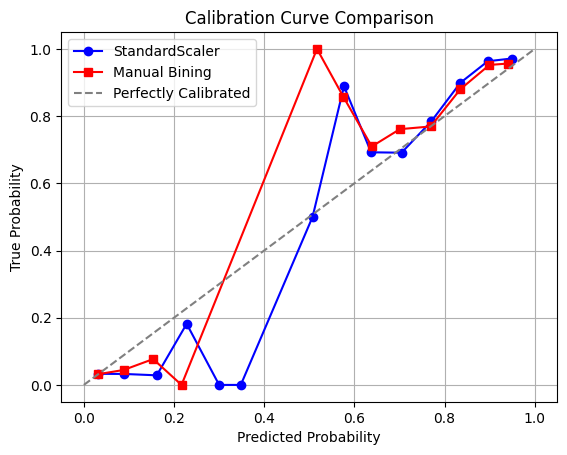

In [207]:
prob_true_std, prob_pred_std = calibration_curve(y_test, y_proba_std, 
                                                                 n_bins=15)
plt.plot(prob_pred_std, prob_true_std, 'o-', label='StandardScaler', 
                                                                 color='blue')

prob_true_bin, prob_pred_bin = calibration_curve(y_test, y_proba_bin, 
                                                                    n_bins=15)
plt.plot(prob_pred_bin, prob_true_bin, 's-', label='Manual Bining', 
                                                                 color='red')

plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly Calibrated')

plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')
plt.title('Calibration Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

Числовая оценка

In [208]:
brier_std = brier_score_loss(y_test, y_proba_std)
brier_bin = brier_score_loss(y_test, y_proba_bin)

print(f"Brier Score (Standard Scaler): {brier_std:.4f}")
print(f"Brier Score (Manual Bining): {brier_bin:.4f}")

Brier Score (Standard Scaler): 0.0480
Brier Score (Manual Bining): 0.0482


По качеству модель со стандартизацией показала лучшие результаты (PR AUC увеличился, калибровка стала лучше). Однако обе модели показали довольно плохую калибровку, что может быть вызвано малым числом клиентов в выборке

Рассмотрим основные метрики для модели со стандартизацией 

In [209]:
y_train_pred = calibrated_model.predict(X_train)
y_train_proba = calibrated_model.predict_proba(X_train)[:, 1]

y_test_pred = calibrated_model.predict(X_test)
y_test_proba = calibrated_model.predict_proba(X_test)[:, 1]

Оценка переобучения

In [210]:
print("===Оценка переобучения===")
print_scores("Train", y_train, y_train_pred, y_train_proba)
print_scores("Test", y_test, y_test_pred, y_test_proba)

===Оценка переобучения===

    Train -> PR AUC: 0.8341, ROC AUC: 0.9207, F1: 0.8379
    

    Test -> PR AUC: 0.8692, ROC AUC: 0.9331, F1: 0.8649
    


Все метрики на тесте

In [211]:
print("===Classification Report===")
print(classification_report(y_test, y_test_pred, target_names=['Not Churn', 
                                                                   'Churn']))

===Classification Report===
              precision    recall  f1-score   support

   Not Churn       0.97      0.97      0.97      2803
       Churn       0.87      0.86      0.86       686

    accuracy                           0.95      3489
   macro avg       0.92      0.92      0.92      3489
weighted avg       0.95      0.95      0.95      3489



Матрица ошибок

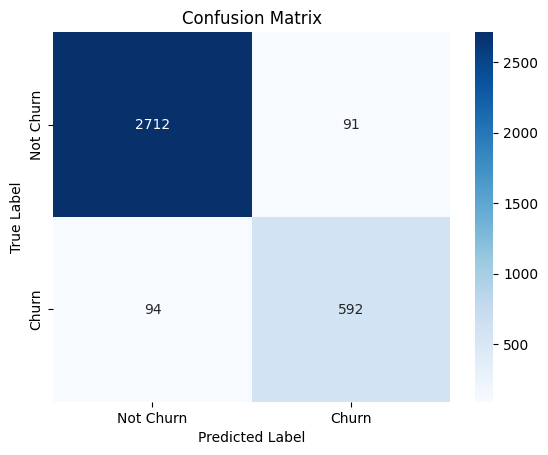

In [212]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Not Churn', 'Churn'],
           yticklabels=['Not Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

Важность признаков

In [213]:
feature_names = lr_grid.best_estimator_.named_steps[
                                    'preprocessing'].get_feature_names_out()
coef = lr_grid.best_estimator_.named_steps['classifier'].coef_[0]

#Создаем датафрейм
feat_imp = pd.DataFrame({
    'feature': feature_names,
    'coef': coef
}).sort_values('coef', key=abs, ascending=False)

print("===Топ-10 признаков по абсолютному коэффициенту===")
print(feat_imp.head(10))

===Топ-10 признаков по абсолютному коэффициенту===
                       feature      coef
13         remainder__Complain  3.254267
1                     num__Age  0.310544
12   remainder__IsActiveMember -0.213484
7         cat_nom__Gender_Male -0.165663
6     cat_nom__Geography_Spain -0.106631
5   cat_nom__Geography_Germany  0.097404
3         num__EstimatedSalary  0.077713
2                 num__Balance  0.071065
10    remainder__NumOfProducts -0.056927
4            num__Point Earned  0.028708


Выводы:
- Переобучения нет, модель даже лучше работает на тесте (значит обощается, предобработка и отбор признаков работают корректно)
- Модель сбалансирована (нет перекоса в сторону ложных срабатываний или пропусков)
- Сильнейший фактор - жалобы, активность снижает отток, возраст увеличивает отток, кол-во продуктов снижает отток, Испания стабильнее, Германия - рискованнее
- Далее в зависимости от цены ошибок (ложные срабатывания и пропуски) может быть выбран порог классификации для более оптимального решения

Бизнес интерпретация

In [214]:
n_total_churn = y_test.sum()
n_caught = ((y_test_pred == 1) & (y_test == 1)).sum()
n_targeted = y_test_pred.sum()

print('БИЗНЕС ОТЧЕТ')
print(f"Всего ушедших: {n_total_churn}")
print(f"Поймано: {n_caught} ({recall_score(y_test, y_test_pred):.1%})")
print(f"Всего на удержание: {n_targeted}")
print(f"Из них ушедших: {n_caught}" 
    f"({precision_score(y_test, y_test_pred):.1%})")
print(f"Средняя вероятность у охваченых:" 
    f"{y_test_proba[y_test_pred == 1].mean():.4f}")

БИЗНЕС ОТЧЕТ
Всего ушедших: 686
Поймано: 592 (86.3%)
Всего на удержание: 683
Из них ушедших: 592(86.7%)
Средняя вероятность у охваченых:0.8194


### Случайный лес

Предобработка

In [215]:
num_features = ['Age', 'Balance', 'EstimatedSalary', 'Point Earned', 'Tenure',
               'NumOfProducts']
cat_nominal = ['Geography', 'Gender']
cat_ordinal = ['Card Type']

card_order = [['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD']]

preprocessor_rf = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_features),
        ('cat_nom', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_nominal),
        ('cat_ord', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(categories=card_order, dtype=int))
        ]), cat_ordinal)
    ],
    remainder='passthrough'
)

Пайплайн

In [216]:
rf_pipe = Pipeline([
    ('preprocessing', preprocessor_rf),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)),
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

Поиск гиперпараметров

In [217]:
%%time
param_dist = {
    'feature_selection__k': randint(10, 15),
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': randint(2, 11),
    'classifier__min_samples_leaf': randint(1, 5),
    'classifier__max_features': ['sqrt', 'log2', 0.5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_search = RandomizedSearchCV(
    rf_pipe,
    param_distributions=param_dist,
    n_iter=100,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Лучшие параметры:")
print(rf_search.best_params_)
print(f"Лучший CV PR AUC: {rf_search.best_score_:.4f}")

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Лучшие параметры:
{'classifier__max_depth': 7, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 100, 'feature_selection__k': 10}
Лучший CV PR AUC: 0.8917
CPU times: user 4.57 s, sys: 444 ms, total: 5.02 s
Wall time: 3min 37s


Калибровка

In [218]:
calibrated_rf = CalibratedClassifierCV(
    rf_search.best_estimator_,
    method='isotonic',
    cv=3
)
calibrated_rf.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,method,'isotonic'
,cv,3
,n_jobs,None
,ensemble,'auto'
,transformers,"[('num', ...), ('cat_nom', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


Рассмотрим метрики на тесте

In [219]:
y_train_pred = calibrated_rf.predict(X_train)
y_train_proba = calibrated_rf.predict_proba(X_train)[:, 1]

y_test_pred = calibrated_rf.predict(X_test)
y_test_proba = calibrated_rf.predict_proba(X_test)[:, 1]

Оценка переобучения

In [220]:
print("===Оценка переобучения===")
print_scores("Train", y_train, y_train_pred, y_train_proba)
print_scores("Test", y_test, y_test_pred, y_test_proba)

===Оценка переобучения===

    Train -> PR AUC: 0.9258, ROC AUC: 0.9695, F1: 0.8510
    

    Test -> PR AUC: 0.9134, ROC AUC: 0.9603, F1: 0.8608
    


Все метрики

In [221]:
print("===Classification Report===")
print(classification_report(y_test, y_test_pred, target_names=['Not Churn', 
                                                                   'Churn']))

===Classification Report===
              precision    recall  f1-score   support

   Not Churn       0.96      0.98      0.97      2803
       Churn       0.89      0.83      0.86       686

    accuracy                           0.95      3489
   macro avg       0.93      0.90      0.91      3489
weighted avg       0.95      0.95      0.95      3489



Матрица ошибок

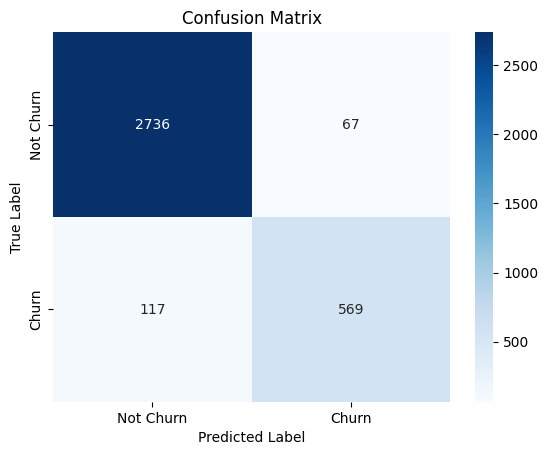

In [222]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Not Churn', 'Churn'],
           yticklabels=['Not Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

Калибровка

Значимость признаков

In [223]:
selected_features_mask = rf_search.best_estimator_.named_steps[
    'feature_selection'].get_support()

importances = rf_search.best_estimator_.named_steps[
    'classifier'].feature_importances_

feature_names = rf_search.best_estimator_.named_steps[
    'preprocessing'].get_feature_names_out()
selected_names = feature_names[selected_features_mask]

importance_df = pd.DataFrame({
    'feature': selected_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print(importance_df)

                      feature  importance
9         remainder__Complain    0.843642
0                    num__Age    0.062522
1                num__Balance    0.052080
2          num__NumOfProducts    0.022538
4  cat_nom__Geography_Germany    0.005162
8   remainder__IsActiveMember    0.004982
3   cat_nom__Geography_France    0.004204
6      cat_nom__Gender_Female    0.001709
7        cat_nom__Gender_Male    0.001666
5    cat_nom__Geography_Spain    0.001496


Опять видно, что главнй триггер оттока - наличие жалобы

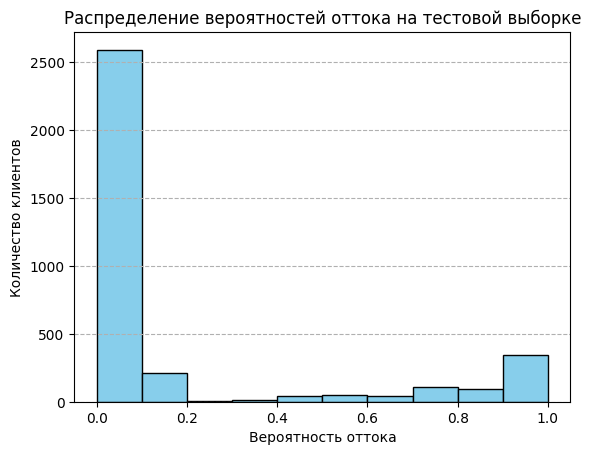

In [224]:
plt.figure()
plt.hist(y_test_proba, bins=10, color='skyblue', edgecolor='black')
plt.title('Распределение вероятностей оттока на тестовой выборке')
plt.xlabel('Вероятность оттока')
plt.ylabel('Количество клиентов')
plt.grid(axis='y', linestyle='--');

Модель уверенно разделяется клиентов на два класса

Итоги для случайного леса: 
- Модель почти не переобучена (разница между train и test около 0.01, что отлично для леса)
- Качество на тесте очень высокое (PR AUC > 0.91)
- Из 100 клиентов, для которых мы предсказали уход, 89 действительно уйдут, а из 100 уходящих мы нашли 83, f1-score = 0.86, что отражает отличныё баланс между precision и recall.
- Калибровочная кривая имеет значительные отклонения в средней зоне (0.2-0.6), но в области высоких вероятностей - близка к диагонали. Это не критично (важны высокие вероятности, то есть кто точно уйдет, а в средней зоне можно использовать дополнительные правила)

Бизнес-интерпретация

In [225]:
n_total_churn = y_test.sum()
n_caught = ((y_test_pred == 1) & (y_test == 1)).sum()
n_targeted = y_test_pred.sum()

print(f"Всего ушедших: {n_total_churn}")
print(f"Поймано: {n_caught} ({recall_score(y_test, y_test_pred):.1%})")
print(f"Всего на удержание: {n_targeted}")
print(f"Из них ушедших: {n_caught}" 
    f"({precision_score(y_test, y_test_pred):.1%})")
print(f"Средняя вероятность у охваченых:" 
    f"{y_test_proba[y_test_pred == 1].mean():.4f}")

Всего ушедших: 686
Поймано: 569 (82.9%)
Всего на удержание: 636
Из них ушедших: 569(89.5%)
Средняя вероятность у охваченых:0.8563


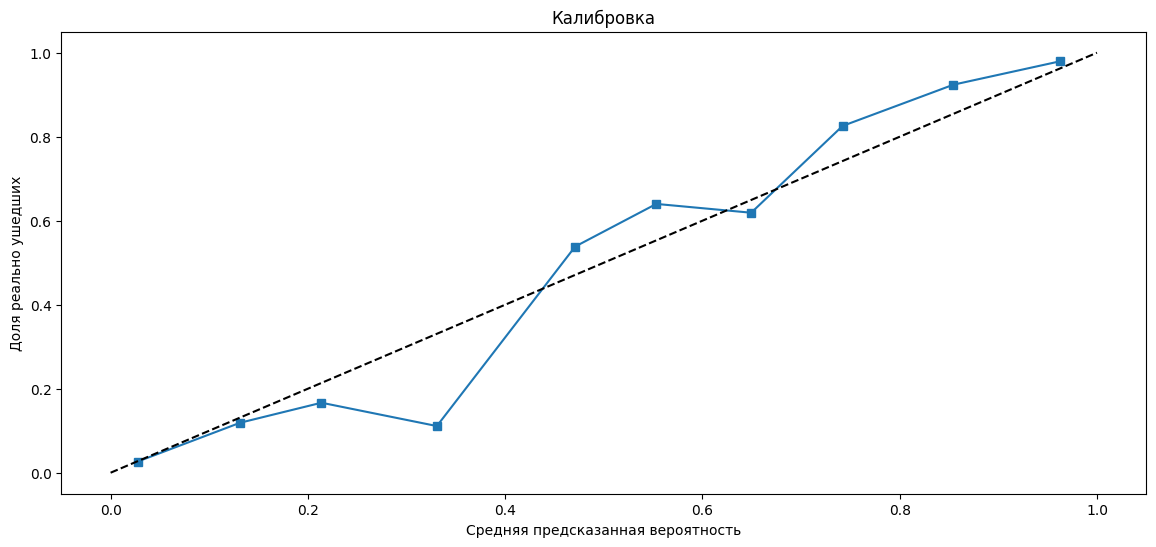

In [226]:
plt.figure(figsize=(14, 6))
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, y_test_proba, n_bins=10
)
plt.plot(mean_predicted_value, fraction_of_positives, 's-')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Калибровка')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Доля реально ушедших')
plt.show()

Рассмотрим PR-кривую

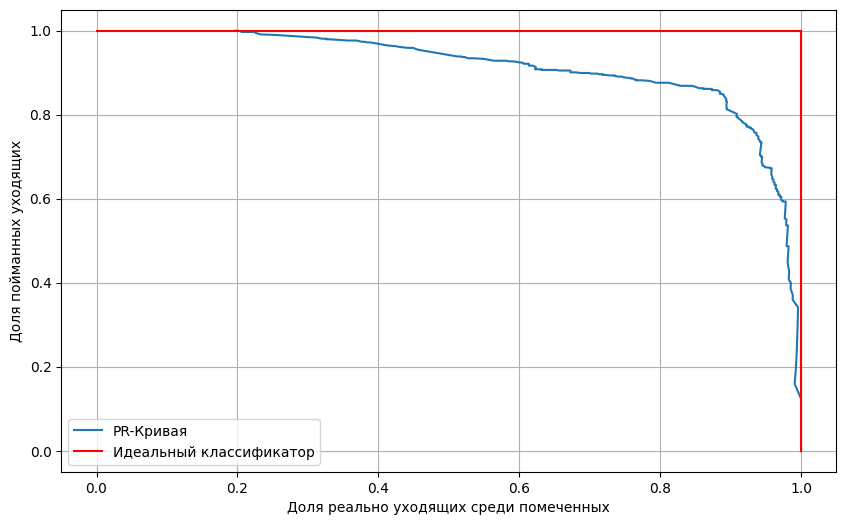

In [227]:
precision, recall, _ = precision_recall_curve(y_test, y_test_proba)

plt.figure(figsize=(10,6))
plt.plot(precision, recall)
plt.plot([0,1], [1,1], [1,1], [0,1], color='#ff0000')
plt.xlabel('Доля реально уходящих среди помеченных')
plt.ylabel('Доля пойманных уходящих')
plt.grid(True)
plt.legend(labels=['PR-Кривая', 'Идеальный классификатор'])
plt.title('');

### Сравнение логистической регрессии и случайного леса

In [228]:
models = [
    ('Логрег (стандартизация)', calibrated_model),
    ('Случайный лес', calibrated_rf)
]

results = []

for name, model in models:
    metrics = get_model_metrics(model, X_test, y_test)
    metrics['Модель'] = name
    results.append(metrics)

comparison = pd.DataFrame(results)
comparison.style.format(precision=3).set_caption('<b>Сравнение метрик:</b>')
print(comparison)

   Test PR AUC  Test ROC AUC  Precision    Recall                   Модель
0     0.869180      0.933084   0.866764  0.862974  Логрег (стандартизация)
1     0.913382      0.960336   0.894654  0.829446            Случайный лес


Сравним калибровку

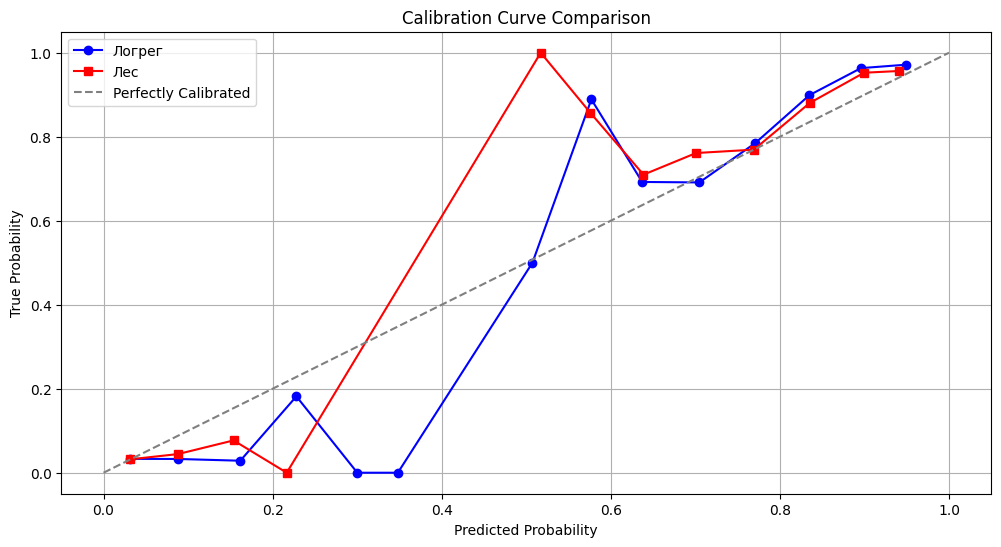

In [229]:
plt.figure(figsize=(12,6))

prob_true_std, prob_pred_std = calibration_curve(y_test, y_proba_std, 
                                                                 n_bins=15)
plt.plot(prob_pred_std, prob_true_std, 'o-', label='Логрег', 
                                                                 color='blue')

prob_true_rf, prob_pred_rf = calibration_curve(y_test, y_test_proba, 
                                                                    n_bins=15)
plt.plot(prob_pred_bin, prob_true_bin, 's-', label='Лес', 
                                                                 color='red')

plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly Calibrated')

plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')
plt.title('Calibration Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

Итоги сравнения:
- Логрег не переобучается и на тесте работает даже лучше, имеет более высокий recall, то есть ловит больше уходящих, дает более честные вероятности
- Случайный лес имеет лучшие метрики, немного переобучается, имеет больший precision, то есть меньше ложных срабатываний, но хуже калибровка

## Моделирование с обработкой выбросов и пропусков

In [230]:
data = pd.read_csv('clients.csv')

In [231]:
df = pd.DataFrame(data)

### Очистка

In [232]:
df.dtypes

Unnamed: 0                    int64
CreditScore                 float64
Geography                    object
Gender                       object
Age                           int64
Tenure                        int64
Balance                     float64
NumOfProducts                 int64
HasCrCard                     int64
IsActiveMember              float64
EstimatedSalary             float64
Exited                        int64
Complain                    float64
Satisfaction Score          float64
Card Type                    object
Point Earned                  int64
Missed_CreditScore            int64
Missed_IsActiveMember         int64
Missed_EstimatedSalary        int64
Complain_1                    int64
missed_complain               int64
missed_SatisfactionSCore      int64
AbnormalAge                   int64
NegativeSalary                int64
dtype: object

Всех тех клиентов, у которых были выбросы в графе "возраст", стоит удалить из датасета, чтобы модель не обучалась на таких выбросах, потому что это может навредить качеству

In [233]:
mask = df['AbnormalAge'] == 1

df = df.drop(df[mask].index)

Удалим признак AbnormalAge

In [234]:
df = df.drop('AbnormalAge', axis=1)

Далее рассмотрим признак NegativeSalary

In [235]:
df['NegativeSalary'].sum()

np.int64(75)

Всего 75 таких клиентов. Это выглядит просто как ошибка в данных, поэтому данный признак лучше удалить. Также стоит удалить клиентов с отрицательным доходом

In [236]:
mask = df['NegativeSalary'] == 1

df = df.drop(df[mask].index)

df = df.drop('NegativeSalary', axis=1)

Также среди клиентов с пропуском в признаке IsActiveMember доля оттока мала, а сам пропуск выглядит как техническая ошибка, поэтому можно было бы его удалить

In [237]:
df['Missed_IsActiveMember'].sum()

np.int64(670)

670 человек с пропусками

In [238]:
mask = df['Missed_IsActiveMember'] == 1

df = df.drop(df[mask].index)

df = df.drop('Missed_IsActiveMember', axis=1)

Проверим, сколько осталось людей с пропусакми в Complain и SatisfactionScore

In [239]:
print("Complain:", df['missed_complain'].sum())
print("SatisfactionScore:", df['missed_SatisfactionSCore'].sum())

Complain: 0
SatisfactionScore: 0


Поскольку в обоих признаках ноль клиентов, то они теперь являются бесполезными. Удалим их, тогда можно и удалить признак complain_1, так как он дублирует признак Complain

In [240]:
df = df.drop(['missed_complain', 'missed_SatisfactionSCore', 
                                                      'Complain_1'], axis=1)

Удалим признак Unnamed: 0 и изменим тип данных у тех float признаков, которые должны быть int

In [241]:
df = df.drop('Unnamed: 0', axis=1)

float_to_int = ['IsActiveMember', 'Complain', 'Satisfaction Score']

df[float_to_int] = df[float_to_int].astype(int)

После очистки проверим баланс классов

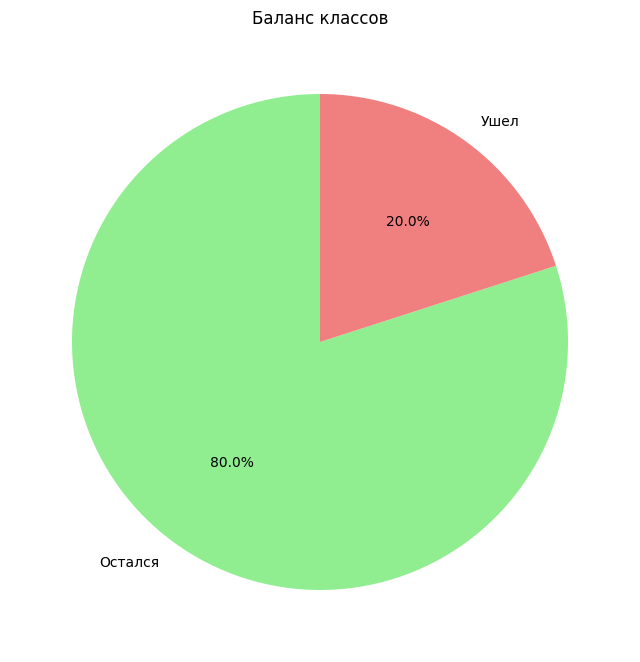

In [242]:
counts = df['Exited'].value_counts()
labels = ['Остался', 'Ушел']
colors = ['lightgreen', 'lightcoral']

plt.figure(figsize=(8, 10))
plt.pie(counts, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title("Баланс классов")
plt.show()

Видно, что баланс не изменился

Проверим общую информацию датасета после очистки

In [243]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,Missed_CreditScore,Missed_EstimatedSalary
0,709.0,France,Female,36,4,174056.41,1,1,1,40449.79,0,0,2,SILVER,752,0,0
1,534.0,France,Male,27,9,0.00,2,1,0,161344.13,0,0,2,PLATINUM,925,0,0
2,597.0,Spain,Male,24,0,108058.07,2,1,1,187826.11,0,0,3,PLATINUM,676,0,0
3,659.0,Germany,Female,26,9,84870.44,1,1,1,101371.05,0,0,4,DIAMOND,727,0,1
4,794.0,Spain,Female,28,5,0.00,2,0,1,86699.98,0,0,3,DIAMOND,734,0,0


In [244]:
df.tail()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,Missed_CreditScore,Missed_EstimatedSalary
19917,788.0,France,Male,34,1,64191.06,2,1,0,37217.73,1,0,3,DIAMOND,222,0,0
19918,576.0,France,Male,42,4,137429.76,2,0,0,137330.80,0,0,2,GOLD,740,0,0
19919,711.0,France,Female,29,3,130181.47,2,1,0,31811.44,0,0,5,SILVER,719,0,0
19920,647.0,Spain,Male,32,9,80958.36,1,1,1,128590.73,0,0,4,GOLD,540,0,0
19921,745.0,Germany,Male,29,10,0.00,1,1,0,124895.79,0,0,2,GOLD,207,0,0


In [245]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18086 entries, 0 to 19921
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CreditScore             18086 non-null  float64
 1   Geography               18086 non-null  object 
 2   Gender                  18086 non-null  object 
 3   Age                     18086 non-null  int64  
 4   Tenure                  18086 non-null  int64  
 5   Balance                 18086 non-null  float64
 6   NumOfProducts           18086 non-null  int64  
 7   HasCrCard               18086 non-null  int64  
 8   IsActiveMember          18086 non-null  int64  
 9   EstimatedSalary         18086 non-null  float64
 10  Exited                  18086 non-null  int64  
 11  Complain                18086 non-null  int64  
 12  Satisfaction Score      18086 non-null  int64  
 13  Card Type               18086 non-null  object 
 14  Point Earned            18086 non-null  int

Видно, что датасет больше не содержит пустых значений

Оценим размерность выборок и доли положительного класса целевого признака

In [246]:
comp = {
        'Размер': [X_train.shape[0], X_test.shape[0]],
        'Доля оттока': [y_train.mean(), y_test.mean()]
       }

comp_df = pd.DataFrame(comp, index=['Train', 'Test'])
print(comp_df)

       Размер  Доля оттока
Train   10467     0.196713
Test     3489     0.196618


Перейдем к моделированию

### Логистическая регрессия

Проведем разделение выборки

In [247]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [248]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

Сначала построим модель со стандартизацией, а затем с бинингом

#### Модель со стандартизацией

Проведем предобработку признаков

In [249]:
num_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary',
               'Point Earned']
cat_nominal = ['Geography', 'Gender']
cat_ordinal = ['Card Type']

card_order = [['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD']]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat_nom', OneHotEncoder(drop='first', handle_unknown='ignore'),
                                                                cat_nominal),
        ('cat_ord', OrdinalEncoder(categories=card_order, dtype=int),
                                                                cat_ordinal)
    ],
    remainder='passthrough'
)

Базовая модель

In [250]:
lr = LogisticRegression(
    class_weight='balanced',
    max_iter=10_000,
    random_state=42
)

Пайплайн (предобработка + модель)

In [251]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', lr)
])

Отбор признаков с помощью SFS

In [252]:
%%time
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scorer = make_scorer(average_precision_score, needs_proba=True)

#Список числа признаков для тестирования
k_values = [5, 10, 15]

results_sfs = {}

for k in k_values:
    print(f"Тестируем k={k} признаков...")

    #Создаем SFS
    sfs = SequentialFeatureSelector(
        clone(lr),
        n_features_to_select=k,
        direction='forward',
        cv=cv,
        scoring='average_precision',
        n_jobs=-1
    )

    #Обучаем SFS на Train
    sfs.fit(X_train_prep, y_train)

    #Применяем отбор
    X_train_selected = sfs.transform(X_train_prep)

    #Оцениваем качество на CV
    scores = cross_val_score(
        clone(lr), 
        X_train_selected, y_train, 
        cv=cv, 
        scoring='average_precision', 
        n_jobs=-1
    )

    results_sfs[k] = {
        'mean_pr_auc': scores.mean(),
        'std_pr_auc': scores.std(),
        'selector': sfs
    }

    print(f"PR AUC: {scores.mean():.4f} +- {scores.std():.4f}\n")

Тестируем k=5 признаков...
PR AUC: 0.7251 +- 0.0185

Тестируем k=10 признаков...
PR AUC: 0.7250 +- 0.0185

Тестируем k=15 признаков...
PR AUC: 0.7141 +- 0.0212

CPU times: user 5.26 s, sys: 459 ms, total: 5.71 s
Wall time: 20.7 s


k=5 и k=10 почти одинаковы по качеству

Рассмотрим, какие признаки отобраны при k=5 и k=10

In [253]:
sfs_5 = results_sfs[5]['selector']
sfs_10 = results_sfs[10]['selector']

feature_names = preprocessor.get_feature_names_out()

selected_mask_5 = sfs_5.get_support()
selected_mask_10 = sfs_10.get_support()

selected_features_5 = feature_names[selected_mask_5]
selected_features_10 = feature_names[selected_mask_10]

print("Отобранные признаки (5 шт.)")
for feat in selected_features_5:
    print(f" - {feat}")

print("\nОтобранные признаки (10 шт.)")
for feat in selected_features_10:
    print(f" - {feat}")

Отобранные признаки (5 шт.)
 - num__Age
 - num__Balance
 - cat_nom__Gender_Male
 - remainder__IsActiveMember
 - remainder__Complain

Отобранные признаки (10 шт.)
 - num__CreditScore
 - num__Age
 - num__Balance
 - num__Point Earned
 - cat_nom__Gender_Male
 - cat_ord__Card Type
 - remainder__NumOfProducts
 - remainder__IsActiveMember
 - remainder__Complain
 - remainder__Satisfaction Score


Стоит взять модель с 10 признаками, потому что она более стабильная, включает важные бизнес-факторы (CreditScore, NumOfProducts, Satisfaction Score), но качество почти такое же, как у модели с 5 признаками

In [254]:
best_k = 10
best_sfs = results_sfs[best_k]['selector']

print(f"Лучшее k: {best_k} (PR AUC = "
                    f"{results_sfs[best_k]['mean_pr_auc']:.4f})")

Лучшее k: 10 (PR AUC = 0.7250)


Проведем отбор признаков

In [255]:
X_train_selected = X_train_prep[:, selected_mask_10]
X_test_selected = X_test_prep[:, selected_mask_10]

Подбор гиперпараметров

In [256]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    lr, param_grid,
    scoring='average_precision',
    cv=cv_inner,
    n_jobs=-1
)
grid_search.fit(X_train_selected, y_train)

print(f"Лучший C: {grid_search.best_params_['C']}")
print(f"лучший CV PR AUC: {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_

Лучший C: 0.01
лучший CV PR AUC: 0.7256


Калибровка

In [257]:
calibrated_model = CalibratedClassifierCV(
    best_model,
    method='isotonic',
    cv=3
)
calibrated_model.fit(X_train_selected, y_train)

,estimator,LogisticRegre...ndom_state=42)
,method,'isotonic'
,cv,3
,n_jobs,None
,ensemble,'auto'
,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.01
,fit_intercept,True
,intercept_scaling,1


Тепер построим модель с бинингом

#### Модель с бинингом

Собираем пайплайн предобработки

In [258]:
bining_pipe = Pipeline([
    ('manual_bining', FunctionTransformer(manual_bining, validate=False))
])

ordinal_features = {
    'age_bin': ['<30', '30-40', '40-45', '45-65', '65+'],
    'balance_bin': ['0', '<25k', '25k-75k', '75k-125k', '125k-150k',
                                                        '150k-200k', '200k+'],
    'credit_score_bin': ['<500', '500-600', '600-670', '670-700', '700-800', 
                                                                    '800+'],
    'salary_bin': ['<1k', '1k-10k', '10k-50k', '50k-100k', '100k-150k', 
                                                        '150k-200k', '200k+'],
    'point_bin': ['<200', '200-400', '400-600', '600-800', '800+'],
    'Card Type': ['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD']
}

transformers = []
for col, cats in ordinal_features.items():
    transformers.append(
        (col, OrdinalEncoder(categories=[cats], dtype=int), [col])
    )

#Номинальные признаки
nominal_features = ['Geography', 'Gender']
transformers.append(
    ('nominal', OneHotEncoder(drop='first', handle_unknown='ignore'), 
                                                         nominal_features)
)

preprocessor_bin = ColumnTransformer(
    transformers=transformers,
    remainder='passthrough',
    verbose_feature_names_out=False
)

Соберем полный пайплайн предобработки

In [259]:
preprocessor_bin_pipe = Pipeline([
    ('binnig', bining_pipe),
    ('preprocessing', preprocessor_bin),
])

Базовая модель

In [260]:
lr_bin = LogisticRegression(
    class_weight='balanced',
    max_iter=10_000,
    random_state=42
)

Отбор признаков с помощью SFS

In [261]:
%%time
X_train_prep_bin = preprocessor_bin_pipe.fit_transform(X_train)
X_test_prep_bin = preprocessor_bin_pipe.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Список числа признаков для тестирования
k_values = [5, 10, 15]

results_sfs_bin = {}

for k in k_values:
    print(f"Тестируем k={k} признаков...")

    #Создаем SFS
    sfs = SequentialFeatureSelector(
        clone(lr_bin),
        n_features_to_select=k,
        direction='forward',
        cv=cv,
        scoring='average_precision',
        n_jobs=-1
    )

    #Обучаем SFS на Train
    sfs.fit(X_train_prep_bin, y_train)

    #Применяем отбор
    X_train_selected_bin = sfs.transform(X_train_prep_bin)

    #Оцениваем качество на CV
    scores = cross_val_score(
        clone(lr_bin), 
        X_train_selected_bin, y_train, 
        cv=cv, 
        scoring='average_precision', 
        n_jobs=-1
    )

    results_sfs_bin[k] = {
        'mean_pr_auc': scores.mean(),
        'std_pr_auc': scores.std(),
        'selector': sfs
    }

    print(f"PR AUC: {scores.mean():.4f} +- {scores.std():.4f}\n")

Тестируем k=5 признаков...
PR AUC: 0.7236 +- 0.0133

Тестируем k=10 признаков...
PR AUC: 0.7214 +- 0.0170

Тестируем k=15 признаков...
PR AUC: 0.7097 +- 0.0230

CPU times: user 5.86 s, sys: 465 ms, total: 6.33 s
Wall time: 23.6 s


При k=5 больше pr auc

Рассмотрим, какие признаки явяются лучшими в каждом из случаев

In [262]:
sfs_5 = results_sfs_bin[5]['selector']
sfs_10 = results_sfs_bin[10]['selector']

feature_names_bin = preprocessor_bin_pipe.named_steps[
                                    'preprocessing'].get_feature_names_out()

selected_mask_5 = sfs_5.get_support()
selected_mask_10 = sfs_10.get_support()

selected_features_5 = feature_names_bin[selected_mask_5]
selected_features_10 = feature_names_bin[selected_mask_10]

print("Отобранные признаки (5 шт.)")
for feat in selected_features_5:
    print(f" - {feat}")

print("\nОтобранные признаки (10 шт.)")
for feat in selected_features_10:
    print(f" - {feat}")

Отобранные признаки (5 шт.)
 - age_bin
 - Gender_Male
 - IsActiveMember
 - Complain
 - Satisfaction Score

Отобранные признаки (10 шт.)
 - age_bin
 - point_bin
 - Card Type
 - Geography_Spain
 - Gender_Male
 - NumOfProducts
 - HasCrCard
 - IsActiveMember
 - Complain
 - Satisfaction Score


Здесь ситуация аналогичная предыдущему случаю, поэтому выберем 10 признаков

In [263]:
best_k_bin = 10
best_sfs_bin = results_sfs_bin[best_k_bin]['selector']

print(f"Лучшее k: {best_k_bin} (PR AUC = "
                    f"{results_sfs_bin[best_k_bin]['mean_pr_auc']:.4f})")

Лучшее k: 10 (PR AUC = 0.7214)


Проведем отбор признаков

In [264]:
X_train_selected_bin = X_train_prep_bin[:, selected_mask_10]
X_test_selected_bin = X_test_prep_bin[:, selected_mask_10]

Подберем гиперпараметры

In [265]:
%%time
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search_bin = GridSearchCV(
    lr_bin, param_grid,
    scoring='average_precision',
    cv=cv_inner,
    n_jobs=-1
)
grid_search_bin.fit(X_train_selected_bin, y_train)

print(f"Лучший C: {grid_search_bin.best_params_['C']}")
print(f"лучший CV PR AUC: {grid_search_bin.best_score_:.4f}")

best_model_bin = grid_search_bin.best_estimator_

Лучший C: 0.01
лучший CV PR AUC: 0.7239
CPU times: user 661 ms, sys: 7.46 ms, total: 668 ms
Wall time: 434 ms


Калибровка

In [266]:
calibrated_model_bin = CalibratedClassifierCV(
    best_model_bin,
    method='isotonic',
    cv=3
)
calibrated_model_bin.fit(X_train_selected_bin, y_train)

,estimator,LogisticRegre...ndom_state=42)
,method,'isotonic'
,cv,3
,n_jobs,None
,ensemble,'auto'
,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.01
,fit_intercept,True
,intercept_scaling,1


Сравним теперь между собой модель с бинингом и со стандартизацией

Сравнение на кросс-валидации

In [267]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

score_std = cross_validate(
    calibrated_model, X_train_selected, y_train,
    cv=cv,
    scoring = 'average_precision',
    n_jobs=-1
)

score_bin = cross_validate(
    calibrated_model_bin, X_train_selected_bin, y_train,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1
)

print(f"LogReg (std): {score_std['test_score'].mean():.4f} +-" 
                f"{score_std['test_score'].std():.4f}")
print(f"LogReg (bin): {score_bin['test_score'].mean():.4f} +-" 
                f"{score_bin['test_score'].std():.4f}")

LogReg (std): 0.7191 +-0.0174
LogReg (bin): 0.7182 +-0.0138


Метрики отличаются не очень сильно, но модель с бинингом является более устойчивой

Теперь сравним калибровку

In [268]:
y_proba_std = calibrated_model.predict_proba(X_test_selected)[:, 1]
y_proba_bin = calibrated_model_bin.predict_proba(X_test_selected_bin)[:, 1]

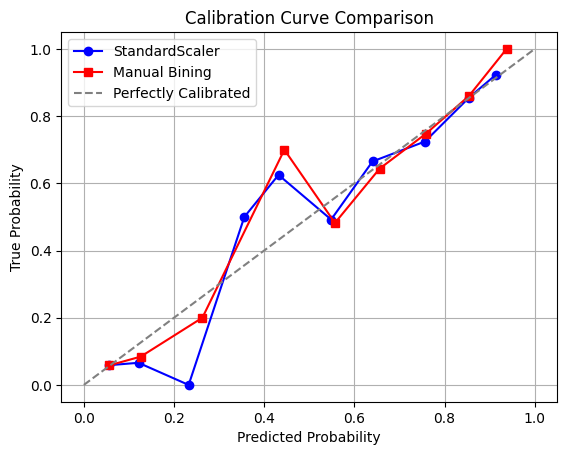

In [269]:
prob_true_std, prob_pred_std = calibration_curve(y_test, y_proba_std, 
                                                                 n_bins=10)
plt.plot(prob_pred_std, prob_true_std, 'o-', label='StandardScaler', 
                                                                 color='blue')

prob_true_bin, prob_pred_bin = calibration_curve(y_test, y_proba_bin, 
                                                                    n_bins=10)
plt.plot(prob_pred_bin, prob_true_bin, 's-', label='Manual Bining', 
                                                                 color='red')

plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly Calibrated')

plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')
plt.title('Calibration Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()

Числовая оценка

In [270]:
brier_std = brier_score_loss(y_test, y_proba_std)
brier_bin = brier_score_loss(y_test, y_proba_bin)

print(f"Brier Score (Standard Scaler): {brier_std:.4f}")
print(f"Brier Score (Manual Bining): {brier_bin:.4f}")

Brier Score (Standard Scaler): 0.0833
Brier Score (Manual Bining): 0.0827


Грфик калибровки, а также числовая оценка явно лучше у модели с бинингом, поэтому из двух моделей стоит выбрать именно ее

Оценим модель с бинингом на тесте

In [271]:
y_train_pred_bin = calibrated_model_bin.predict(X_train_selected_bin)
y_train_proba_bin = calibrated_model_bin.predict_proba(
                                                X_train_selected_bin)[:, 1]

y_test_pred_bin = calibrated_model_bin.predict(X_test_selected_bin)
y_test_proba_bin = calibrated_model_bin.predict_proba(
                                                X_test_selected_bin)[:, 1]

Оценка переобучения

In [272]:
print("===Оценка переобучения===")
print_scores("Train", y_train, y_train_pred_bin, y_train_proba_bin)
print_scores("Test", y_test, y_test_pred_bin, y_test_proba_bin)

===Оценка переобучения===

    Train -> PR AUC: 0.7238, ROC AUC: 0.8748, F1: 0.7497
    

    Test -> PR AUC: 0.7248, ROC AUC: 0.8677, F1: 0.7418
    


Все метрики на тесте

In [273]:
print("===Classification Report===")
print(classification_report(y_test, y_test_pred_bin, target_names=[
                                                    'Not Churn', 'Churn']))

===Classification Report===
              precision    recall  f1-score   support

   Not Churn       0.94      0.93      0.93      3616
       Churn       0.72      0.76      0.74       906

    accuracy                           0.89      4522
   macro avg       0.83      0.84      0.84      4522
weighted avg       0.90      0.89      0.89      4522



Матрица ошибок

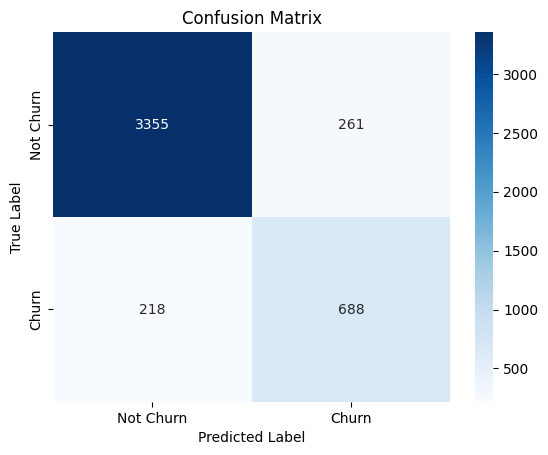

In [274]:
cm = confusion_matrix(y_test, y_test_pred_bin)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Not Churn', 'Churn'],
           yticklabels=['Not Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

Кривые обучения

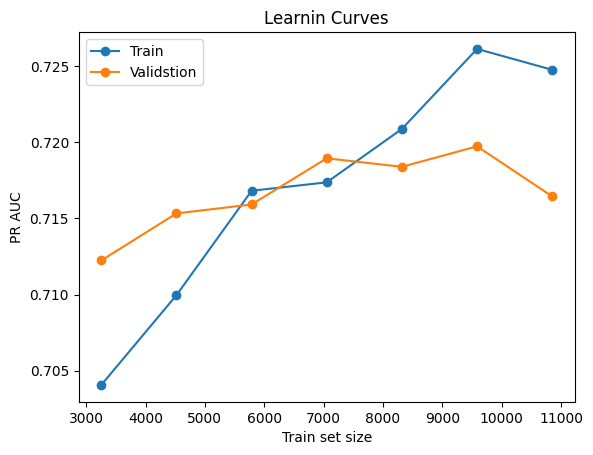

In [275]:
train_sizes, train_scores, val_scores = learning_curve(
    calibrated_model_bin, X_train_selected_bin, y_train,
    cv=5,
    scoring='average_precision',
    n_jobs=-1,
    train_sizes=np.linspace(0.3, 1.0, 7)
)

plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validstion')
plt.xlabel('Train set size')
plt.ylabel('PR AUC')
plt.legend()
plt.title('Learnin Curves')
plt.show()

Итоги для логистической регрессии:
- Модель не переобучена (качество на тесте даже немного выше), хорошо обобщается.
- Recall = 0.76 (из 100 уходящих нашли 76, то есть программа удержания охватит большинство)
- Precision = 0.72 (из 100 предсказанных "уходящими" 72 действительно уйдут)
- Кривые обучения: обе кривые растут с увеличением размера обучающей выборки -> модель учиться, и чем больше данных - тем лучше качество. После 6-7 тысяч наблюдение кривые пересекаются, а после этого train > val - это нормально, что модель лучше работает на тех данных, на которых обучалась. Разрыв между train и val небольшой - переобучение минимально. При увеличении размера выборки до 11 тысяч качество немного падает (возможно последние 1000 наблюдений содкржат более шумные или сложные примеры либо модель достигла предела, и добавление новых данных не дает прироста)

Бизнес интерпретация

In [276]:
n_total_churn = y_test.sum()
n_caught = ((y_test_pred_bin == 1) & (y_test == 1)).sum()
n_targeted = y_test_pred_bin.sum()

print('БИЗНЕС ОТЧЕТ')
print(f"Всего ушедших: {n_total_churn}")
print(f"Поймано: {n_caught} ({recall_score(y_test, y_test_pred_bin):.1%})")
print(f"Всего на удержание: {n_targeted}")
print(f"Из них ушедших: {n_caught}" 
    f"({precision_score(y_test, y_test_pred_bin):.1%})")
print(f"Средняя вероятность у охваченых:" 
    f"{y_test_proba_bin[y_test_pred_bin == 1].mean():.4f}")

БИЗНЕС ОТЧЕТ
Всего ушедших: 906
Поймано: 688 (75.9%)
Всего на удержание: 949
Из них ушедших: 688(72.5%)
Средняя вероятность у охваченых:0.7369


### Случайный лес

Предобработка

In [277]:
num_features = ['Age', 'Balance', 'EstimatedSalary', 'Point Earned', 'Tenure',
               'NumOfProducts']
cat_nominal = ['Geography', 'Gender']
cat_ordinal = ['Card Type']

card_order = [['SILVER', 'PLATINUM', 'DIAMOND', 'GOLD']]

preprocessor_rf = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_features),
        ('cat_nom', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_nominal),
        ('cat_ord', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(categories=card_order, dtype=int))
        ]), cat_ordinal)
    ],
    remainder='passthrough'
)

Применим предобработку

In [278]:
X_train_prep_rf = preprocessor.fit_transform(X_train)
X_test_prep_rf = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

Базовая модель

In [279]:
rf_base = RandomForestClassifier(
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

Подбор признаков с помощью SFS

In [280]:
%%time
k_values = [5, 10, 15]

results_sfs_rf = {}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for k in k_values:
    print(f"\nТестируем k={k} признаков...")

    #Обучаем sfs
    sfs = SequentialFeatureSelector(
        clone(rf_base),
        n_features_to_select=k,
        direction='forward',
        cv=2,
        scoring='average_precision',
        n_jobs=-1
    )
    sfs.fit(X_train_prep_rf, y_train)

    #применяем отбор
    X_train_selected = sfs.transform(X_train_prep_rf)

    scores = cross_val_score(
        clone(rf_base),
        X_train_selected, y_train,
        cv=cv,
        scoring='average_precision',
        n_jobs=-1
    )

    results_sfs_rf[k] = {
        'mean_pr_auc': scores.mean(),
        'std_pr_auc': scores.std(),
        'selector': sfs
    }

    print(f"PR AUC: {scores.mean():.4f} +- {scores.std():.4f}")


Тестируем k=5 признаков...
PR AUC: 0.7444 +- 0.0070

Тестируем k=10 признаков...
PR AUC: 0.8096 +- 0.0017

Тестируем k=15 признаков...
PR AUC: 0.8119 +- 0.0033
CPU times: user 4.15 s, sys: 375 ms, total: 4.53 s
Wall time: 5min 11s


Модель с 15 признаками показывает лучшие результаты по метрике и по стабильности, выбираем ее

In [281]:
best_k_rf = 15
best_sfs_rf = results_sfs_rf[best_k_rf]['selector']
X_train_selected_rf = best_sfs_rf.transform(X_train_prep_rf)
X_test_selected_rf = best_sfs_rf.transform(X_test_prep_rf)

Подбор гиперпараметров

In [ ]:
%%time
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 7, 10, 15, None],
    'min_samples_split': [10, 15, 20],
    'min_samples_leaf': [10, 15, 20],
    'max_features': ['sqrt', 'log2', 0.5]
}

cv_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf_search = RandomizedSearchCV(
    rf_base,
    param_distributions=param_dist,
    n_iter=100,
    scoring='average_precision',
    cv=cv_inner,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train_selected_rf, y_train)

print("Лучшие параметры")
print(rf_search.best_params_)
print(f"\nЛучшая CV PR AUC: {rf_search.best_score_:.4f}")

Калибровка

In [ ]:
calibrated_rf = CalibratedClassifierCV(
    rf_search.best_estimator_,
    method='isotonic',
    cv=3
)
calibrated_rf.fit(X_train_selected_rf, y_train)

Оценка на тесте

In [ ]:
y_train_pred_rf = calibrated_rf.predict(X_train_selected_rf)
y_train_proba_rf = calibrated_rf.predict_proba(X_train_selected_rf)[:, 1]

y_test_pred_rf = calibrated_rf.predict(X_test_selected_rf)
y_test_proba_rf = calibrated_rf.predict_proba(X_test_selected_rf)[:, 1]

Оценка переобучения

In [ ]:
print("===Оценка переобучения===")
print_scores("Train", y_train, y_train_pred_rf, y_train_proba_rf)
print_scores("Test", y_test, y_test_pred_rf, y_test_proba_rf)

Все метрики на тесте

In [ ]:
print("===Classification Report===")
print(classification_report(y_test, y_test_pred_rf, target_names=[
                                                    'Not Churn', 'Churn']))

Матрица ошибок

In [ ]:
cm = confusion_matrix(y_test, y_test_pred_rf)
plt.figure()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels=['Not Churn', 'Churn'],
           yticklabels=['Not Churn', 'Churn'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

Рассмотрим калибровочную кривую

In [ ]:
plt.figure(figsize=(14, 6))
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, y_test_proba_rf, n_bins=10
)
plt.plot(mean_predicted_value, fraction_of_positives, 's-')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('Калибровка')
plt.xlabel('Средняя предсказанная вероятность')
plt.ylabel('Доля реально ушедших')
plt.show()

Кривые обучения

In [ ]:
%%time
train_sizes, train_scores, val_scores = learning_curve(
    calibrated_rf, X_train_selected_rf, y_train,
    cv=5,
    scoring='average_precision',
    n_jobs=-1,
    train_sizes=np.linspace(0.3, 1.0, 7)
)

plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validstion')
plt.xlabel('Train set size')
plt.ylabel('PR AUC')
plt.legend()
plt.title('Learnin Curves')
plt.show()

Рассмотрим важность признаков

In [ ]:
selected_features_mask = best_sfs_rf.get_support()

importances = rf_search.best_estimator_.feature_importances_

feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_features_mask]

importance_df = pd.DataFrame({
    'feature': selected_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

print(importance_df)

Итоги для случайного леса:
- Модель слегка переобучается (разница между train и test около 0.03), что может быть нормально для случайного леса
- Recall = 0.65 (65 из 100 ушедших находим), Precision = 0.84 (из 100, отмеченных ушедшими 84 действительно ими являются)
- Модель показала хорошую калибровку

### Сравнение логрега и случайного леса

Сравнение:
- Модель логистической регрессии не переобучается, хорошо обощается, имеет больший recall и precision
- Модель случайного леса имеет лучшую калибровку, немного переобучается (но не критично)

Дальнейший выбор модели зависит от конкретных задач

## Итоги моделирования

Модели, для которых удаляли пропуски и выбросы показали себя намного лучше (данные более чистые и модели не подстраиваются под шум и выбросы).

Таким образом лучше выбрать модели с удалением пропусков и выбросов. 

Далее следует выбрать между логистической регрессией и случайным лесом:
- Если критично не пропустить уходящих, а также важна лучшая калибровка и интерпретация, то лучше выбрать логрег
- Если же критично не тратить деньги на лояльных (которых модель отметила как уходящих), то лучше выбрать случайный лес

# Финальный отчет

Целью проекта была разработка модели для прогнозирования вероятности ухода клиента из банка, а также описание наиболее лояльных и наиболее склонных к уходу клиентов, проведение исследовательского анализа и выработка рекомендаций по удержанию клиентов

Исходный датасет содержал 20000 записей клиентов и включал:
- демографические признаки (возраст, страна, пол)
- банковские характеристики (баланс, прогнозируемый доход, количество продуктов, активность, кредитный рейтинг, наличие и тип кредитной карты, стаж)
- информаию об удовлетворенности (жалоба, оценка удовлетворенности)
- целевая переменная (Exited)

Предобрабботка:
- Пропуски в чсловых признаках были заменены медианой, и был добавлен флаг пропуска
- Пропуски в категориальных признаках были удалены
- Аномалии в возрасте были обрезаны на значении 10, а также был введен флаг аномального возраста
- Были выявлены клиенты с отрицательным доходом (замена на медиану и флаг)


Разведочный анализ:
- Классы были несбалансированы (20% оттока)
- Главный драйвер оттока - наличие жалобы
- Возрастная группа риска - 45-65  лет

Моделирование.

Подход:
- Разделение данных со стратификацией для учета дисбаланса
- Метрики оценки: ROC AUC, PR AUC, precision, recall, матрица ошибок, калибровочные кривые

Выбор модели:
- Основная метрика для выбора - PR AUC
- Лучшие результаты показали модели, для которых была применена стратегия удаления пропсуков и выбросов
- Для моделей с удалением пропусков и выбросов выбор между логистической регрессией и случайным лесом зависит от конкретных задач бизнеса (минимизация ложных срабатываний либо пропустить меньше уходящих и получить более интерпретируемую модель)

Рекомендации для маркетинга:
- Улучшить обработку жалоб клиентов (теряем очень много клиентов с жалобой)
- Разработать специальные продукты или упростить в пользовании, или помочь правильно пользоваться данными продуктами клиентам старшей возрастной группы
- Запустить кампании по вовлечению клиентов, которые являются неактивными

Проект реализован: построена модели с высокой предсказательной способностью, составлены наиболее вероятные портреты клиентов, склонных к оттоку, а также разработаны практически применимые рекомендации.